# Informe de benchmarking: segundo parcial GPU (Equipetrol Delivery)

Tablas y figuras de las secciones 2.4 a 2.6 del enunciado, calculadas con `report_lib.py` a partir del CSV del
modo bench (`delivery_sim <config> --headless --bench results.csv`) y de su `results.csv.env.json`.

- Ejecutar de punta a punta: `jupyter nbconvert --to notebook --execute --inplace analysis/informe.ipynb`
- Otro CSV: variable de entorno `INFORME_CSV` (varios separados por `;`); carpeta de figuras: `INFORME_FIG_DIR`.
- Sin Jupyter: `python analysis/generar_informe.py` (mismas tablas en `analysis/informe_tablas.md`).
- Todo se midió en la misma laptop (CPU y GPU); donde el enunciado dice Colab se usa esta máquina (2.3 admite
  "your own computer if it has an NVIDIA GPU").

In [1]:
import os
import sys
from pathlib import Path

HERE = Path.cwd()
if not (HERE / "report_lib.py").exists() and (HERE / "analysis" / "report_lib.py").exists():
    HERE = HERE / "analysis"
sys.path.insert(0, str(HERE))

import pandas as pd
from IPython.display import Image, Markdown, display

import report_lib as rl

DEFAULT = ";".join(str(p) for p in sorted((HERE / "data" / "final").glob("*/bench.csv")))
CSV = [Path(p) for p in os.environ.get("INFORME_CSV", DEFAULT).split(";")]
FIG_DIR = Path(os.environ.get("INFORME_FIG_DIR", str(HERE / "figures")))
CONFIG = os.environ.get("INFORME_CONFIG", "config/ciudad.json")
KERNELS = rl.load_kernels(HERE / "kernels.json")

ds = rl.load(CSV)
summ = rl.summarize(ds.df)
cmp = rl.compare_all(summ, KERNELS)
lines = []
for p in CSV:
    lines.append(f"- **CSV:** `{rl.display_path(p)}` ({len(ds.df)} filas)")
    lines.append(f"- **Comando que lo produjo** (reconstruido del env.json): `{rl.run_command(ds.env, p, CONFIG)}`")
if ds.env.get("synthetic"):
    lines.append("- **Datos SINTÉTICOS**: solo prueban el pipeline, no son mediciones.")
display(Markdown("\n".join(lines)))

- **CSV:** `analysis/data/final/apsp/bench.csv` (9320 filas)
- **Comando que lo produjo** (reconstruido del env.json): `./delivery_sim config/ciudad.json --headless --bench bench.csv --force --apps apsp_floyd,apsp_dijkstra`
- **CSV:** `analysis/data/final/best_courier/bench.csv` (9320 filas)
- **Comando que lo produjo** (reconstruido del env.json): `./delivery_sim config/ciudad.json --headless --bench bench.csv --force --apps apsp_floyd,apsp_dijkstra`
- **CSV:** `analysis/data/final/calib/bench.csv` (9320 filas)
- **Comando que lo produjo** (reconstruido del env.json): `./delivery_sim config/ciudad.json --headless --bench bench.csv --force --apps apsp_floyd,apsp_dijkstra`
- **CSV:** `analysis/data/final/candidate_filter/bench.csv` (9320 filas)
- **Comando que lo produjo** (reconstruido del env.json): `./delivery_sim config/ciudad.json --headless --bench bench.csv --force --apps apsp_floyd,apsp_dijkstra`
- **CSV:** `analysis/data/final/coverage_field/bench.csv` (9320 filas)
- **Comando que lo produjo** (reconstruido del env.json): `./delivery_sim config/ciudad.json --headless --bench bench.csv --force --apps apsp_floyd,apsp_dijkstra`
- **CSV:** `analysis/data/final/delivery_histogram/bench.csv` (9320 filas)
- **Comando que lo produjo** (reconstruido del env.json): `./delivery_sim config/ciudad.json --headless --bench bench.csv --force --apps apsp_floyd,apsp_dijkstra`
- **CSV:** `analysis/data/final/delivery_percentiles/bench.csv` (9320 filas)
- **Comando que lo produjo** (reconstruido del env.json): `./delivery_sim config/ciudad.json --headless --bench bench.csv --force --apps apsp_floyd,apsp_dijkstra`
- **CSV:** `analysis/data/final/delivery_timeline/bench.csv` (9320 filas)
- **Comando que lo produjo** (reconstruido del env.json): `./delivery_sim config/ciudad.json --headless --bench bench.csv --force --apps apsp_floyd,apsp_dijkstra`
- **CSV:** `analysis/data/final/demand_heatmap/bench.csv` (9320 filas)
- **Comando que lo produjo** (reconstruido del env.json): `./delivery_sim config/ciudad.json --headless --bench bench.csv --force --apps apsp_floyd,apsp_dijkstra`
- **CSV:** `analysis/data/final/eta_batch/bench.csv` (9320 filas)
- **Comando que lo produjo** (reconstruido del env.json): `./delivery_sim config/ciudad.json --headless --bench bench.csv --force --apps apsp_floyd,apsp_dijkstra`
- **CSV:** `analysis/data/final/orders_in_progress/bench.csv` (9320 filas)
- **Comando que lo produjo** (reconstruido del env.json): `./delivery_sim config/ciudad.json --headless --bench bench.csv --force --apps apsp_floyd,apsp_dijkstra`

## Validación (sección 2.2)

In [2]:
if ds.issues:
    display(pd.DataFrame([(i.level, i.app or "—", i.message) for i in ds.issues], columns=["Nivel", "Aplicación", "Detalle"]))
else:
    display(Markdown("Sin incumplimientos: columnas exactas, ninguna fila `correct=no`, ≥ 10 repeticiones por grupo, "
                     "≥ 5 tamaños y ≥ 2 órdenes de magnitud por aplicación, build Release."))

,Nivel,Aplicación,Detalle
0,aviso,apsp_dijkstra,"faltan versiones ['gpu_kernel', 'gpu_e2e'] (la..."
1,aviso,best_courier_divergent,faltan versiones ['cpuN'] (la tabla de 2.4 que...
2,info,calib_launch,gpu_e2e sin h2d_ms/kernel_ms/d2h_ms: no se pue...
3,aviso,candidate_filter_naive,faltan versiones ['cpuN'] (la tabla de 2.4 que...
4,aviso,histogram_naive,"faltan versiones ['cpu1', 'cpuN'] (la tabla de..."
5,aviso,eta_batch_aos,faltan versiones ['cpuN'] (la tabla de 2.4 que...


## Set-up (del env.json)

In [3]:
display(Markdown(rl.markdown_table(rl.setup_table(ds.env))))

| Dato | Valor |
|---|---|
| CPU | 13th Gen Intel(R) Core(TM) i7-13620H |
| Hilos lógicos (hardware_concurrency) | 16 |
| Núcleos físicos (env.json, /proc/cpuinfo de WSL) | 8 |
| Núcleos P / E (fabricante) | 6 P + 4 E = 10 (Intel ARK i7-13620H: 6 nucleos P (2 hilos c/u) + 4 nucleos E = 10 nucleos, 16 hilos) |
| Memoria visible | 9.7 GiB |
| Sistema operativo | Linux 6.6.87.2-microsoft-standard-WSL2 |
| GPU | NVIDIA GeForce RTX 4050 Laptop GPU |
| Compute capability / SMs | 8.9 / 20 |
| Memoria de la GPU | 6.00 GiB |
| Reloj SM (máx.) | 2.355 GHz |
| Memoria: reloj / bus | 8.001 GHz / 96 bits |
| Ancho de banda pico teórico | 192.0 GB/s |
| CUDA runtime / driver NVIDIA (CUDA máx. del driver) | 12.9 / 576.80 (12.9) |
| Compilador | gcc 13.3.0 |
| Flags C++ | -std=c++17  -O3 -DNDEBUG -Wall -Wextra |
| Flags CUDA | -O3 -DNDEBUG -lineinfo archs=75;89 |
| Build / sanitizer | Release / none |
| Commit | 098eb41-dirty |
| Semilla / repeticiones | 12345 / 10 |
| Barrido de hilos | 1, 2, 4, 6, 8, 12, 16 |

## Techos de la GPU

In [4]:
peaks = rl.gpu_peaks(ds.env)
bw = rl.measured_bandwidth(summ)
if peaks:
    txt = [f"- FP32: {peaks['sms']} SM × {peaks['fp32_lanes_per_sm']} × 2 × {peaks['clock_ghz']:.3f} GHz = **{peaks['fp32_gflops']:.0f} GFLOP/s**",
           f"- INT32: {peaks['sms']} SM × {peaks['int32_lanes_per_sm']} × {peaks['clock_ghz']:.3f} GHz = **{peaks['int32_gops']:.0f} GOP/s**",
           f"- Ancho de banda pico teórico: **{peaks['bw_peak_gbs']:.1f} GB/s**"]
    if bw:
        txt.append(f"- Ancho de banda medido (calib_copy, {rl.fmt_size(bw['size'], 'bytes')}): **{bw['gbs']:.1f} GB/s** "
                   f"({bw['gbs'] / peaks['bw_peak_gbs']:.0%} del pico)")
    display(Markdown("\n".join(txt)))
    if bw:
        display(bw["per_size"].assign(size=[rl.fmt_size(s, "bytes") for s in bw["per_size"]["size"]]))

- FP32: 20 SM × 128 × 2 × 2.355 GHz = **12058 GFLOP/s**
- INT32: 20 SM × 64 × 2.355 GHz = **3014 GOP/s**
- Ancho de banda pico teórico: **192.0 GB/s**
- Ancho de banda medido (calib_copy, 256 MiB): **171.6 GB/s** (89% del pico)

,size,kernel_ms,gbs,gbs_best
0,4 KiB,0.004256,1.924812,2.666667
1,64 KiB,0.004608,28.444444,40.554455
2,1 MiB,0.005840,359.101370,409.600000
3,16 MiB,0.195584,171.560209,174.297872
4,64 MiB,0.784896,171.000652,172.236531
5,256 MiB,3.128832,171.588283,174.704432


## Resumen (sección 2.6, punto 1)

In [5]:
table, totals = rl.summary_table(ds, KERNELS)
display(Markdown(rl.markdown_table(table)))
display(Markdown(f"Total **{totals['total']}** puntos → nota **{totals['grade']:.1f}/100**. "
                 + (f"Conceptos sin aplicación medida: {', '.join(totals['missing_concepts'])}." if totals['missing_concepts'] else "")))

| Aplicación | Concepto (carpeta ec2) | Aplicación del concepto | Crossover (GPU e2e < mejor CPU) | Mejor speedup e2e | Veredicto | Puntos |
|---|---|---|---|---|---|---|
| apsp_floyd | 03_memory_tiling | 1ª | ≈ 312 nodos (entre 100 y 400); vuelve a perder desde ≈ 3,031 nodos | 1.31× (1,000) (mejor CPU incluye apsp_dijkstra) | usar GPU solo en el rango ganador (≈ 312 nodos a ≈ 3,031 nodos); brief (668): GPU; ciudad (3,741): CPU | 1 |
| eta_batch_soa | 04_performance | 1ª | no hay cruce (la GPU no gana en el rango medido) | 0.623× (5,000) | mantener CPU; brief (3): fuera del rango medido (50–5,000); ciudad (2,000): CPU | 1 |
| demand_heatmap | 05_conv | 1ª | ≈ 186 celdas por lado (entre 128 y 256) | 2.97× (1,024) | usar GPU sobre el umbral (≥ 186 celdas por lado); programa (grilla de la ventana) (128): CPU | 1 |
| coverage_field | 06_stencil | 1ª | ≈ 77.0 celdas por lado (entre 64 y 100) | 15.2× (1,024) | usar GPU sobre el umbral (≥ 77.0 celdas por lado); programa (grilla de la ventana) (128): GPU | 1 |
| delivery_histogram | 07_histogram | 1ª | no hay cruce (la GPU no gana en el rango medido) | 0.626× (1,000,000) | mantener CPU | 1 |
| best_courier | 08_reduction | 1ª | no hay cruce (la GPU no gana en el rango medido) | 0.425× (2,000) | mantener CPU; brief (3): fuera del rango medido (50–5,000); ciudad (2,000): CPU | 1 |
| orders_in_progress | 09_scan | 1ª | no hay cruce (la GPU no gana en el rango medido) | 0.761× (10,000,000) | mantener CPU | 1 |
| candidate_filter | 10_filter | 1ª | no hay cruce (la GPU no gana en el rango medido) | 0.153× (200,000) | mantener CPU; brief (3): fuera del rango medido (100–200,000); ciudad (2,000): CPU | 1 |
| delivery_timeline | 11_merge | 1ª | ≈ 5,565 entregas (entre 1,000 y 10,000) | 2.86× (1,000,000) | usar GPU sobre el umbral (≥ 5,565 entregas) | 1 |
| delivery_percentiles | 12_sorting | 1ª | ≈ 12,568 entregas (entre 10,000 y 100,000) | 4.47× (1,000,000) | usar GPU sobre el umbral (≥ 12,568 entregas) | 1 |
| calib_copy | — | — | no hay cruce (la GPU no gana en el rango medido) | 0.212× (64 MiB) | mantener CPU | no suma (measured) |
| calib_launch | — | — | no hay cruce (la GPU no gana en el rango medido) | 0.000807× (1) | mantener CPU | no suma (measured) |

Total **10** puntos → nota **50.0/100**. 

## Figuras

In [6]:
figures = rl.make_figures(ds, KERNELS, FIG_DIR)
print("Figuras en", rl.display_path(FIG_DIR))

Figuras en analysis/figures


## Una sección por aplicación (tabla de 2.4, dispersión, barrido de hilos y gráficos)

### apsp_floyd: Tabla de tiempos entre todos los pares: Floyd-Warshall por tiles de 32 × 32 en memoria compartida

Size = n = nodos del subgrafo conexo de la ciudad real (la tabla tiene n² celdas).

| Size | CPU 1 thread (ms) | CPU N threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 25 | 0.0113 | 0.0127 (N=1) | 0.0317 | 0.258 | 0.356× / 0.0437× | sí (100/100) |
| 100 | 0.329 | 0.354 (N=1) | 0.125 | 0.371 | 1.54× / 0.521× | sí (100/100) |
| 400 | 11.8 | 11.9 (N=1) | 0.530 | 1.07 | 2.33× / 1.15× | sí (100/100) |
| 1,000 | 153 | 112 (N=4) | 3.64 | 6.11 | 2.20× / 1.31× | sí (100/100) |
| 2,000 | 1,170 | 587 (N=6) | 22.4 | 31.4 | 1.77× / 1.26× | sí (100/100) |
| 3,741 | 8,979 | 3,007 (N=16) | 134 | 196 | 1.30× / 0.888× | sí (100/100) |

N = el mejor numero de hilos del barrido en cada tamano (entre parentesis). Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: ≈ 312 nodos (entre 100 y 400); vuelve a perder desde ≈ 3,031 nodos → **usar GPU solo en el rango ganador**
- Crossover solo kernel: ≈ 66.5 nodos (entre 25 y 100)

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 25 | cpu1 | 1 | 10 | 0.0113 | 0.0106 | 0.0123 | 0.000374 | 15% |
| 25 | cpuN | 1 | 10 | 0.0127 | 0.0116 | 0.0131 | 0.000449 | 12% |
| 25 | gpu_kernel | 1 | 10 | 0.0317 | 0.0164 | 0.0602 | 0.0196 | 138% (alta) |
| 25 | gpu_e2e | 1 | 10 | 0.258 | 0.185 | 0.578 | 0.117 | 152% (alta) |
| 100 | cpu1 | 1 | 10 | 0.329 | 0.309 | 0.355 | 0.0262 | 14% |
| 100 | cpuN | 1 | 10 | 0.354 | 0.317 | 0.383 | 0.0283 | 19% |
| 100 | gpu_kernel | 1 | 10 | 0.125 | 0.120 | 0.264 | 0.0133 | 115% (alta) |
| 100 | gpu_e2e | 1 | 10 | 0.371 | 0.290 | 0.582 | 0.0935 | 79% (alta) |
| 400 | cpu1 | 1 | 10 | 11.8 | 11.3 | 13.1 | 0.408 | 15% |
| 400 | cpuN | 1 | 10 | 11.9 | 11.2 | 12.6 | 0.284 | 11% |
| 400 | gpu_kernel | 1 | 10 | 0.530 | 0.511 | 0.621 | 0.0295 | 21% |
| 400 | gpu_e2e | 1 | 10 | 1.07 | 0.980 | 1.27 | 0.0850 | 27% |
| 1,000 | cpu1 | 1 | 10 | 153 | 143 | 189 | 13.4 | 30% |
| 1,000 | cpuN | 4 | 10 | 112 | 102 | 143 | 10.7 | 37% |
| 1,000 | gpu_kernel | 1 | 10 | 3.64 | 3.61 | 3.69 | 0.0486 | 2% |
| 1,000 | gpu_e2e | 1 | 10 | 6.11 | 5.75 | 7.58 | 0.543 | 30% |
| 2,000 | cpu1 | 1 | 10 | 1,170 | 1,107 | 1,391 | 67.7 | 24% |
| 2,000 | cpuN | 6 | 10 | 587 | 535 | 765 | 43.4 | 39% |
| 2,000 | gpu_kernel | 1 | 10 | 22.4 | 22.4 | 22.5 | 0.0234 | 0% |
| 2,000 | gpu_e2e | 1 | 10 | 31.4 | 30.6 | 34.7 | 0.580 | 13% |
| 3,741 | cpu1 | 1 | 10 | 8,979 | 8,319 | 9,204 | 179 | 10% |
| 3,741 | cpuN | 16 | 10 | 3,007 | 2,857 | 3,230 | 182 | 12% |
| 3,741 | gpu_kernel | 1 | 10 | 134 | 134 | 134 | 0.0423 | 0% |
| 3,741 | gpu_e2e | 1 | 10 | 196 | 191 | 234 | 7.93 | 22% |

**Barrido de hilos (3,741)**

| Hilos | Mediana (ms) | Speedup vs CPU 1 thread | Rango (con mín/máx) | Eficiencia |
|---|---|---|---|---|
| 1 | 8,963 | 1.00× | 0.961–1.03 | 100% |
| 2 | 7,027 | 1.28× | 1.21–1.34 | 64% |
| 4 | 4,556 | 1.97× | 1.79–2.08 | 49% |
| 6 | 3,769 | 2.38× | 2.22–2.46 | 40% |
| 8 | 3,491 | 2.57× | 2.36–2.66 | 32% |
| 12 | 3,128 | 2.87× | 2.75–2.94 | 24% |
| 16 | 3,007 | 2.99× | 2.78–3.14 | 19% |

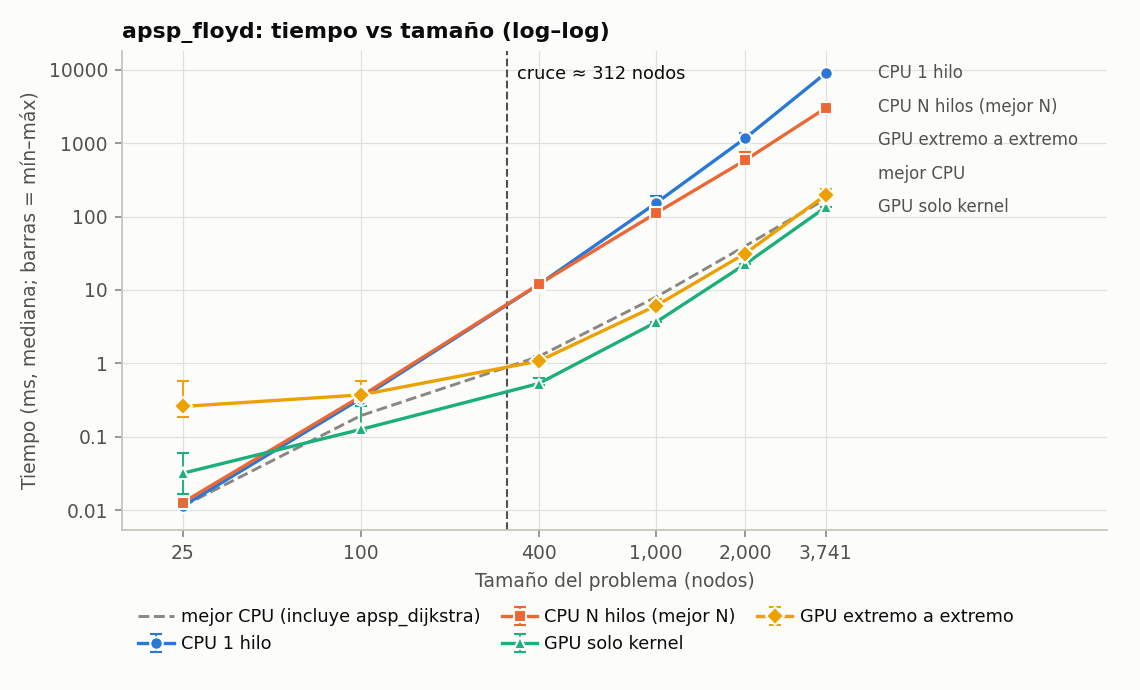

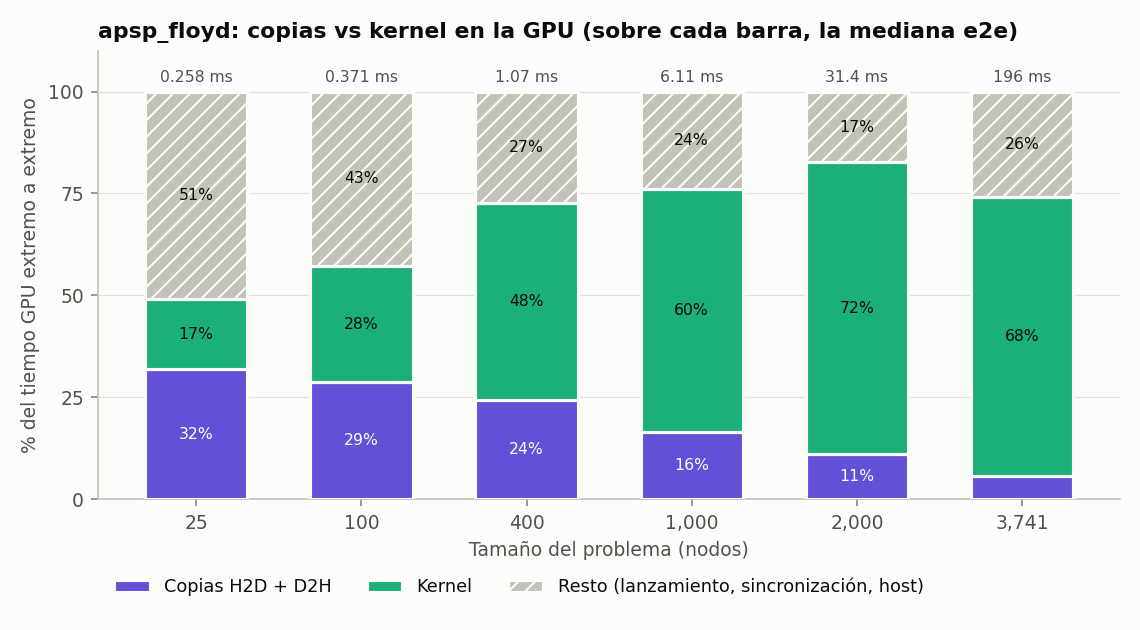

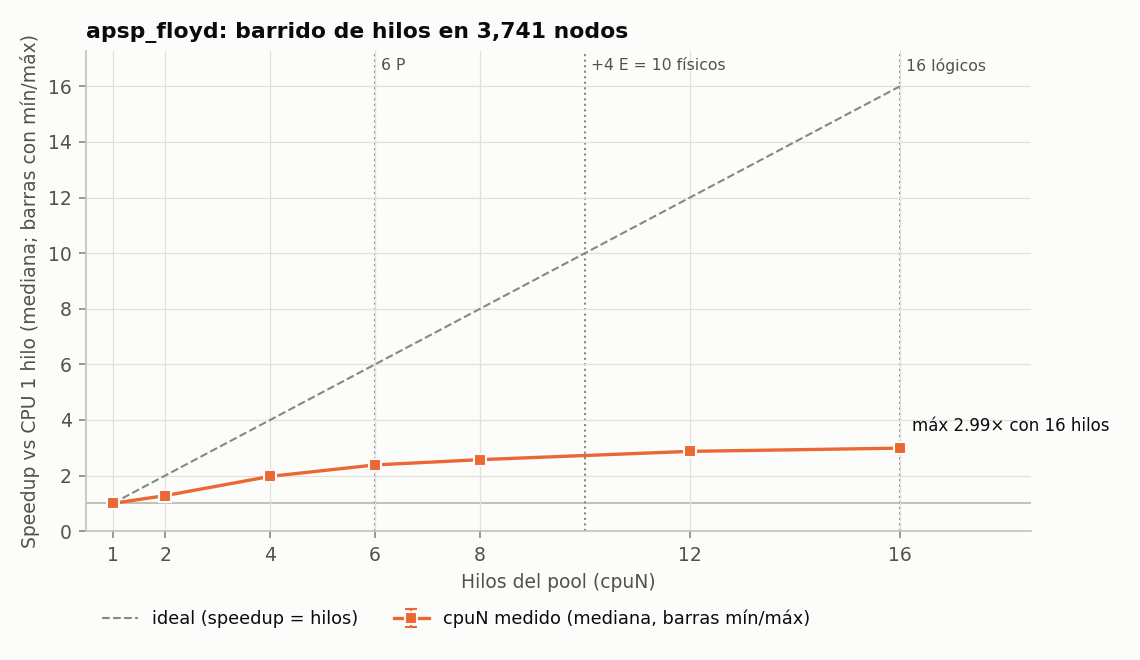

### apsp_dijkstra: Mejor CPU honesta de la aplicación 03: Dijkstra desde cada nodo (solo CPU)

Size = n = nodos del subgrafo.

| Size | CPU 1 thread (ms) | CPU N threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 25 | 0.0164 | 0.0168 (N=1) | n/d | n/d | n/d / n/d | sí (80/80) |
| 100 | 0.346 | 0.193 (N=6) | n/d | n/d | n/d / n/d | sí (80/80) |
| 400 | 8.63 | 1.23 (N=12) | n/d | n/d | n/d / n/d | sí (80/80) |
| 1,000 | 61.0 | 8.02 (N=12) | n/d | n/d | n/d / n/d | sí (80/80) |
| 2,000 | 288 | 39.7 (N=16) | n/d | n/d | n/d / n/d | sí (80/80) |
| 3,741 | 1,061 | 174 (N=12) | n/d | n/d | n/d / n/d | sí (80/80) |

N = el mejor numero de hilos del barrido en cada tamano (entre parentesis). Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: sin datos de GPU → **sin datos de GPU**
- Crossover solo kernel: sin datos de GPU

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 25 | cpu1 | 1 | 10 | 0.0164 | 0.0115 | 0.0307 | 0.00186 | 117% (alta) |
| 25 | cpuN | 1 | 10 | 0.0168 | 0.0121 | 0.0306 | 0.00580 | 110% (alta) |
| 100 | cpu1 | 1 | 10 | 0.346 | 0.331 | 0.385 | 0.0136 | 16% |
| 100 | cpuN | 6 | 10 | 0.193 | 0.154 | 0.275 | 0.0568 | 62% (alta) |
| 400 | cpu1 | 1 | 10 | 8.63 | 8.16 | 11.1 | 0.861 | 34% |
| 400 | cpuN | 12 | 10 | 1.23 | 1.14 | 1.60 | 0.0495 | 37% |
| 1,000 | cpu1 | 1 | 10 | 61.0 | 57.6 | 64.9 | 2.50 | 12% |
| 1,000 | cpuN | 12 | 10 | 8.02 | 7.59 | 8.41 | 0.386 | 10% |
| 2,000 | cpu1 | 1 | 10 | 288 | 257 | 357 | 11.6 | 34% |
| 2,000 | cpuN | 16 | 10 | 39.7 | 35.6 | 44.8 | 3.90 | 23% |
| 3,741 | cpu1 | 1 | 10 | 1,061 | 1,002 | 1,278 | 64.9 | 26% |
| 3,741 | cpuN | 12 | 10 | 174 | 164 | 201 | 9.86 | 21% |

**Barrido de hilos (3,741)**

| Hilos | Mediana (ms) | Speedup vs CPU 1 thread | Rango (con mín/máx) | Eficiencia |
|---|---|---|---|---|
| 1 | 1,006 | 1.06× | 0.948–1.10 | 106% |
| 2 | 542 | 1.96× | 1.74–2.08 | 98% |
| 4 | 329 | 3.23× | 2.94–3.39 | 81% |
| 6 | 263 | 4.04× | 3.90–4.23 | 67% |
| 8 | 226 | 4.70× | 4.25–4.99 | 59% |
| 12 | 174 | 6.10× | 5.28–6.46 | 51% |
| 16 | 180 | 5.89× | 4.47–6.38 | 37% |

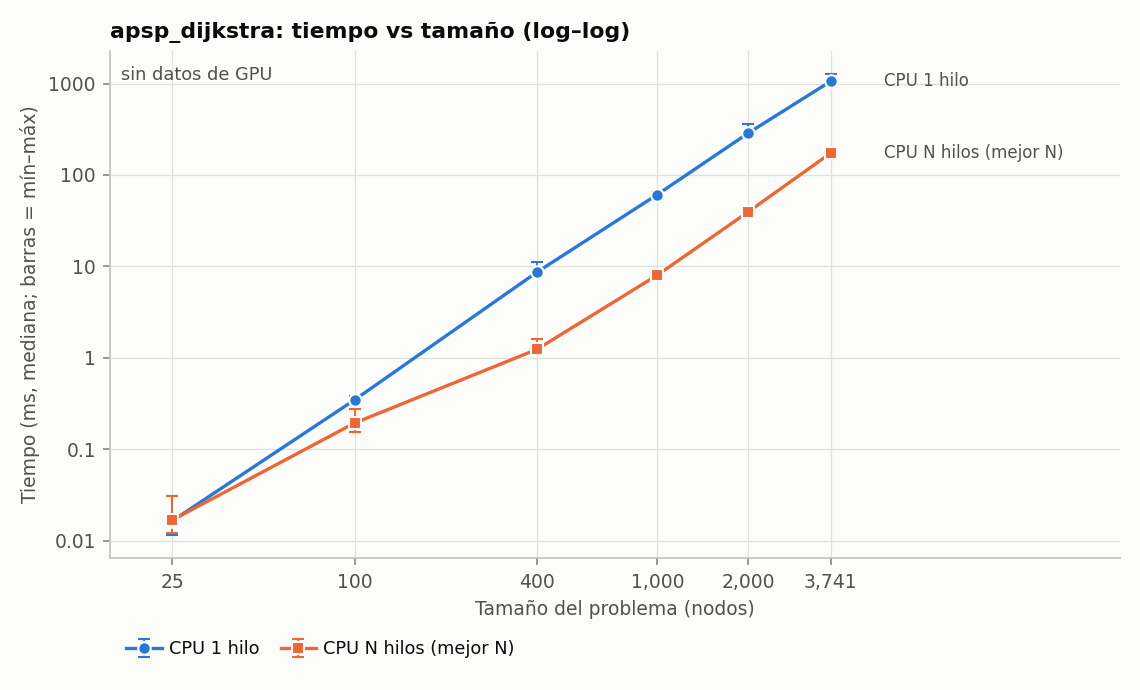

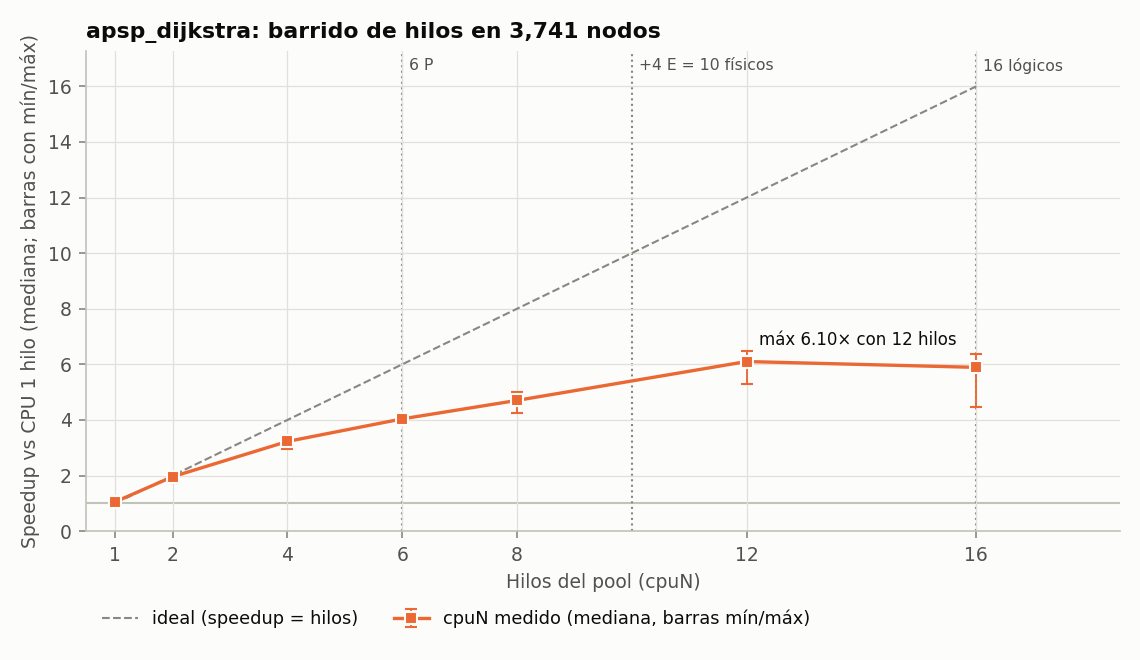

### best_courier: Mejor courier de cada pedido: argmin por fila de la matriz de ETA (árbol de reducción convergente)

Size = n = couriers (columnas); m pedidos como en eta_batch.

| Size | CPU 1 thread (ms) | CPU N threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 50 | 0.000553 | 0.00109 (N=1) | 0.0253 | 0.222 | 0.0219× / 0.00250× | sí (100/100) |
| 150 | 0.00339 | 0.00398 (N=1) | 0.0300 | 0.227 | 0.113× / 0.0149× | sí (100/100) |
| 500 | 0.0338 | 0.0341 (N=1) | 0.0146 | 0.260 | 2.32× / 0.130× | sí (100/100) |
| 777 | 0.0506 | 0.0516 (N=1) | 0.0133 | 0.272 | 3.79× / 0.186× | sí (100/100) |
| 2,000 | 0.430 | 0.204 (N=4) | 0.0194 | 0.481 | 10.5× / 0.425× | sí (100/100) |
| 5,000 | 2.18 | 0.530 (N=16) | 0.0759 | 1.35 | 6.98× / 0.392× | sí (100/100) |

N = el mejor numero de hilos del barrido en cada tamano (entre parentesis). Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: no hay cruce (la GPU no gana en el rango medido) → **mantener CPU**
- Crossover solo kernel: ≈ 358 couriers (entre 150 y 500)

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 50 | cpu1 | 1 | 10 | 0.000553 | 0.000517 | 0.000737 | 0.0000975 | 40% |
| 50 | cpuN | 1 | 10 | 0.00109 | 0.000850 | 0.00143 | 0.000267 | 53% (alta) |
| 50 | gpu_kernel | 1 | 10 | 0.0253 | 0.0111 | 0.0816 | 0.0401 | 279% (alta) |
| 50 | gpu_e2e | 1 | 10 | 0.222 | 0.190 | 0.388 | 0.103 | 89% (alta) |
| 150 | cpu1 | 1 | 10 | 0.00339 | 0.00324 | 0.00393 | 0.000318 | 21% |
| 150 | cpuN | 1 | 10 | 0.00398 | 0.00359 | 0.00492 | 0.000420 | 34% |
| 150 | gpu_kernel | 1 | 10 | 0.0300 | 0.0111 | 0.0855 | 0.0352 | 248% (alta) |
| 150 | gpu_e2e | 1 | 10 | 0.227 | 0.180 | 0.272 | 0.0304 | 40% |
| 500 | cpu1 | 1 | 10 | 0.0338 | 0.0322 | 0.0527 | 0.00189 | 61% (alta) |
| 500 | cpuN | 1 | 10 | 0.0341 | 0.0330 | 0.0423 | 0.00203 | 27% |
| 500 | gpu_kernel | 1 | 10 | 0.0146 | 0.0110 | 0.0855 | 0.0304 | 511% (alta) |
| 500 | gpu_e2e | 1 | 10 | 0.260 | 0.212 | 0.348 | 0.0405 | 53% (alta) |
| 777 | cpu1 | 1 | 10 | 0.0506 | 0.0494 | 0.0642 | 0.00168 | 29% |
| 777 | cpuN | 1 | 10 | 0.0516 | 0.0503 | 0.0583 | 0.00192 | 15% |
| 777 | gpu_kernel | 1 | 10 | 0.0133 | 0.0115 | 0.0820 | 0.0320 | 529% (alta) |
| 777 | gpu_e2e | 1 | 10 | 0.272 | 0.242 | 0.297 | 0.0245 | 20% |
| 2,000 | cpu1 | 1 | 10 | 0.430 | 0.401 | 0.477 | 0.0413 | 18% |
| 2,000 | cpuN | 4 | 10 | 0.204 | 0.172 | 0.352 | 0.0253 | 88% (alta) |
| 2,000 | gpu_kernel | 1 | 10 | 0.0194 | 0.0156 | 0.106 | 0.0389 | 465% (alta) |
| 2,000 | gpu_e2e | 1 | 10 | 0.481 | 0.423 | 0.712 | 0.0648 | 60% (alta) |
| 5,000 | cpu1 | 1 | 10 | 2.18 | 2.13 | 3.00 | 0.0538 | 40% |
| 5,000 | cpuN | 16 | 10 | 0.530 | 0.462 | 0.627 | 0.101 | 31% |
| 5,000 | gpu_kernel | 1 | 10 | 0.0759 | 0.0341 | 0.0853 | 0.0361 | 67% (alta) |
| 5,000 | gpu_e2e | 1 | 10 | 1.35 | 1.28 | 1.84 | 0.113 | 42% |

**Barrido de hilos (5,000)**

| Hilos | Mediana (ms) | Speedup vs CPU 1 thread | Rango (con mín/máx) | Eficiencia |
|---|---|---|---|---|
| 1 | 2.17 | 1.00× | 0.784–1.02 | 100% |
| 2 | 1.18 | 1.84× | 1.48–1.90 | 92% |
| 4 | 0.718 | 3.04× | 1.29–3.57 | 76% |
| 6 | 0.801 | 2.72× | 1.90–3.55 | 45% |
| 8 | 0.660 | 3.30× | 2.14–3.56 | 41% |
| 12 | 0.543 | 4.02× | 2.87–4.73 | 34% |
| 16 | 0.530 | 4.12× | 3.48–4.72 | 26% |

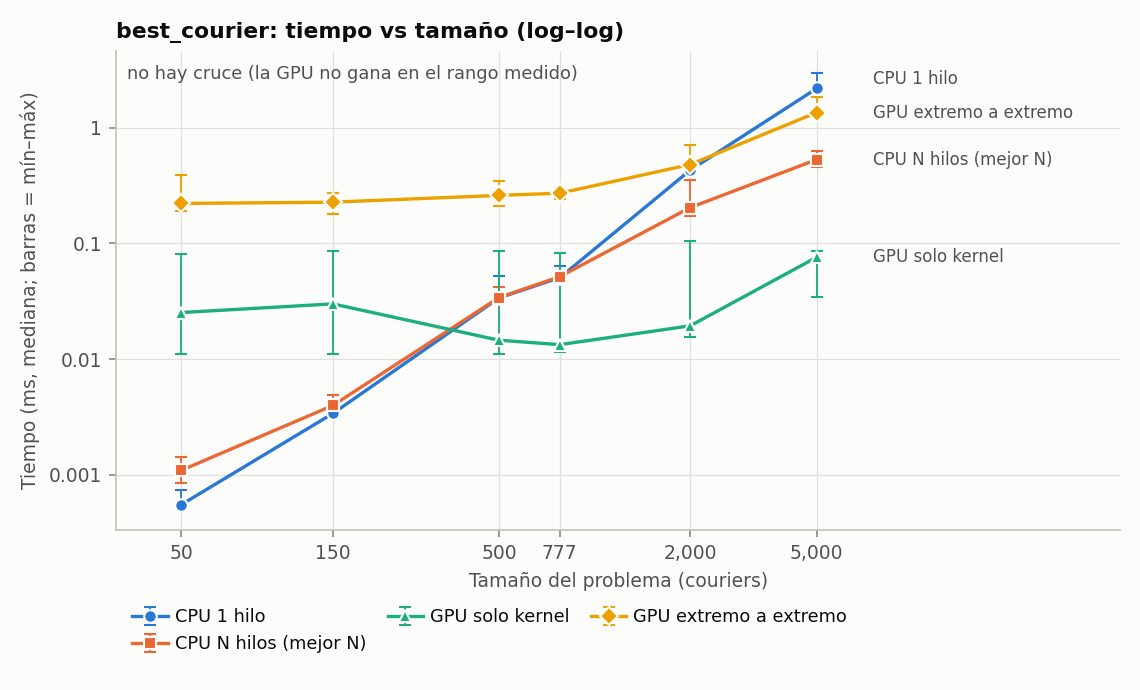

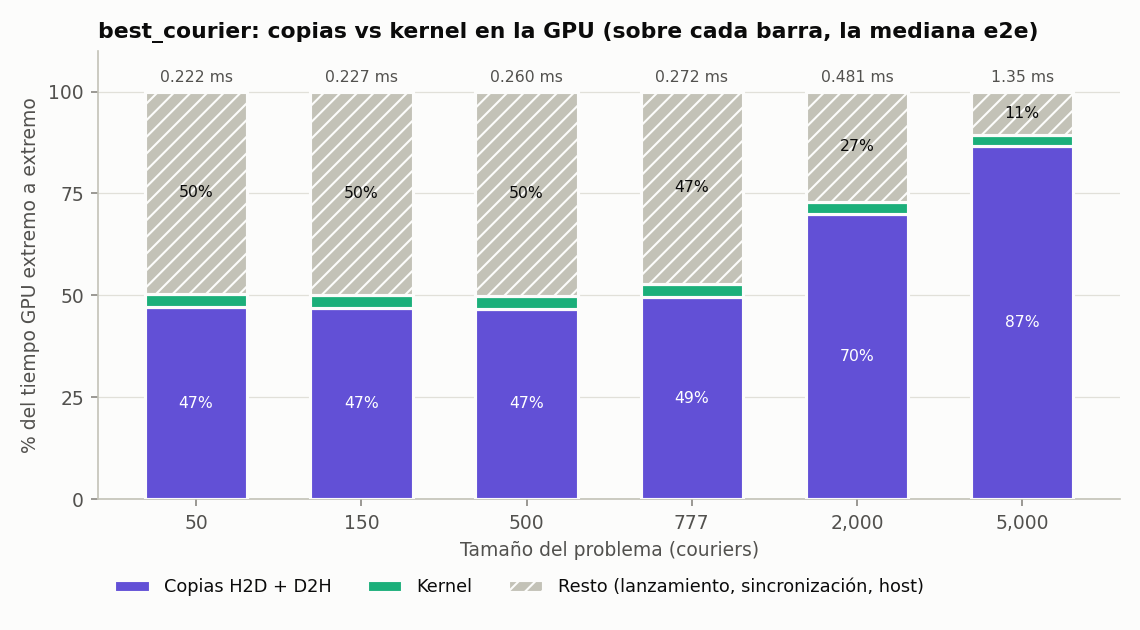

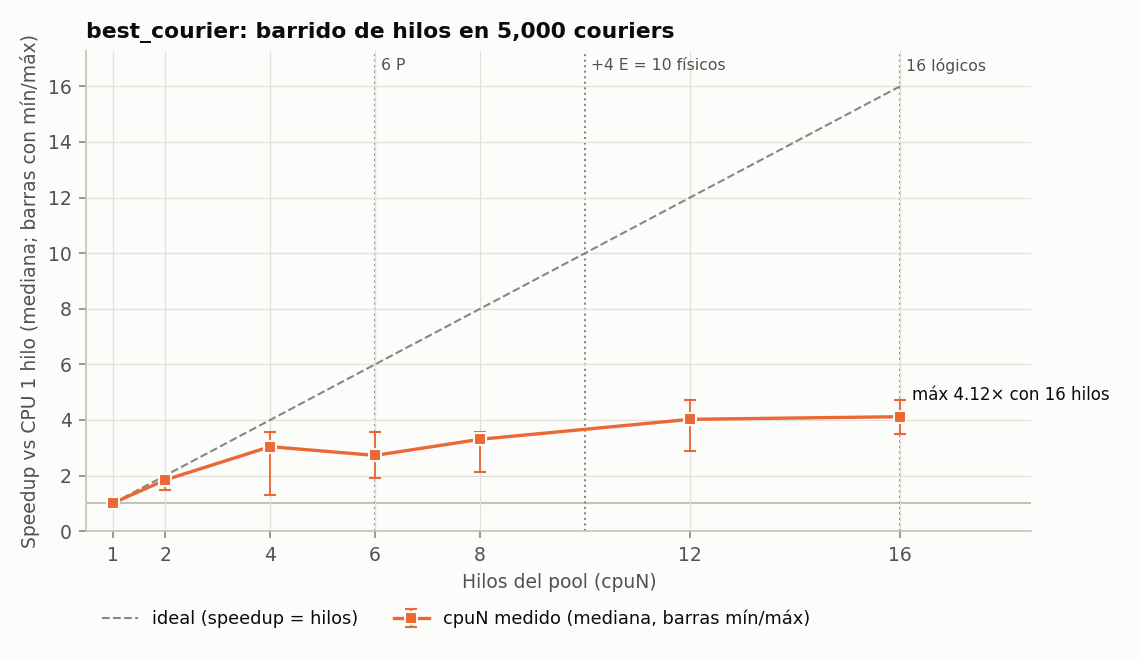

### best_courier_divergent: Variante de comparación: árbol que empareja vecinos (threadIdx % 2·stride: warps divergentes)

Size = igual que best_courier.

| Size | CPU 1 thread (ms) | CPU N threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 50 | 0.000597 | n/d | 0.0590 | 0.346 | 0.00938× / 0.00160× | sí (30/30) |
| 150 | 0.00346 | n/d | 0.0388 | 0.357 | 0.0874× / 0.00952× | sí (30/30) |
| 500 | 0.0359 | n/d | 0.0198 | 0.263 | 1.71× / 0.129× | sí (30/30) |
| 777 | 0.0532 | n/d | 0.0317 | 0.288 | 1.60× / 0.175× | sí (30/30) |
| 2,000 | 0.434 | n/d | 0.0331 | 0.466 | 6.17× / 0.438× | sí (30/30) |
| 5,000 | 2.22 | n/d | 0.0450 | 1.42 | 11.8× / 0.374× | sí (30/30) |

N = el mejor numero de hilos del barrido en cada tamano (entre parentesis). Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: no hay cruce (la GPU no gana en el rango medido) → **mantener CPU**
- Crossover solo kernel: ≈ 402 couriers (entre 150 y 500)

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 50 | cpu1 | 1 | 10 | 0.000597 | 0.000460 | 0.000804 | 0.0000793 | 58% (alta) |
| 50 | gpu_kernel | 1 | 10 | 0.0590 | 0.0113 | 0.109 | 0.0376 | 166% (alta) |
| 50 | gpu_e2e | 1 | 10 | 0.346 | 0.205 | 0.433 | 0.179 | 66% (alta) |
| 150 | cpu1 | 1 | 10 | 0.00346 | 0.00336 | 0.00356 | 0.000119 | 6% |
| 150 | gpu_kernel | 1 | 10 | 0.0388 | 0.0108 | 0.0744 | 0.0383 | 164% (alta) |
| 150 | gpu_e2e | 1 | 10 | 0.357 | 0.177 | 0.429 | 0.109 | 71% (alta) |
| 500 | cpu1 | 1 | 10 | 0.0359 | 0.0345 | 0.0497 | 0.00517 | 43% |
| 500 | gpu_kernel | 1 | 10 | 0.0198 | 0.0116 | 0.0524 | 0.0211 | 207% (alta) |
| 500 | gpu_e2e | 1 | 10 | 0.263 | 0.240 | 0.505 | 0.151 | 101% (alta) |
| 777 | cpu1 | 1 | 10 | 0.0532 | 0.0517 | 0.0615 | 0.00126 | 19% |
| 777 | gpu_kernel | 1 | 10 | 0.0317 | 0.0111 | 0.0790 | 0.0435 | 214% (alta) |
| 777 | gpu_e2e | 1 | 10 | 0.288 | 0.223 | 0.430 | 0.129 | 72% (alta) |
| 2,000 | cpu1 | 1 | 10 | 0.434 | 0.419 | 0.539 | 0.0604 | 28% |
| 2,000 | gpu_kernel | 1 | 10 | 0.0331 | 0.0189 | 0.0688 | 0.0309 | 151% (alta) |
| 2,000 | gpu_e2e | 1 | 10 | 0.466 | 0.441 | 0.647 | 0.0653 | 44% |
| 5,000 | cpu1 | 1 | 10 | 2.22 | 2.17 | 2.27 | 0.0439 | 4% |
| 5,000 | gpu_kernel | 1 | 10 | 0.0450 | 0.0299 | 0.0887 | 0.0259 | 131% (alta) |
| 5,000 | gpu_e2e | 1 | 10 | 1.42 | 1.29 | 2.04 | 0.252 | 52% (alta) |

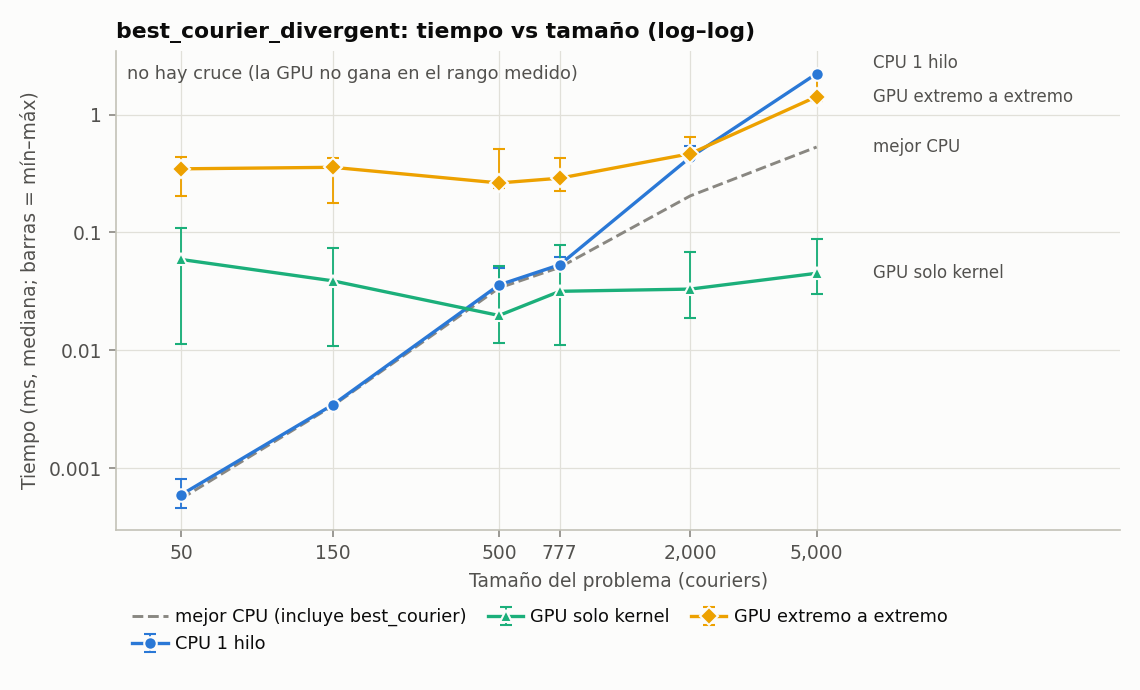

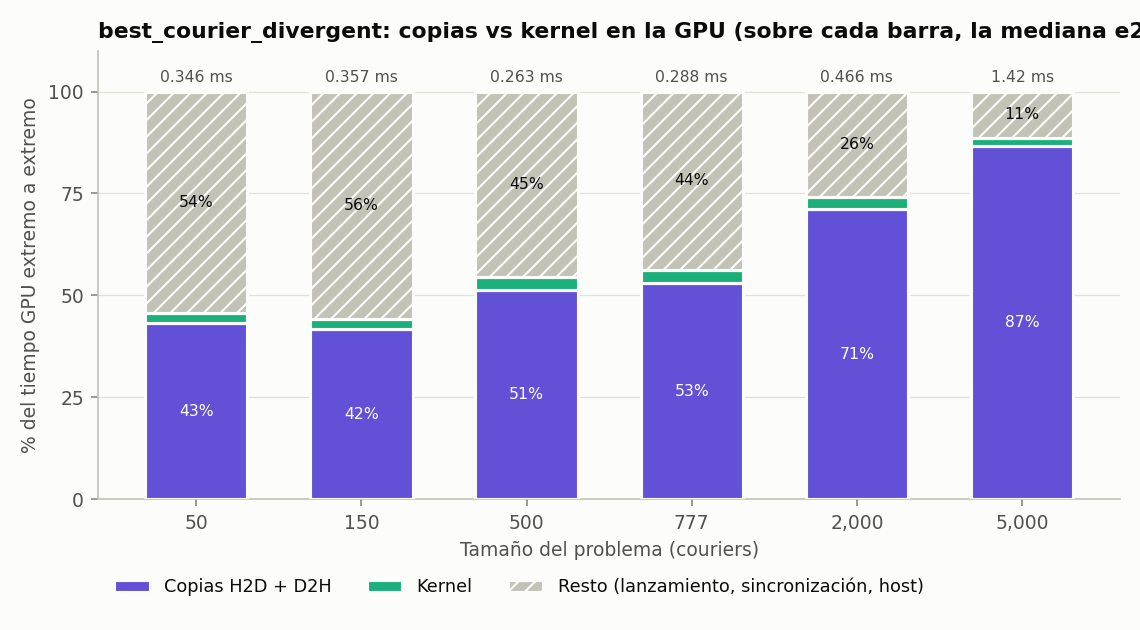

### calib_copy: Calibración: ancho de banda de copia (memcpy, H2D/D2H paginable, VRAM)

Size = bytes copiados por corrida.

| Size | CPU 1 thread (ms) | CPU N threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 4 KiB | 0.000148 | 0.000514 (N=1) | 0.00426 | 0.235 | 0.0347× / 0.000627× | sí (100/100) |
| 64 KiB | 0.00161 | 0.00200 (N=1) | 0.00461 | 0.195 | 0.350× / 0.00828× | sí (100/100) |
| 1 MiB | 0.0422 | 0.0399 (N=1) | 0.00584 | 0.424 | 6.83× / 0.0939× | sí (100/100) |
| 16 MiB | 0.893 | 0.600 (N=4) | 0.196 | 3.44 | 3.07× / 0.175× | sí (100/100) |
| 64 MiB | 3.68 | 2.61 (N=4) | 0.785 | 12.3 | 3.32× / 0.212× | sí (100/100) |
| 256 MiB | 13.1 | 9.74 (N=12) | 3.13 | 51.3 | 3.11× / 0.190× | sí (100/100) |

N = el mejor numero de hilos del barrido en cada tamano (entre parentesis). Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: no hay cruce (la GPU no gana en el rango medido) → **mantener CPU**
- Crossover solo kernel: ≈ 171 KiB (entre 64 KiB y 1 MiB)

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 4 KiB | cpu1 | 1 | 10 | 0.000148 | 0.000104 | 0.00102 | 0.0000300 | 623% (alta) |
| 4 KiB | cpuN | 1 | 10 | 0.000514 | 0.000480 | 0.000735 | 0.0000995 | 50% |
| 4 KiB | gpu_kernel | 1 | 10 | 0.00426 | 0.00307 | 0.0696 | 0.00153 | 1564% (alta) |
| 4 KiB | gpu_e2e | 1 | 10 | 0.235 | 0.200 | 0.287 | 0.0275 | 37% |
| 64 KiB | cpu1 | 1 | 10 | 0.00161 | 0.00140 | 0.00186 | 0.000141 | 28% |
| 64 KiB | cpuN | 1 | 10 | 0.00200 | 0.00175 | 0.00241 | 0.000232 | 33% |
| 64 KiB | gpu_kernel | 1 | 10 | 0.00461 | 0.00323 | 0.0635 | 0.0202 | 1308% (alta) |
| 64 KiB | gpu_e2e | 1 | 10 | 0.195 | 0.109 | 0.275 | 0.101 | 86% (alta) |
| 1 MiB | cpu1 | 1 | 10 | 0.0422 | 0.0355 | 0.0569 | 0.0132 | 51% (alta) |
| 1 MiB | cpuN | 1 | 10 | 0.0399 | 0.0362 | 0.0598 | 0.00588 | 59% (alta) |
| 1 MiB | gpu_kernel | 1 | 10 | 0.00584 | 0.00512 | 0.0686 | 0.000976 | 1087% (alta) |
| 1 MiB | gpu_e2e | 1 | 10 | 0.424 | 0.361 | 0.518 | 0.0324 | 37% |
| 16 MiB | cpu1 | 1 | 10 | 0.893 | 0.819 | 1.08 | 0.125 | 29% |
| 16 MiB | cpuN | 4 | 10 | 0.600 | 0.546 | 1.24 | 0.0582 | 116% (alta) |
| 16 MiB | gpu_kernel | 1 | 10 | 0.196 | 0.193 | 0.199 | 0.00154 | 3% |
| 16 MiB | gpu_e2e | 1 | 10 | 3.44 | 3.28 | 4.59 | 0.248 | 38% |
| 64 MiB | cpu1 | 1 | 10 | 3.68 | 3.54 | 3.87 | 0.144 | 9% |
| 64 MiB | cpuN | 4 | 10 | 2.61 | 2.55 | 2.82 | 0.151 | 10% |
| 64 MiB | gpu_kernel | 1 | 10 | 0.785 | 0.779 | 0.790 | 0.00282 | 1% |
| 64 MiB | gpu_e2e | 1 | 10 | 12.3 | 11.9 | 13.9 | 0.244 | 16% |
| 256 MiB | cpu1 | 1 | 10 | 13.1 | 12.2 | 15.0 | 0.988 | 22% |
| 256 MiB | cpuN | 12 | 10 | 9.74 | 9.53 | 10.2 | 0.134 | 7% |
| 256 MiB | gpu_kernel | 1 | 10 | 3.13 | 3.07 | 3.14 | 0.0317 | 2% |
| 256 MiB | gpu_e2e | 1 | 10 | 51.3 | 48.6 | 56.8 | 4.40 | 16% |

**Barrido de hilos (256 MiB)**

| Hilos | Mediana (ms) | Speedup vs CPU 1 thread | Rango (con mín/máx) | Eficiencia |
|---|---|---|---|---|
| 1 | 12.8 | 1.02× | 0.798–1.08 | 102% |
| 2 | 10.7 | 1.22× | 1.11–1.25 | 61% |
| 4 | 10.3 | 1.26× | 1.17–1.29 | 32% |
| 6 | 9.91 | 1.32× | 1.25–1.33 | 22% |
| 8 | 10.1 | 1.30× | 1.20–1.34 | 16% |
| 12 | 9.74 | 1.34× | 1.27–1.37 | 11% |
| 16 | 9.75 | 1.34× | 1.32–1.39 | 8% |

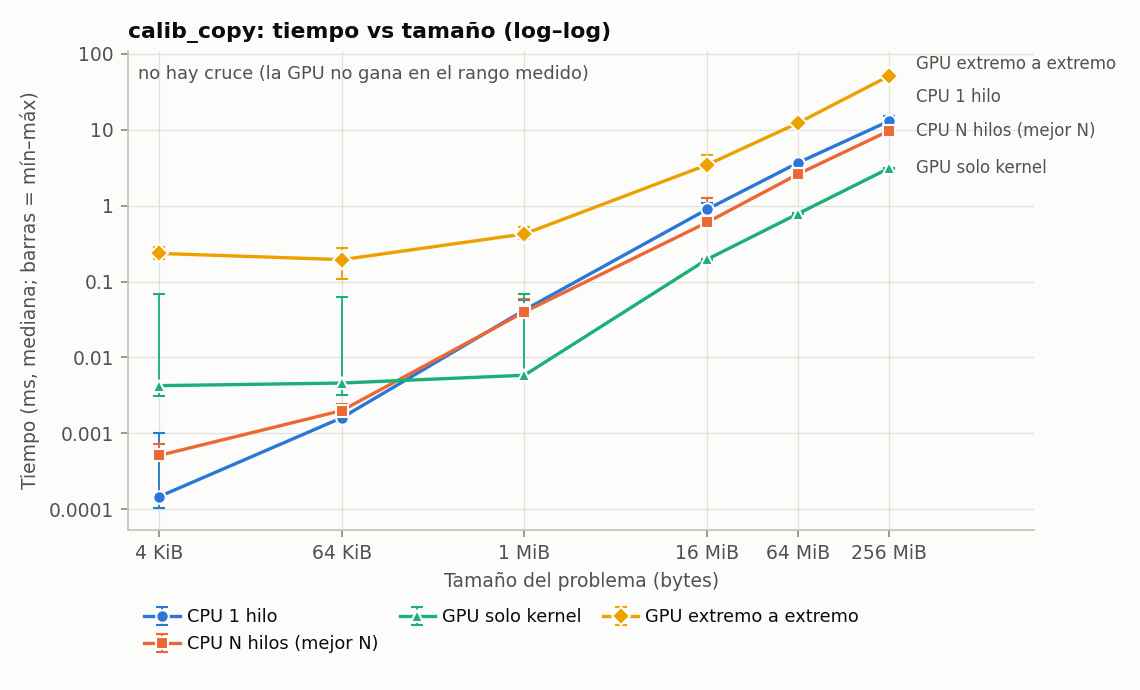

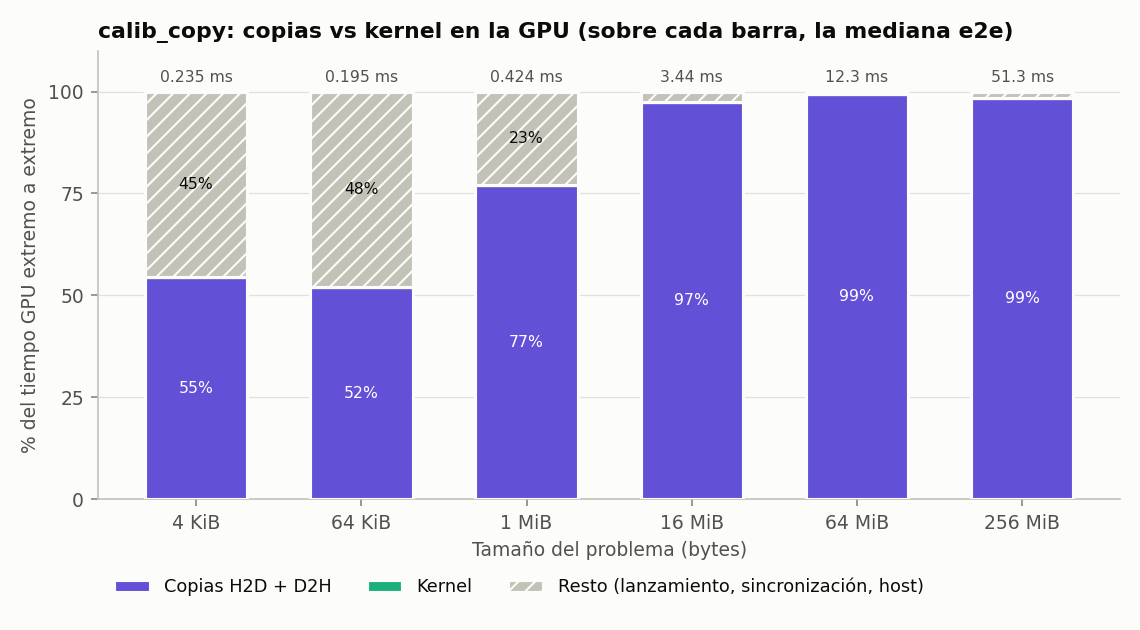

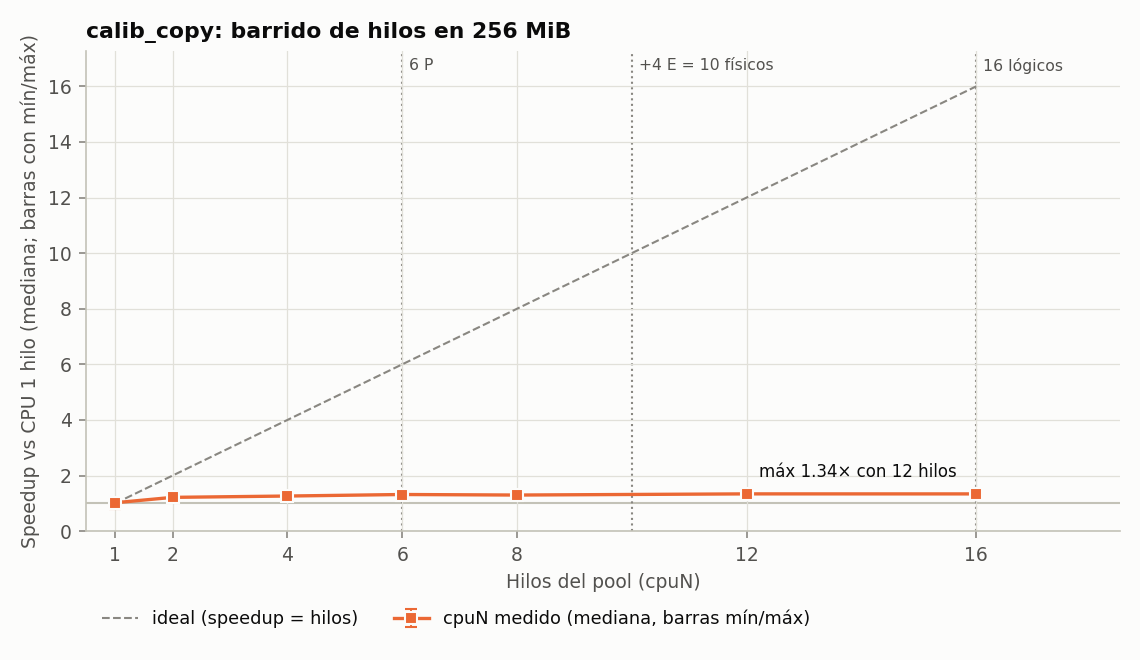

### calib_launch: Calibración: latencia de lanzamiento de kernel vs despacho del pool

Size = N lanzamientos (GPU) o N llamadas/despachos (CPU).

| Size | CPU 1 thread (ms) | CPU 1 threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 1 | 0.0000690 | 0.000659 | 0.00410 | 0.0855 | 0.0168× / 0.000807× | sí (100/100) |
| 10 | 0.000175 | 0.00112 | 0.0769 | 0.325 | 0.00228× / 0.000540× | sí (100/100) |
| 100 | 0.000301 | 0.00536 | 0.686 | 2.67 | 0.000439× / 0.000113× | sí (100/100) |
| 1,000 | 0.00147 | 0.0458 | 7.60 | 20.9 | 0.000194× / 0.0000705× | sí (100/100) |
| 10,000 | 0.0137 | 0.478 | 61.9 | 250 | 0.000221× / 0.0000549× | sí (100/100) |

N = 1: el mejor numero de hilos del barrido en todos los tamanos. Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: no hay cruce (la GPU no gana en el rango medido) → **mantener CPU**
- Crossover solo kernel: no hay cruce (la GPU no gana en el rango medido)

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 1 | cpu1 | 1 | 10 | 0.0000690 | 0.0000540 | 0.000148 | 0.0000170 | 136% (alta) |
| 1 | cpuN | 1 | 10 | 0.000659 | 0.000407 | 0.00146 | 0.000646 | 161% (alta) |
| 1 | gpu_kernel | 1 | 10 | 0.00410 | 0.00371 | 0.0707 | 0.0101 | 1634% (alta) |
| 1 | gpu_e2e | 1 | 10 | 0.0855 | 0.0511 | 0.189 | 0.0410 | 161% (alta) |
| 10 | cpu1 | 1 | 10 | 0.000175 | 0.000102 | 0.000290 | 0.00000975 | 107% (alta) |
| 10 | cpuN | 1 | 10 | 0.00112 | 0.000856 | 0.00327 | 0.000125 | 214% (alta) |
| 10 | gpu_kernel | 1 | 10 | 0.0769 | 0.0663 | 0.182 | 0.0294 | 151% (alta) |
| 10 | gpu_e2e | 1 | 10 | 0.325 | 0.256 | 0.681 | 0.121 | 131% (alta) |
| 100 | cpu1 | 1 | 10 | 0.000301 | 0.000284 | 0.000314 | 0.0000165 | 10% |
| 100 | cpuN | 1 | 10 | 0.00536 | 0.00484 | 0.0101 | 0.000537 | 99% (alta) |
| 100 | gpu_kernel | 1 | 10 | 0.686 | 0.600 | 1.46 | 0.561 | 125% (alta) |
| 100 | gpu_e2e | 1 | 10 | 2.67 | 2.11 | 4.59 | 0.825 | 93% (alta) |
| 1,000 | cpu1 | 1 | 10 | 0.00147 | 0.00134 | 0.00153 | 0.0000602 | 14% |
| 1,000 | cpuN | 1 | 10 | 0.0458 | 0.0438 | 0.0779 | 0.00192 | 74% (alta) |
| 1,000 | gpu_kernel | 1 | 10 | 7.60 | 5.37 | 13.1 | 4.89 | 102% (alta) |
| 1,000 | gpu_e2e | 1 | 10 | 20.9 | 18.9 | 26.4 | 3.20 | 36% |
| 10,000 | cpu1 | 1 | 10 | 0.0137 | 0.0116 | 0.0250 | 0.00267 | 98% (alta) |
| 10,000 | cpuN | 1 | 10 | 0.478 | 0.428 | 0.837 | 0.0910 | 86% (alta) |
| 10,000 | gpu_kernel | 1 | 10 | 61.9 | 55.1 | 105 | 14.2 | 81% (alta) |
| 10,000 | gpu_e2e | 1 | 10 | 250 | 208 | 388 | 85.9 | 72% (alta) |

**Barrido de hilos (10,000)**

| Hilos | Mediana (ms) | Speedup vs CPU 1 thread | Rango (con mín/máx) | Eficiencia |
|---|---|---|---|---|
| 1 | 0.478 | 0.0286× | 0.0164–0.0320 | 3% |
| 2 | 328 | 0.0000417× | 0.0000263–0.0000439 | 0% |
| 4 | 520 | 0.0000263× | 0.0000197–0.0000286 | 0% |
| 6 | 722 | 0.0000190× | 0.0000131–0.0000215 | 0% |
| 8 | 858 | 0.0000160× | 0.0000120–0.0000168 | 0% |
| 12 | 1,178 | 0.0000116× | 0.00000813–0.0000119 | 0% |
| 16 | 1,516 | 0.00000903× | 0.00000440–0.00000917 | 0% |

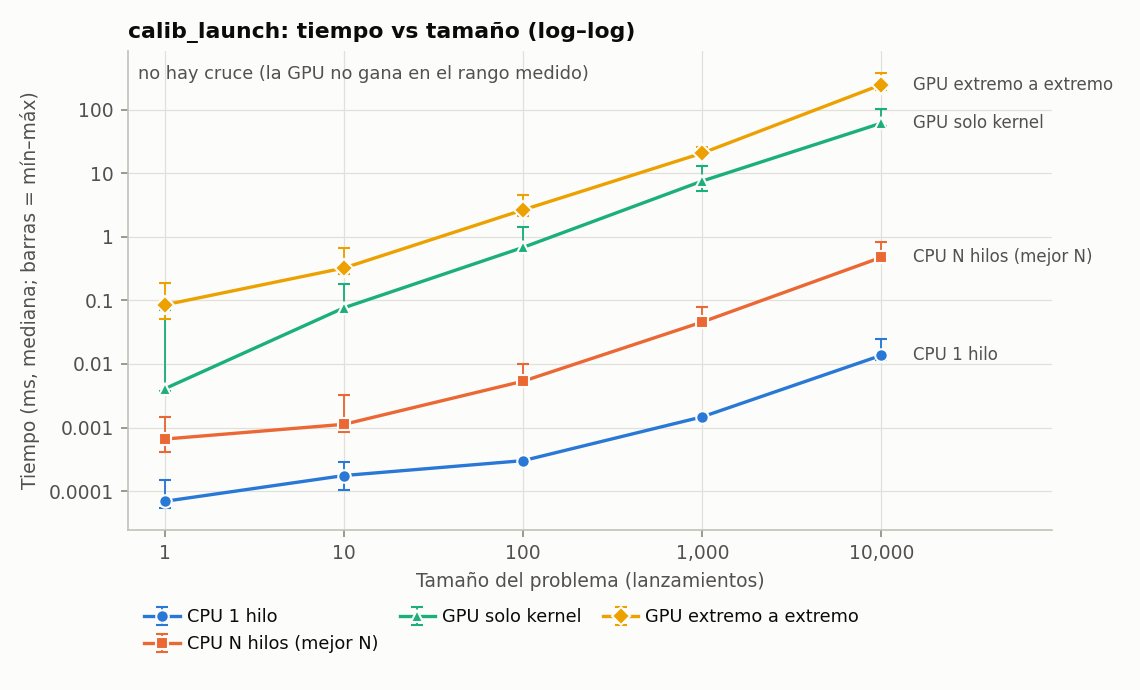

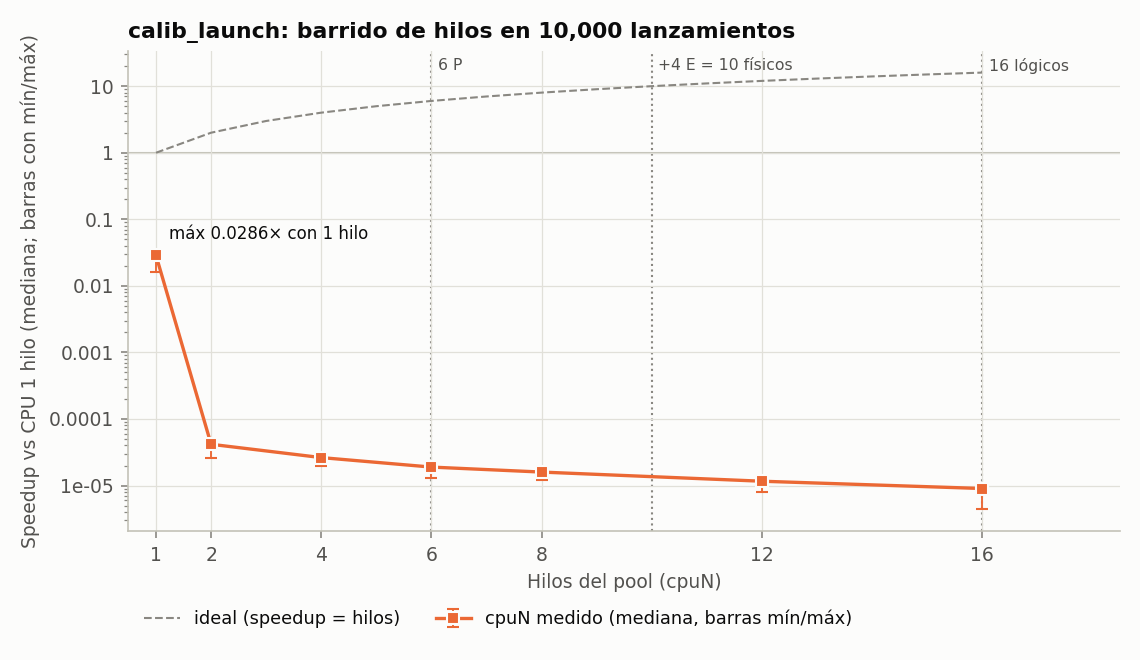

### candidate_filter: Poda de couriers candidatos antes de cotizar: compactación con lista privada por bloque

Size = n = couriers de la flota.

| Size | CPU 1 thread (ms) | CPU N threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 100 | 0.00396 | 0.00505 (N=1) | 0.0261 | 6.15 | 0.152× / 0.000644× | sí (100/100) |
| 500 | 0.0120 | 0.00864 (N=1) | 0.115 | 6.26 | 0.0751× / 0.00138× | sí (100/100) |
| 2,000 | 0.0371 | 0.0354 (N=1) | 0.102 | 6.52 | 0.347× / 0.00543× | sí (100/100) |
| 10,000 | 0.155 | 0.131 (N=1) | 0.0584 | 6.22 | 2.24× / 0.0211× | sí (100/100) |
| 50,000 | 0.537 | 0.360 (N=4) | 0.0531 | 6.37 | 6.78× / 0.0565× | sí (100/100) |
| 200,000 | 2.11 | 0.978 (N=16) | 0.0768 | 6.41 | 12.7× / 0.153× | sí (100/100) |

N = el mejor numero de hilos del barrido en cada tamano (entre parentesis). Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: no hay cruce (la GPU no gana en el rango medido) → **mantener CPU**
- Crossover solo kernel: ≈ 4,980 couriers (entre 2,000 y 10,000)

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 100 | cpu1 | 1 | 10 | 0.00396 | 0.00342 | 0.00808 | 0.00126 | 117% (alta) |
| 100 | cpuN | 1 | 10 | 0.00505 | 0.00391 | 0.00905 | 0.00206 | 102% (alta) |
| 100 | gpu_kernel | 1 | 10 | 0.0261 | 0.0182 | 0.281 | 0.0403 | 1005% (alta) |
| 100 | gpu_e2e | 1 | 10 | 6.15 | 5.63 | 7.50 | 0.787 | 31% |
| 500 | cpu1 | 1 | 10 | 0.0120 | 0.0105 | 0.0412 | 0.00349 | 255% (alta) |
| 500 | cpuN | 1 | 10 | 0.00864 | 0.00636 | 0.0378 | 0.00426 | 364% (alta) |
| 500 | gpu_kernel | 1 | 10 | 0.115 | 0.0180 | 0.146 | 0.0300 | 111% (alta) |
| 500 | gpu_e2e | 1 | 10 | 6.26 | 5.59 | 8.13 | 0.957 | 41% |
| 2,000 | cpu1 | 1 | 10 | 0.0371 | 0.0341 | 0.0548 | 0.00719 | 56% (alta) |
| 2,000 | cpuN | 1 | 10 | 0.0354 | 0.0225 | 0.0436 | 0.0180 | 60% (alta) |
| 2,000 | gpu_kernel | 1 | 10 | 0.102 | 0.0425 | 0.118 | 0.0265 | 74% (alta) |
| 2,000 | gpu_e2e | 1 | 10 | 6.52 | 5.61 | 7.75 | 1.30 | 33% |
| 10,000 | cpu1 | 1 | 10 | 0.155 | 0.119 | 0.173 | 0.0363 | 35% |
| 10,000 | cpuN | 1 | 10 | 0.131 | 0.108 | 0.186 | 0.0401 | 59% (alta) |
| 10,000 | gpu_kernel | 1 | 10 | 0.0584 | 0.0199 | 0.175 | 0.0862 | 265% (alta) |
| 10,000 | gpu_e2e | 1 | 10 | 6.22 | 5.57 | 8.40 | 0.673 | 45% |
| 50,000 | cpu1 | 1 | 10 | 0.537 | 0.509 | 0.595 | 0.0403 | 16% |
| 50,000 | cpuN | 4 | 10 | 0.360 | 0.313 | 0.458 | 0.0195 | 40% |
| 50,000 | gpu_kernel | 1 | 10 | 0.0531 | 0.0203 | 0.129 | 0.0634 | 204% (alta) |
| 50,000 | gpu_e2e | 1 | 10 | 6.37 | 5.46 | 7.24 | 0.998 | 28% |
| 200,000 | cpu1 | 1 | 10 | 2.11 | 1.99 | 2.23 | 0.0907 | 11% |
| 200,000 | cpuN | 16 | 10 | 0.978 | 0.921 | 1.06 | 0.0533 | 14% |
| 200,000 | gpu_kernel | 1 | 10 | 0.0768 | 0.0324 | 0.0884 | 0.0224 | 73% (alta) |
| 200,000 | gpu_e2e | 1 | 10 | 6.41 | 5.86 | 8.31 | 0.721 | 38% |

**Barrido de hilos (200,000)**

| Hilos | Mediana (ms) | Speedup vs CPU 1 thread | Rango (con mín/máx) | Eficiencia |
|---|---|---|---|---|
| 1 | 2.06 | 1.02× | 0.929–1.08 | 102% |
| 2 | 1.45 | 1.46× | 1.000–1.52 | 73% |
| 4 | 1.20 | 1.76× | 1.31–1.94 | 44% |
| 6 | 1.21 | 1.75× | 1.42–1.87 | 29% |
| 8 | 1.04 | 2.02× | 1.92–2.08 | 25% |
| 12 | 1.01 | 2.10× | 2.01–2.26 | 17% |
| 16 | 0.978 | 2.16× | 1.98–2.29 | 13% |

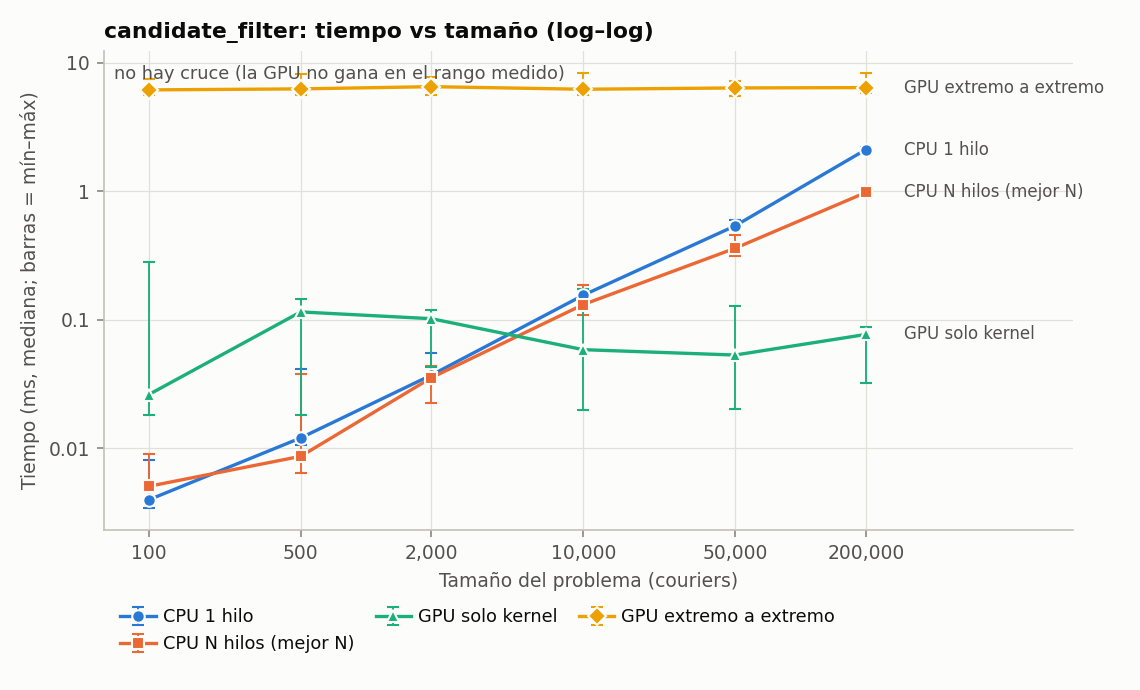

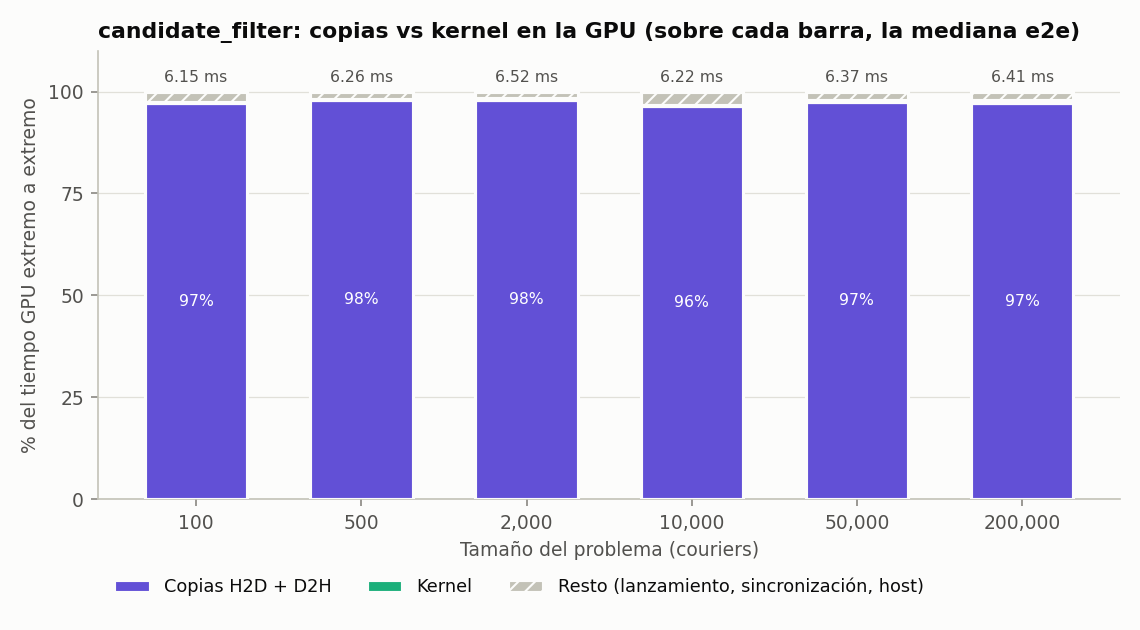

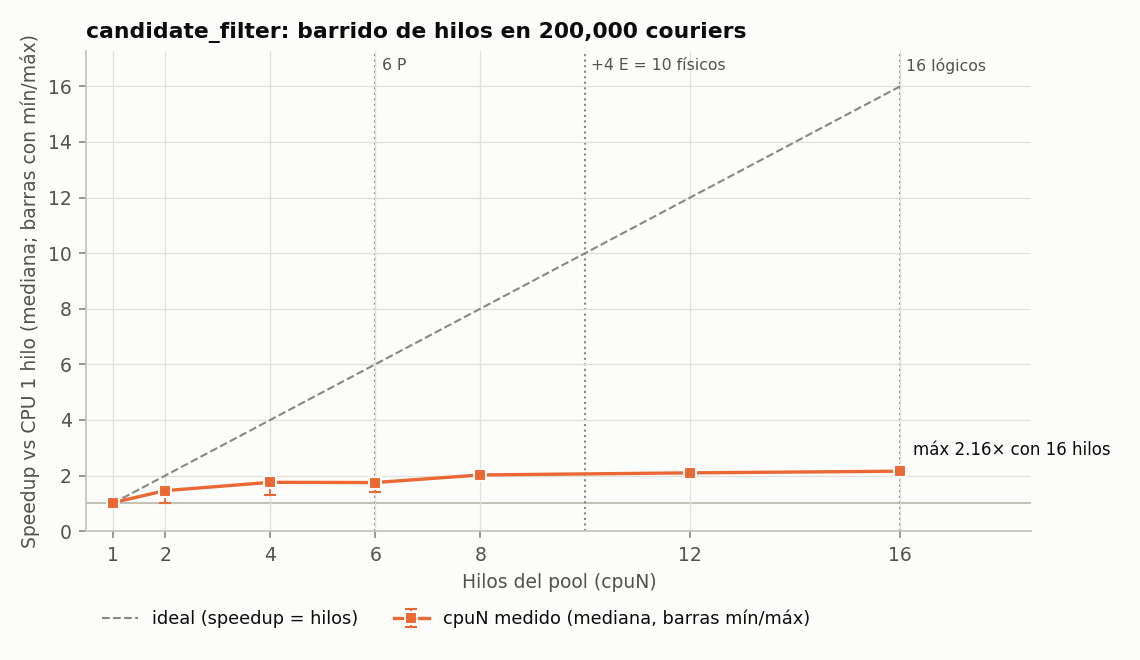

### candidate_filter_naive: Variante de comparación: un atomicAdd GLOBAL por candidato sobre un único contador

Size = n = couriers.

| Size | CPU 1 thread (ms) | CPU N threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 100 | 0.00476 | n/d | 0.0633 | 7.23 | 0.0626× / 0.000548× | sí (30/30) |
| 500 | 0.0175 | n/d | 0.0305 | 6.28 | 0.283× / 0.00138× | sí (30/30) |
| 2,000 | 0.0395 | n/d | 0.0184 | 5.62 | 1.92× / 0.00629× | sí (30/30) |
| 10,000 | 0.162 | n/d | 0.0310 | 5.97 | 4.23× / 0.0220× | sí (30/30) |
| 50,000 | 0.578 | n/d | 0.0439 | 5.85 | 8.20× / 0.0615× | sí (30/30) |
| 200,000 | 2.29 | n/d | 0.0386 | 6.25 | 25.3× / 0.156× | sí (30/30) |

N = el mejor numero de hilos del barrido en cada tamano (entre parentesis). Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: no hay cruce (la GPU no gana en el rango medido) → **mantener CPU**
- Crossover solo kernel: ≈ 1,248 couriers (entre 500 y 2,000)

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 100 | cpu1 | 1 | 10 | 0.00476 | 0.00260 | 0.00592 | 0.00162 | 70% (alta) |
| 100 | gpu_kernel | 1 | 10 | 0.0633 | 0.0143 | 0.0865 | 0.0562 | 114% (alta) |
| 100 | gpu_e2e | 1 | 10 | 7.23 | 6.09 | 8.35 | 1.53 | 31% |
| 500 | cpu1 | 1 | 10 | 0.0175 | 0.0122 | 0.0200 | 0.00275 | 44% |
| 500 | gpu_kernel | 1 | 10 | 0.0305 | 0.0191 | 0.0792 | 0.0218 | 197% (alta) |
| 500 | gpu_e2e | 1 | 10 | 6.28 | 5.77 | 9.48 | 0.693 | 59% (alta) |
| 2,000 | cpu1 | 1 | 10 | 0.0395 | 0.0320 | 0.0484 | 0.00219 | 41% |
| 2,000 | gpu_kernel | 1 | 10 | 0.0184 | 0.0133 | 0.0521 | 0.0202 | 210% (alta) |
| 2,000 | gpu_e2e | 1 | 10 | 5.62 | 5.47 | 5.90 | 0.129 | 8% |
| 10,000 | cpu1 | 1 | 10 | 0.162 | 0.129 | 0.244 | 0.0398 | 71% (alta) |
| 10,000 | gpu_kernel | 1 | 10 | 0.0310 | 0.0177 | 0.0845 | 0.0196 | 215% (alta) |
| 10,000 | gpu_e2e | 1 | 10 | 5.97 | 5.67 | 9.50 | 0.859 | 64% (alta) |
| 50,000 | cpu1 | 1 | 10 | 0.578 | 0.564 | 0.835 | 0.0282 | 47% |
| 50,000 | gpu_kernel | 1 | 10 | 0.0439 | 0.0213 | 0.103 | 0.0432 | 187% (alta) |
| 50,000 | gpu_e2e | 1 | 10 | 5.85 | 5.61 | 6.36 | 0.217 | 13% |
| 200,000 | cpu1 | 1 | 10 | 2.29 | 2.13 | 2.36 | 0.116 | 10% |
| 200,000 | gpu_kernel | 1 | 10 | 0.0386 | 0.0280 | 0.113 | 0.0376 | 220% (alta) |
| 200,000 | gpu_e2e | 1 | 10 | 6.25 | 6.06 | 8.14 | 0.246 | 33% |

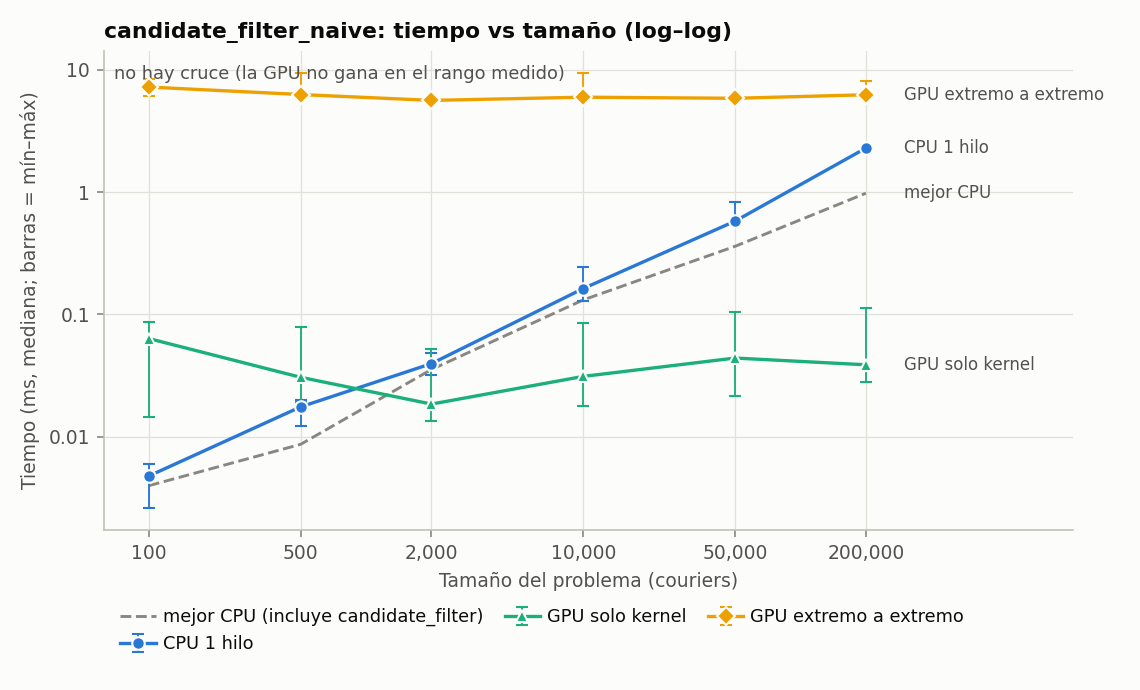

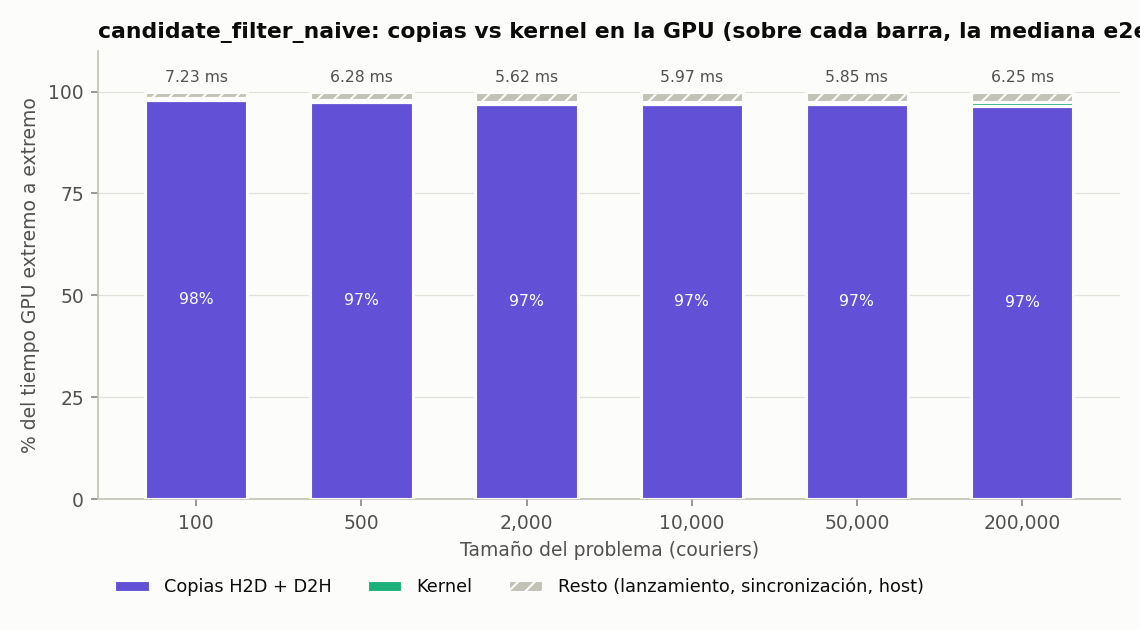

### coverage_field: Campo de cobertura de la flota: stencil de 5 puntos, 200 barridos de Jacobi con doble buffer

Size = n = lado de la grilla (n × n celdas), 200 barridos.

| Size | CPU 1 thread (ms) | CPU N threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 8 | 0.0118 | 0.0183 (N=1) | 2.16 | 3.12 | 0.00546× / 0.00378× | sí (100/100) |
| 16 | 0.0572 | 0.0570 (N=1) | 1.33 | 1.44 | 0.0428× / 0.0397× | sí (100/100) |
| 32 | 0.243 | 0.254 (N=1) | 1.29 | 1.44 | 0.189× / 0.169× | sí (100/100) |
| 64 | 0.973 | 0.987 (N=1) | 1.23 | 1.41 | 0.791× / 0.689× | sí (100/100) |
| 100 | 2.59 | 2.60 (N=1) | 1.32 | 1.53 | 1.96× / 1.69× | sí (100/100) |
| 128 | 4.44 | 4.41 (N=1) | 1.23 | 1.47 | 3.59× / 3.01× | sí (100/100) |
| 256 | 21.7 | 18.5 (N=4) | 1.58 | 1.75 | 11.7× / 10.6× | sí (100/100) |
| 512 | 88.7 | 35.2 (N=4) | 2.09 | 2.87 | 16.8× / 12.3× | sí (100/100) |
| 1,024 | 406 | 95.9 (N=12) | 4.70 | 6.32 | 20.4× / 15.2× | sí (100/100) |

N = el mejor numero de hilos del barrido en cada tamano (entre parentesis). Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: ≈ 77.0 celdas por lado (entre 64 y 100) → **usar GPU sobre el umbral**
- Crossover solo kernel: ≈ 71.8 celdas por lado (entre 64 y 100)

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 8 | cpu1 | 1 | 10 | 0.0118 | 0.0105 | 0.0248 | 0.00130 | 121% (alta) |
| 8 | cpuN | 1 | 10 | 0.0183 | 0.0167 | 0.0283 | 0.00109 | 63% (alta) |
| 8 | gpu_kernel | 1 | 10 | 2.16 | 1.22 | 3.02 | 1.55 | 84% (alta) |
| 8 | gpu_e2e | 1 | 10 | 3.12 | 1.26 | 3.44 | 0.387 | 70% (alta) |
| 16 | cpu1 | 1 | 10 | 0.0572 | 0.0481 | 0.0590 | 0.00389 | 19% |
| 16 | cpuN | 1 | 10 | 0.0570 | 0.0537 | 0.0814 | 0.00823 | 49% |
| 16 | gpu_kernel | 1 | 10 | 1.33 | 1.23 | 2.88 | 0.129 | 124% (alta) |
| 16 | gpu_e2e | 1 | 10 | 1.44 | 1.37 | 3.08 | 0.181 | 119% (alta) |
| 32 | cpu1 | 1 | 10 | 0.243 | 0.197 | 0.408 | 0.0498 | 87% (alta) |
| 32 | cpuN | 1 | 10 | 0.254 | 0.210 | 0.278 | 0.0305 | 27% |
| 32 | gpu_kernel | 1 | 10 | 1.29 | 1.25 | 2.85 | 0.263 | 124% (alta) |
| 32 | gpu_e2e | 1 | 10 | 1.44 | 1.35 | 3.93 | 0.805 | 178% (alta) |
| 64 | cpu1 | 1 | 10 | 0.973 | 0.816 | 1.11 | 0.0929 | 31% |
| 64 | cpuN | 1 | 10 | 0.987 | 0.828 | 1.10 | 0.0444 | 28% |
| 64 | gpu_kernel | 1 | 10 | 1.23 | 1.19 | 2.76 | 0.0636 | 127% (alta) |
| 64 | gpu_e2e | 1 | 10 | 1.41 | 1.30 | 1.74 | 0.102 | 31% |
| 100 | cpu1 | 1 | 10 | 2.59 | 2.30 | 3.09 | 0.403 | 30% |
| 100 | cpuN | 1 | 10 | 2.60 | 2.11 | 2.83 | 0.210 | 28% |
| 100 | gpu_kernel | 1 | 10 | 1.32 | 1.24 | 1.82 | 0.0712 | 44% |
| 100 | gpu_e2e | 1 | 10 | 1.53 | 1.37 | 3.83 | 0.109 | 161% (alta) |
| 128 | cpu1 | 1 | 10 | 4.44 | 4.12 | 4.72 | 0.109 | 14% |
| 128 | cpuN | 1 | 10 | 4.41 | 4.23 | 4.84 | 0.288 | 14% |
| 128 | gpu_kernel | 1 | 10 | 1.23 | 1.15 | 3.04 | 0.0632 | 154% (alta) |
| 128 | gpu_e2e | 1 | 10 | 1.47 | 1.31 | 2.71 | 0.318 | 95% (alta) |
| 256 | cpu1 | 1 | 10 | 21.7 | 19.8 | 35.6 | 4.74 | 73% (alta) |
| 256 | cpuN | 4 | 10 | 18.5 | 15.7 | 43.7 | 6.31 | 152% (alta) |
| 256 | gpu_kernel | 1 | 10 | 1.58 | 1.28 | 3.81 | 1.55 | 160% (alta) |
| 256 | gpu_e2e | 1 | 10 | 1.75 | 1.47 | 3.55 | 0.908 | 119% (alta) |
| 512 | cpu1 | 1 | 10 | 88.7 | 85.2 | 91.3 | 2.88 | 7% |
| 512 | cpuN | 4 | 10 | 35.2 | 33.6 | 54.0 | 1.64 | 58% (alta) |
| 512 | gpu_kernel | 1 | 10 | 2.09 | 1.88 | 3.74 | 1.47 | 89% (alta) |
| 512 | gpu_e2e | 1 | 10 | 2.87 | 2.35 | 4.35 | 1.47 | 70% (alta) |
| 1,024 | cpu1 | 1 | 10 | 406 | 392 | 560 | 17.4 | 41% |
| 1,024 | cpuN | 12 | 10 | 95.9 | 92.3 | 136 | 15.1 | 46% |
| 1,024 | gpu_kernel | 1 | 10 | 4.70 | 4.65 | 6.55 | 0.202 | 40% |
| 1,024 | gpu_e2e | 1 | 10 | 6.32 | 6.09 | 8.33 | 0.923 | 35% |

**Barrido de hilos (1,024)**

| Hilos | Mediana (ms) | Speedup vs CPU 1 thread | Rango (con mín/máx) | Eficiencia |
|---|---|---|---|---|
| 1 | 372 | 1.09× | 0.759–1.12 | 109% |
| 2 | 206 | 1.97× | 1.63–2.14 | 98% |
| 4 | 127 | 3.18× | 2.03–3.51 | 80% |
| 6 | 126 | 3.21× | 1.76–3.51 | 53% |
| 8 | 116 | 3.50× | 1.90–3.60 | 44% |
| 12 | 95.9 | 4.23× | 2.98–4.39 | 35% |
| 16 | 105 | 3.86× | 2.59–4.12 | 24% |

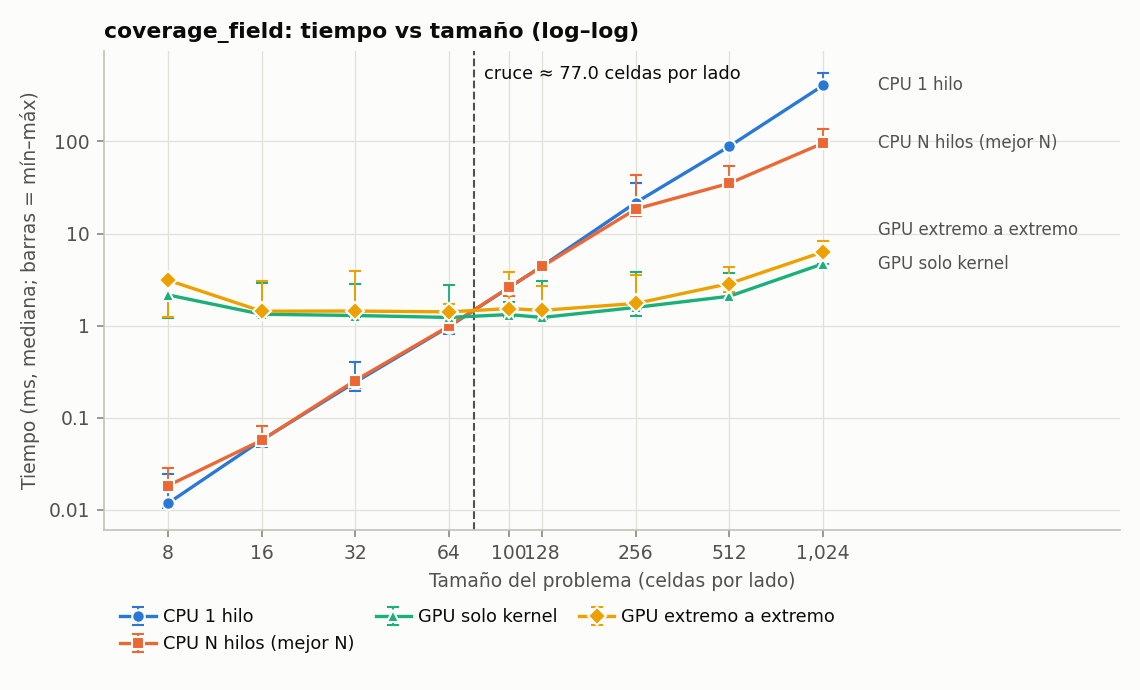

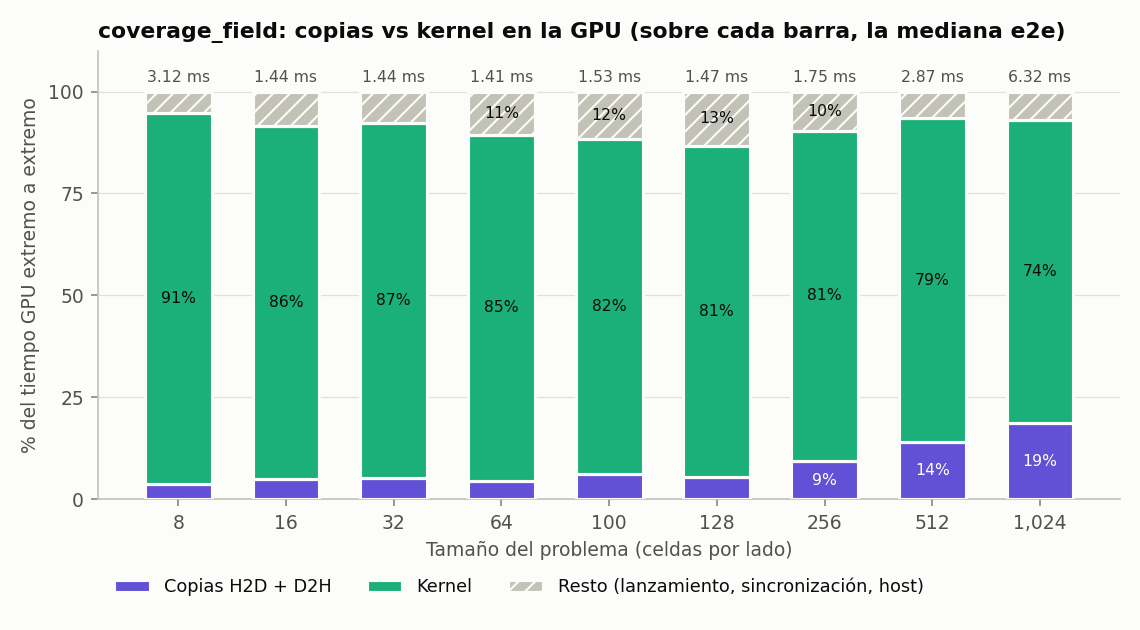

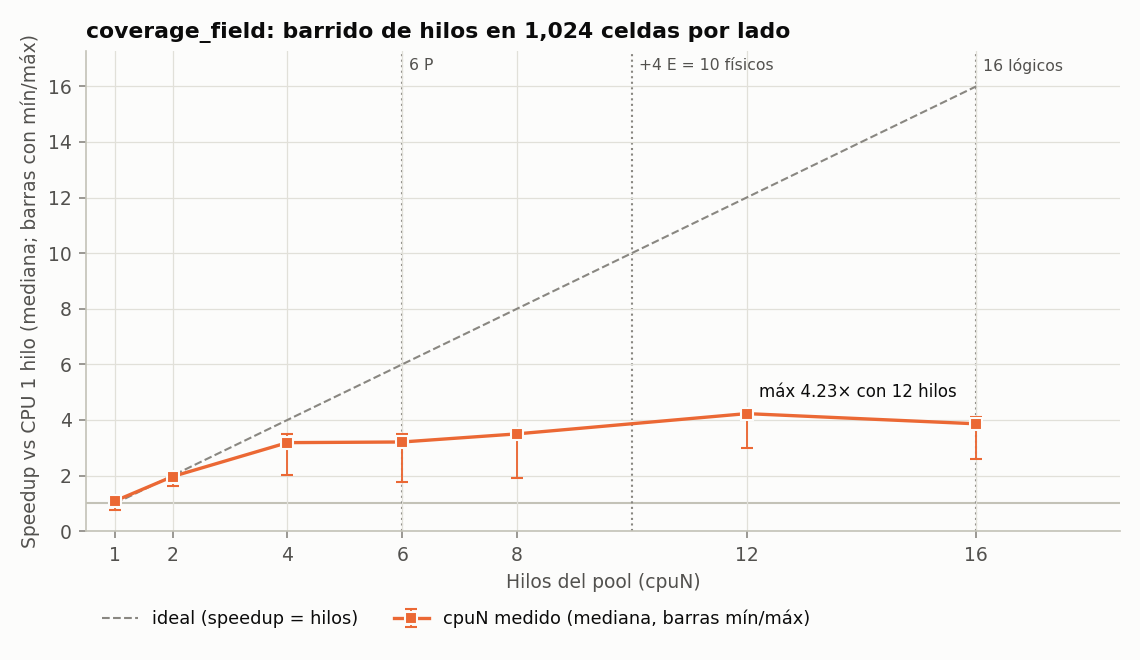

### delivery_histogram: Histograma de tiempos de entrega por minuto (61 barras) con privatización en memoria compartida

Size = n = tiempos de entrega.

| Size | CPU 1 thread (ms) | CPU N threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 1,000 | 0.00155 | 0.00219 (N=1) | 0.00448 | 0.198 | 0.346× / 0.00782× | sí (100/100) |
| 10,000 | 0.0104 | 0.0108 (N=1) | 0.00461 | 0.258 | 2.26× / 0.0404× | sí (100/100) |
| 100,000 | 0.0965 | 0.0949 (N=1) | 0.00498 | 0.208 | 19.1× / 0.457× | sí (100/100) |
| 1,000,000 | 1.59 | 0.578 (N=16) | 0.00968 | 0.923 | 59.7× / 0.626× | sí (100/100) |
| 10,000,000 | 11.1 | 1.82 (N=12) | 0.221 | 4.35 | 8.25× / 0.419× | sí (100/100) |

N = el mejor numero de hilos del barrido en cada tamano (entre parentesis). Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: no hay cruce (la GPU no gana en el rango medido) → **mantener CPU**
- Crossover solo kernel: ≈ 3,671 entregas (entre 1,000 y 10,000)

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 1,000 | cpu1 | 1 | 10 | 0.00155 | 0.00126 | 0.00200 | 0.000131 | 48% |
| 1,000 | cpuN | 1 | 10 | 0.00219 | 0.00172 | 0.00251 | 0.000272 | 36% |
| 1,000 | gpu_kernel | 1 | 10 | 0.00448 | 0.00307 | 0.100 | 0.00486 | 2168% (alta) |
| 1,000 | gpu_e2e | 1 | 10 | 0.198 | 0.142 | 0.336 | 0.108 | 98% (alta) |
| 10,000 | cpu1 | 1 | 10 | 0.0104 | 0.00972 | 0.0110 | 0.000840 | 12% |
| 10,000 | cpuN | 1 | 10 | 0.0108 | 0.00889 | 0.0118 | 0.000216 | 27% |
| 10,000 | gpu_kernel | 1 | 10 | 0.00461 | 0.00307 | 0.00819 | 0.00282 | 111% (alta) |
| 10,000 | gpu_e2e | 1 | 10 | 0.258 | 0.161 | 0.329 | 0.0918 | 65% (alta) |
| 100,000 | cpu1 | 1 | 10 | 0.0965 | 0.0913 | 0.152 | 0.0209 | 62% (alta) |
| 100,000 | cpuN | 1 | 10 | 0.0949 | 0.0917 | 0.179 | 0.0134 | 92% (alta) |
| 100,000 | gpu_kernel | 1 | 10 | 0.00498 | 0.00410 | 0.0526 | 0.000864 | 974% (alta) |
| 100,000 | gpu_e2e | 1 | 10 | 0.208 | 0.198 | 0.480 | 0.0670 | 136% (alta) |
| 1,000,000 | cpu1 | 1 | 10 | 1.59 | 1.48 | 2.14 | 0.0746 | 42% |
| 1,000,000 | cpuN | 16 | 10 | 0.578 | 0.404 | 0.872 | 0.135 | 81% (alta) |
| 1,000,000 | gpu_kernel | 1 | 10 | 0.00968 | 0.00906 | 0.100 | 0.0120 | 943% (alta) |
| 1,000,000 | gpu_e2e | 1 | 10 | 0.923 | 0.775 | 1.34 | 0.292 | 61% (alta) |
| 10,000,000 | cpu1 | 1 | 10 | 11.1 | 10.5 | 12.2 | 0.423 | 16% |
| 10,000,000 | cpuN | 12 | 10 | 1.82 | 1.76 | 1.93 | 0.0509 | 9% |
| 10,000,000 | gpu_kernel | 1 | 10 | 0.221 | 0.220 | 0.356 | 0.000832 | 61% (alta) |
| 10,000,000 | gpu_e2e | 1 | 10 | 4.35 | 4.27 | 5.45 | 0.249 | 27% |

**Barrido de hilos (10,000,000)**

| Hilos | Mediana (ms) | Speedup vs CPU 1 thread | Rango (con mín/máx) | Eficiencia |
|---|---|---|---|---|
| 1 | 11.2 | 0.986× | 0.915–1.04 | 99% |
| 2 | 5.72 | 1.94× | 1.56–2.01 | 97% |
| 4 | 2.97 | 3.73× | 2.36–4.01 | 93% |
| 6 | 2.83 | 3.92× | 3.19–4.09 | 65% |
| 8 | 2.43 | 4.57× | 3.70–5.06 | 57% |
| 12 | 1.82 | 6.08× | 5.73–6.29 | 51% |
| 16 | 2.14 | 5.18× | 3.94–7.72 | 32% |

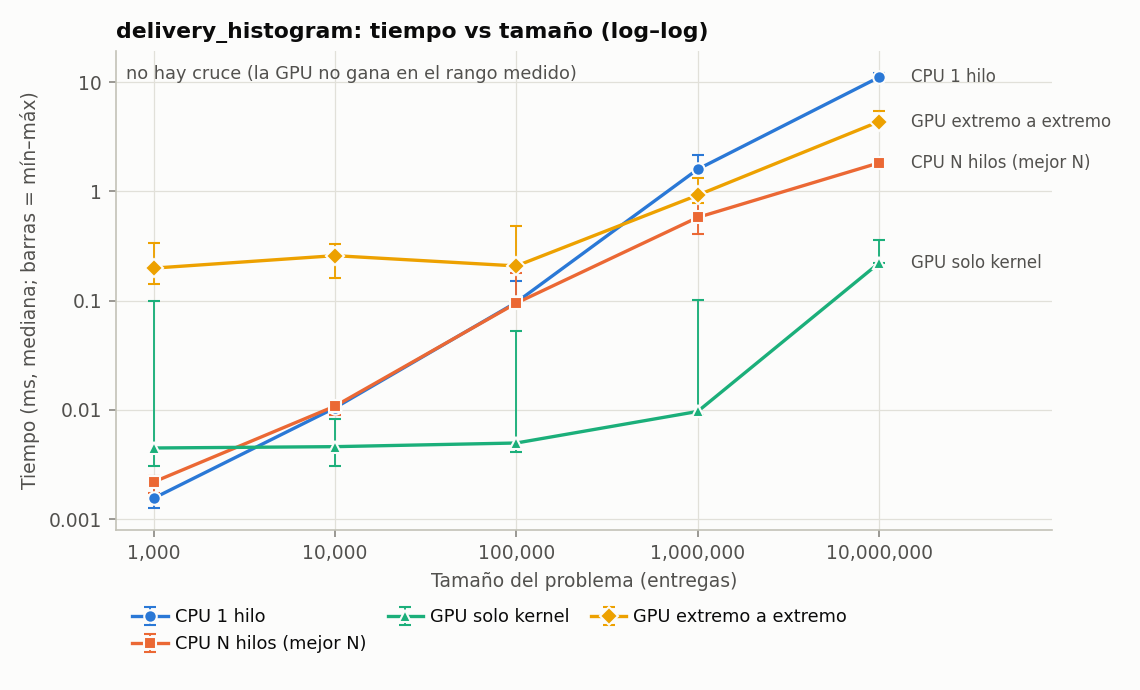

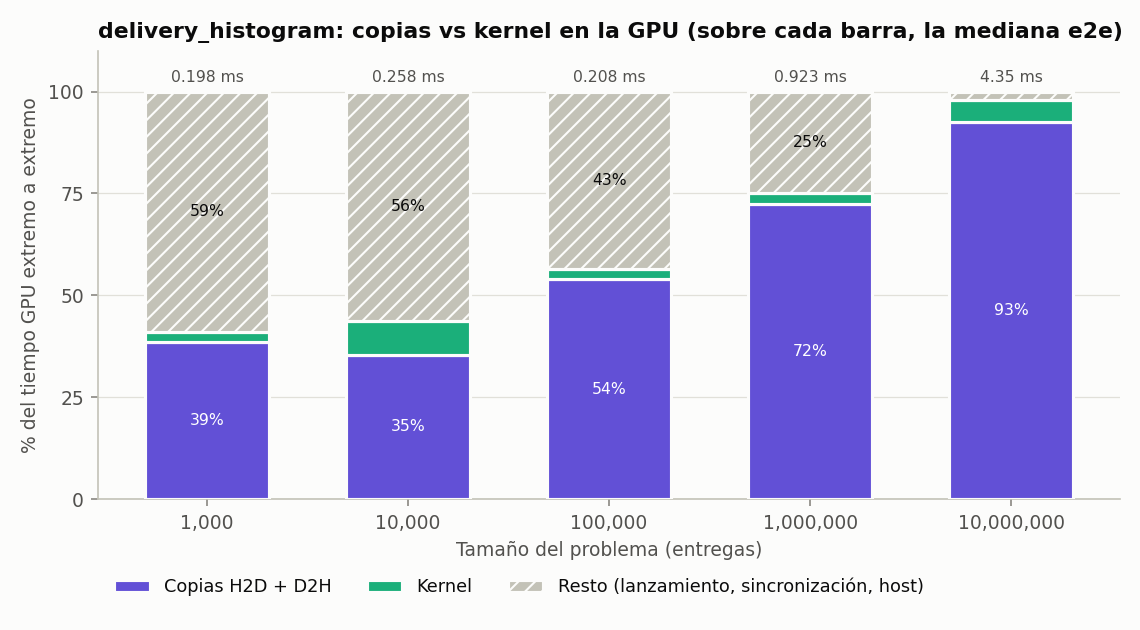

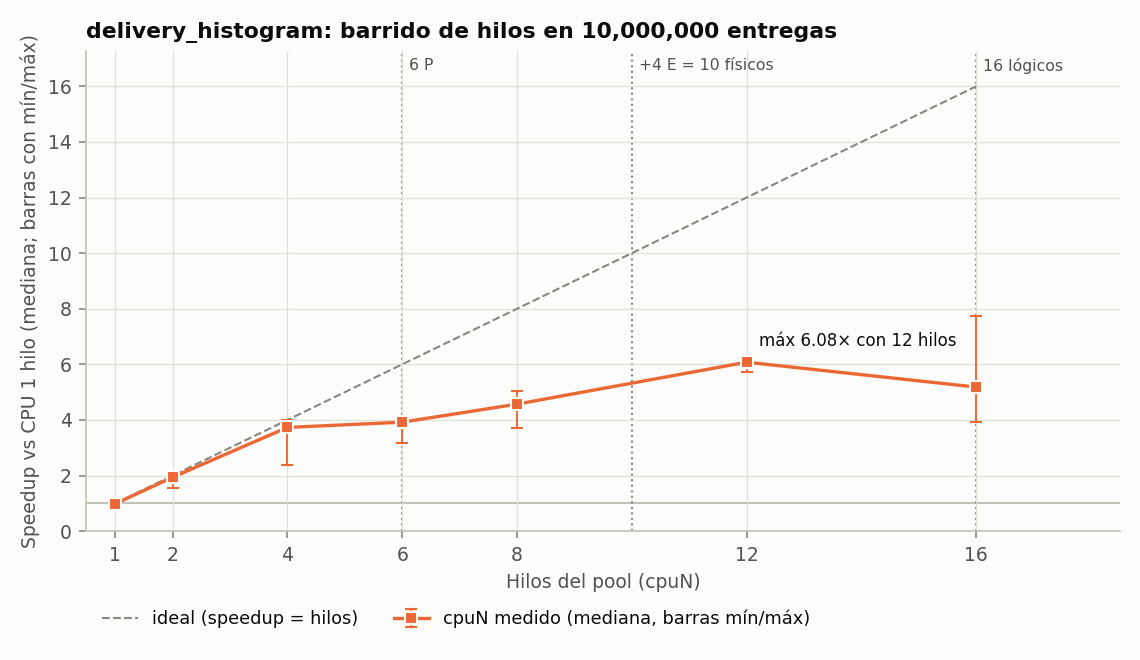

### histogram_naive: Variante de comparación: un atomicAdd GLOBAL por entrega sobre las mismas 61 barras

Size = n = tiempos de entrega.

| Size | CPU 1 thread (ms) | CPU N threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 1,000 | n/d | n/d | 0.00501 | 0.178 | 0.310× / 0.00871× | sí (20/20) |
| 10,000 | n/d | n/d | 0.00717 | 0.184 | 1.46× / 0.0566× | sí (20/20) |
| 100,000 | n/d | n/d | 0.0304 | 0.247 | 3.12× / 0.385× | sí (20/20) |
| 1,000,000 | n/d | n/d | 0.268 | 0.846 | 2.16× / 0.683× | sí (20/20) |
| 10,000,000 | n/d | n/d | 2.63 | 6.98 | 0.693× / 0.261× | sí (20/20) |

N = el mejor numero de hilos del barrido en cada tamano (entre parentesis). Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: no hay cruce (la GPU no gana en el rango medido) → **mantener CPU**
- Crossover solo kernel: ≈ 5,722 entregas (entre 1,000 y 10,000); vuelve a perder desde ≈ 4,751,923 entregas

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 1,000 | gpu_kernel | 1 | 10 | 0.00501 | 0.00410 | 0.0551 | 0.000856 | 1019% (alta) |
| 1,000 | gpu_e2e | 1 | 10 | 0.178 | 0.136 | 0.311 | 0.0518 | 98% (alta) |
| 10,000 | gpu_kernel | 1 | 10 | 0.00717 | 0.00614 | 0.0583 | 0.000824 | 728% (alta) |
| 10,000 | gpu_e2e | 1 | 10 | 0.184 | 0.147 | 0.325 | 0.0458 | 97% (alta) |
| 100,000 | gpu_kernel | 1 | 10 | 0.0304 | 0.0297 | 0.0655 | 0.000976 | 118% (alta) |
| 100,000 | gpu_e2e | 1 | 10 | 0.247 | 0.203 | 0.402 | 0.0816 | 81% (alta) |
| 1,000,000 | gpu_kernel | 1 | 10 | 0.268 | 0.266 | 0.313 | 0.00179 | 18% |
| 1,000,000 | gpu_e2e | 1 | 10 | 0.846 | 0.778 | 0.914 | 0.0787 | 16% |
| 10,000,000 | gpu_kernel | 1 | 10 | 2.63 | 2.63 | 2.66 | 0.000936 | 1% |
| 10,000,000 | gpu_e2e | 1 | 10 | 6.98 | 6.62 | 7.24 | 0.425 | 9% |

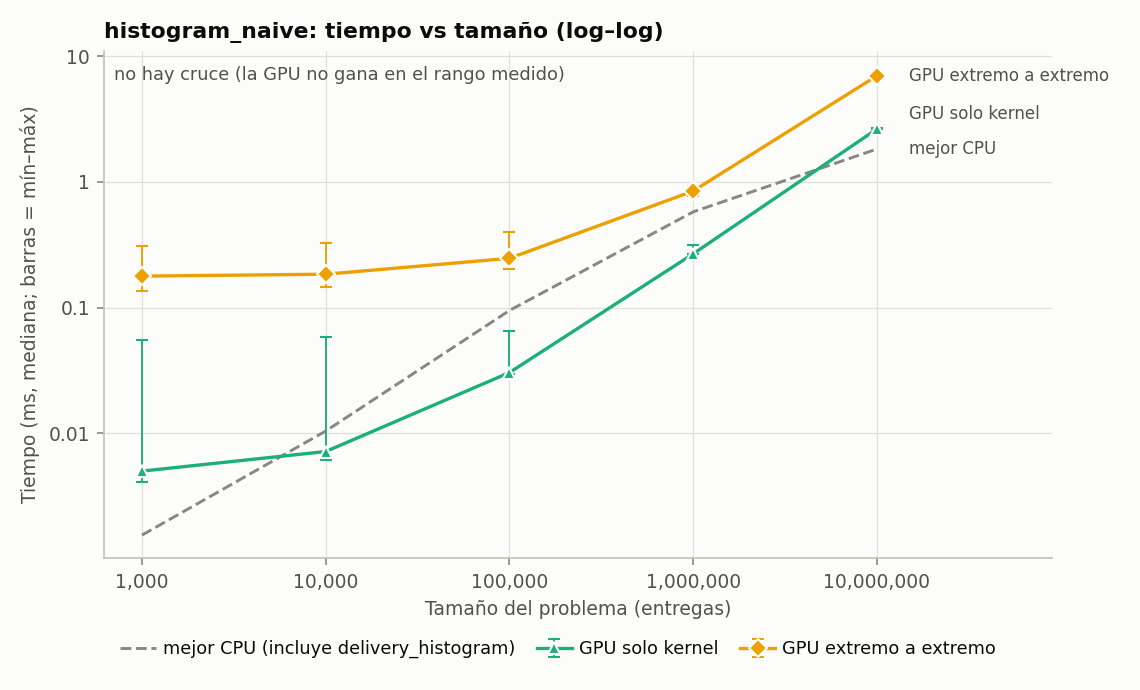

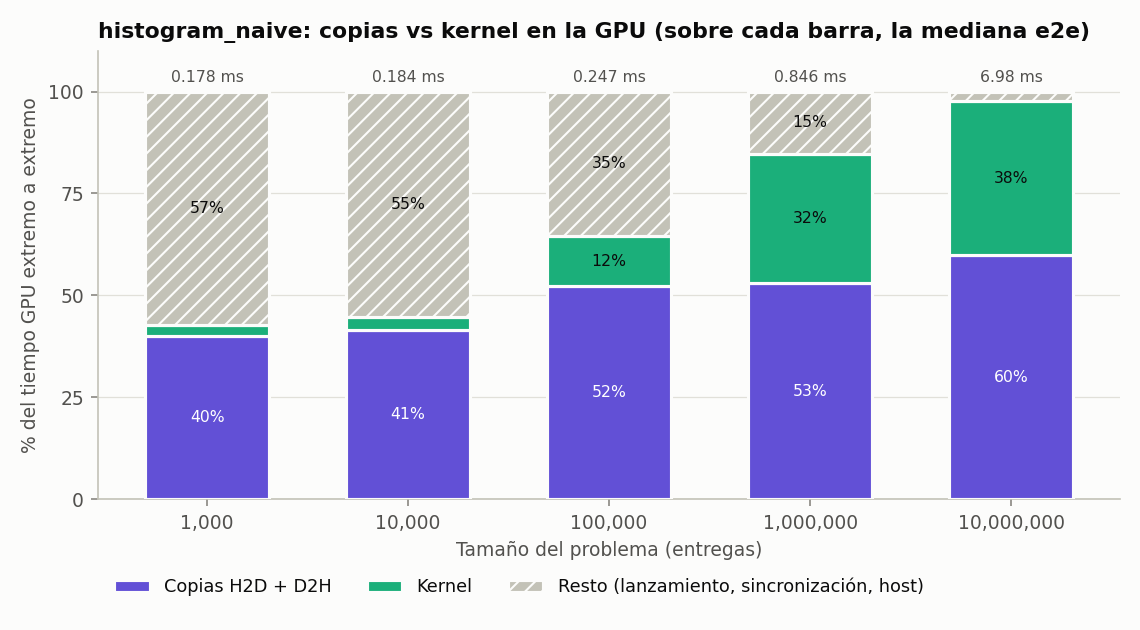

### delivery_percentiles: Percentiles p50, p90 y p99 del tiempo de entrega: radix sort de 1 bit por pasada

Size = n = tiempos de entrega (ms, claves de 32 bits).

| Size | CPU 1 thread (ms) | CPU N threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 1,000 | 0.0897 | 0.0937 (N=1) | 0.845 | 1.80 | 0.106× / 0.0500× | sí (100/100) |
| 10,000 | 0.954 | 0.956 (N=1) | 0.894 | 1.06 | 1.07× / 0.896× | sí (100/100) |
| 100,000 | 8.34 | 5.03 (N=4) | 1.11 | 1.85 | 4.54× / 2.71× | sí (100/100) |
| 1,000,000 | 90.1 | 19.4 (N=16) | 2.83 | 4.34 | 6.84× / 4.47× | sí (100/100) |
| 10,000,000 | 1,309 | 167 (N=12) | 57.9 | 70.6 | 2.89× / 2.37× | sí (100/100) |

N = el mejor numero de hilos del barrido en cada tamano (entre parentesis). Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: ≈ 12,568 entregas (entre 10,000 y 100,000) → **usar GPU sobre el umbral**
- Crossover solo kernel: ≈ 9,376 entregas (entre 1,000 y 10,000)

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 1,000 | cpu1 | 1 | 10 | 0.0897 | 0.0831 | 0.161 | 0.00613 | 87% (alta) |
| 1,000 | cpuN | 1 | 10 | 0.0937 | 0.0876 | 0.114 | 0.0127 | 28% |
| 1,000 | gpu_kernel | 1 | 10 | 0.845 | 0.771 | 1.83 | 0.579 | 125% (alta) |
| 1,000 | gpu_e2e | 1 | 10 | 1.80 | 0.911 | 2.06 | 0.837 | 64% (alta) |
| 10,000 | cpu1 | 1 | 10 | 0.954 | 0.874 | 1.10 | 0.0712 | 23% |
| 10,000 | cpuN | 1 | 10 | 0.956 | 0.880 | 1.05 | 0.0356 | 18% |
| 10,000 | gpu_kernel | 1 | 10 | 0.894 | 0.747 | 1.85 | 0.695 | 123% (alta) |
| 10,000 | gpu_e2e | 1 | 10 | 1.06 | 0.883 | 2.23 | 0.512 | 126% (alta) |
| 100,000 | cpu1 | 1 | 10 | 8.34 | 7.89 | 11.0 | 0.555 | 38% |
| 100,000 | cpuN | 4 | 10 | 5.03 | 4.56 | 5.47 | 0.216 | 18% |
| 100,000 | gpu_kernel | 1 | 10 | 1.11 | 0.818 | 1.76 | 0.556 | 85% (alta) |
| 100,000 | gpu_e2e | 1 | 10 | 1.85 | 1.15 | 2.37 | 0.545 | 66% (alta) |
| 1,000,000 | cpu1 | 1 | 10 | 90.1 | 83.4 | 131 | 5.84 | 53% (alta) |
| 1,000,000 | cpuN | 16 | 10 | 19.4 | 18.2 | 26.1 | 4.08 | 41% |
| 1,000,000 | gpu_kernel | 1 | 10 | 2.83 | 2.77 | 2.95 | 0.0598 | 6% |
| 1,000,000 | gpu_e2e | 1 | 10 | 4.34 | 4.17 | 4.53 | 0.171 | 8% |
| 10,000,000 | cpu1 | 1 | 10 | 1,309 | 1,282 | 1,337 | 25.0 | 4% |
| 10,000,000 | cpuN | 12 | 10 | 167 | 159 | 231 | 16.2 | 43% |
| 10,000,000 | gpu_kernel | 1 | 10 | 57.9 | 57.9 | 58.0 | 0.0250 | 0% |
| 10,000,000 | gpu_e2e | 1 | 10 | 70.6 | 69.4 | 72.9 | 1.16 | 5% |

**Barrido de hilos (10,000,000)**

| Hilos | Mediana (ms) | Speedup vs CPU 1 thread | Rango (con mín/máx) | Eficiencia |
|---|---|---|---|---|
| 1 | 950 | 1.38× | 1.19–1.40 | 138% |
| 2 | 536 | 2.44× | 2.22–2.65 | 122% |
| 4 | 305 | 4.29× | 3.94–4.65 | 107% |
| 6 | 249 | 5.26× | 4.06–5.65 | 88% |
| 8 | 218 | 6.00× | 5.52–6.49 | 75% |
| 12 | 167 | 7.83× | 5.66–8.22 | 65% |
| 16 | 181 | 7.23× | 4.90–7.62 | 45% |

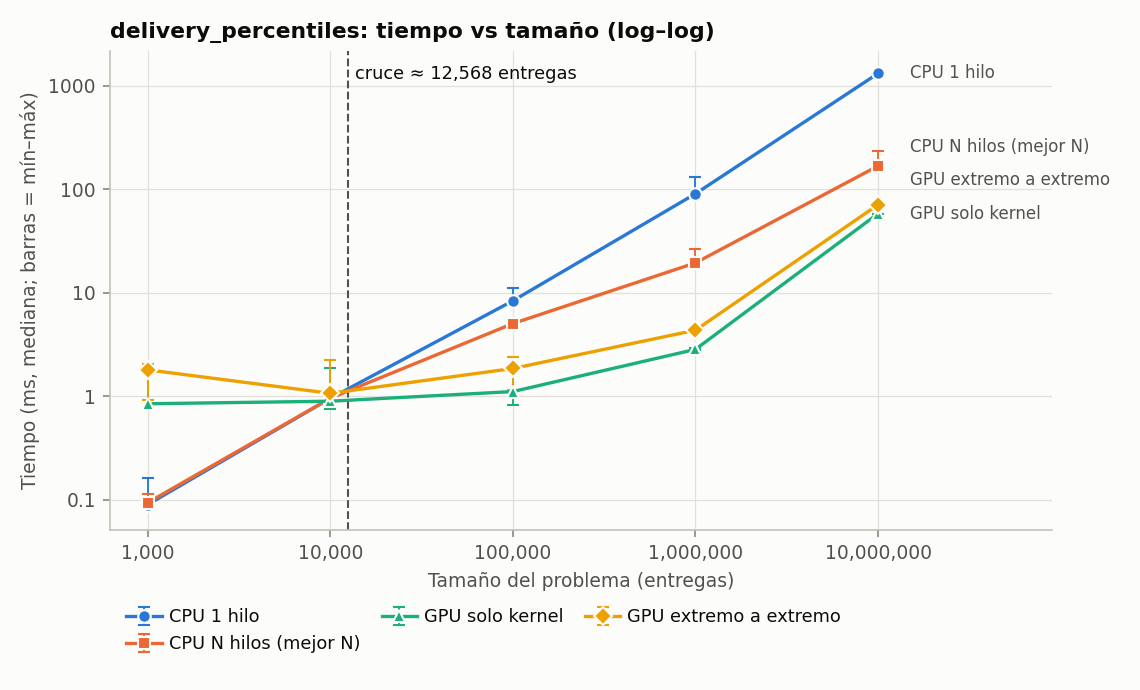

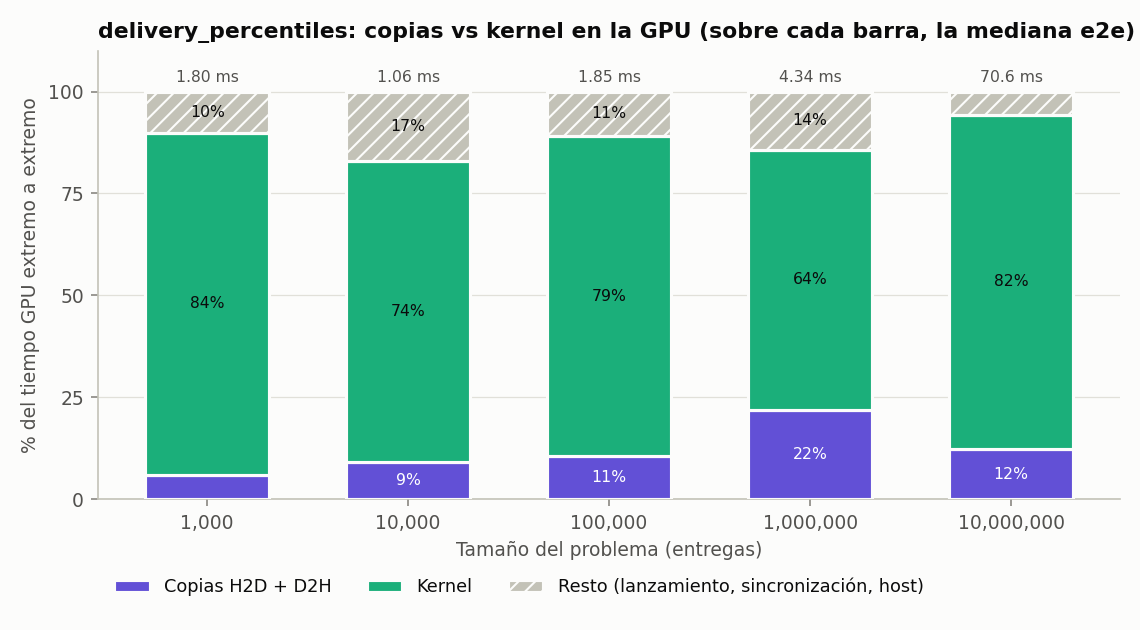

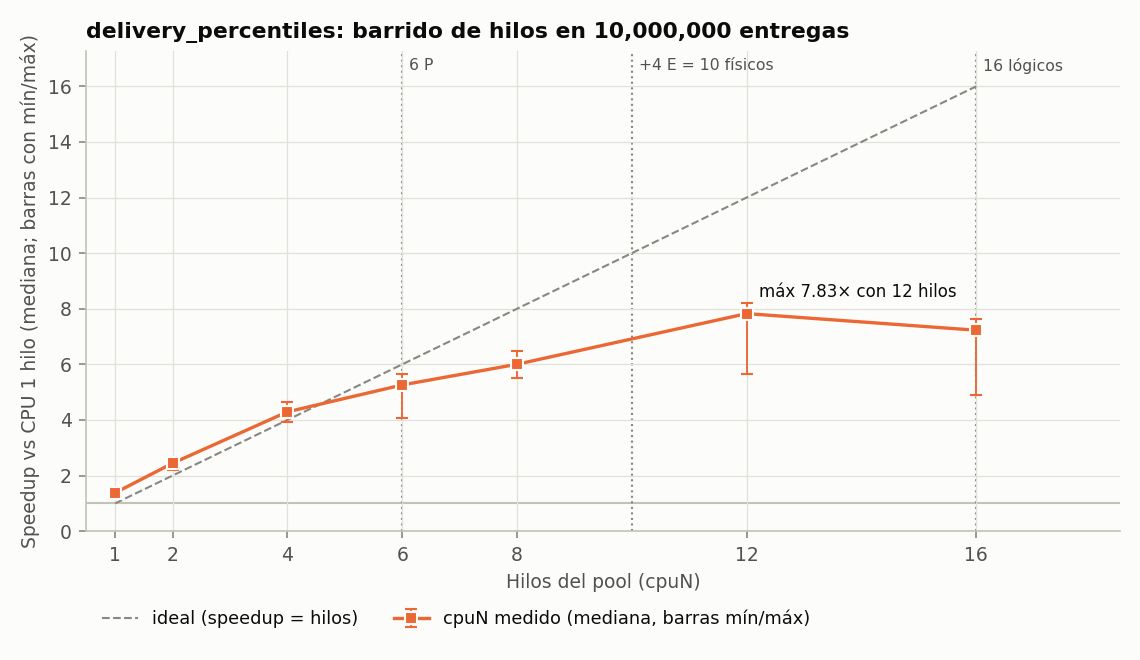

### delivery_timeline: Línea de tiempo global de entregas: fusión por pares (co-rank) de las listas ordenadas de 2000 couriers

Size = n = entregas totales, repartidas en 2000 listas.

| Size | CPU 1 thread (ms) | CPU N threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 1,000 | 0.115 | 0.118 (N=1) | 0.130 | 0.331 | 0.885× / 0.348× | sí (100/100) |
| 10,000 | 0.537 | 0.536 (N=1) | 0.156 | 0.374 | 3.43× / 1.43× | sí (100/100) |
| 100,000 | 5.04 | 2.46 (N=8) | 0.289 | 0.921 | 8.50× / 2.67× | sí (100/100) |
| 1,000,000 | 46.5 | 11.6 (N=16) | 1.59 | 4.08 | 7.34× / 2.86× | sí (100/100) |
| 10,000,000 | 372 | 109 (N=12) | 18.0 | 40.5 | 6.07× / 2.70× | sí (100/100) |

N = el mejor numero de hilos del barrido en cada tamano (entre parentesis). Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: ≈ 5,565 entregas (entre 1,000 y 10,000) → **usar GPU sobre el umbral**
- Crossover solo kernel: ≈ 1,230 entregas (entre 1,000 y 10,000)

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 1,000 | cpu1 | 1 | 10 | 0.115 | 0.112 | 0.137 | 0.00707 | 22% |
| 1,000 | cpuN | 1 | 10 | 0.118 | 0.106 | 0.143 | 0.0141 | 31% |
| 1,000 | gpu_kernel | 1 | 10 | 0.130 | 0.103 | 0.188 | 0.0251 | 65% (alta) |
| 1,000 | gpu_e2e | 1 | 10 | 0.331 | 0.259 | 0.396 | 0.0592 | 41% |
| 10,000 | cpu1 | 1 | 10 | 0.537 | 0.528 | 0.592 | 0.00930 | 12% |
| 10,000 | cpuN | 1 | 10 | 0.536 | 0.517 | 0.565 | 0.0229 | 9% |
| 10,000 | gpu_kernel | 1 | 10 | 0.156 | 0.114 | 0.234 | 0.0348 | 77% (alta) |
| 10,000 | gpu_e2e | 1 | 10 | 0.374 | 0.320 | 0.440 | 0.0419 | 32% |
| 100,000 | cpu1 | 1 | 10 | 5.04 | 4.48 | 7.22 | 0.608 | 54% (alta) |
| 100,000 | cpuN | 8 | 10 | 2.46 | 2.28 | 11.9 | 0.339 | 394% (alta) |
| 100,000 | gpu_kernel | 1 | 10 | 0.289 | 0.269 | 0.321 | 0.0231 | 18% |
| 100,000 | gpu_e2e | 1 | 10 | 0.921 | 0.713 | 1.23 | 0.313 | 56% (alta) |
| 1,000,000 | cpu1 | 1 | 10 | 46.5 | 45.1 | 69.1 | 6.86 | 52% (alta) |
| 1,000,000 | cpuN | 16 | 10 | 11.6 | 8.71 | 27.2 | 0.739 | 159% (alta) |
| 1,000,000 | gpu_kernel | 1 | 10 | 1.59 | 1.56 | 1.64 | 0.0118 | 5% |
| 1,000,000 | gpu_e2e | 1 | 10 | 4.08 | 3.93 | 5.26 | 0.155 | 32% |
| 10,000,000 | cpu1 | 1 | 10 | 372 | 363 | 394 | 12.7 | 8% |
| 10,000,000 | cpuN | 12 | 10 | 109 | 104 | 124 | 6.26 | 18% |
| 10,000,000 | gpu_kernel | 1 | 10 | 18.0 | 17.9 | 18.0 | 0.0322 | 1% |
| 10,000,000 | gpu_e2e | 1 | 10 | 40.5 | 39.3 | 41.3 | 0.923 | 5% |

**Barrido de hilos (10,000,000)**

| Hilos | Mediana (ms) | Speedup vs CPU 1 thread | Rango (con mín/máx) | Eficiencia |
|---|---|---|---|---|
| 1 | 364 | 1.02× | 0.874–1.05 | 102% |
| 2 | 229 | 1.62× | 1.57–1.66 | 81% |
| 4 | 152 | 2.45× | 2.23–2.62 | 61% |
| 6 | 133 | 2.81× | 2.65–2.95 | 47% |
| 8 | 123 | 3.02× | 2.82–3.12 | 38% |
| 12 | 109 | 3.41× | 3.01–3.57 | 28% |
| 16 | 111 | 3.34× | 3.00–3.44 | 21% |

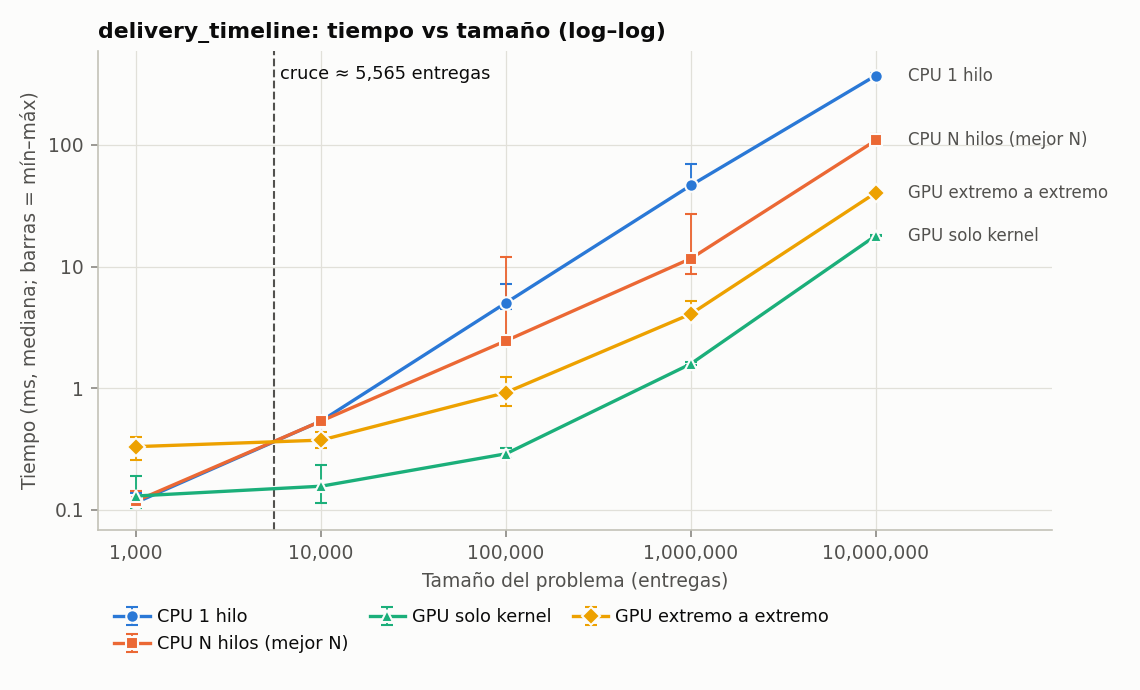

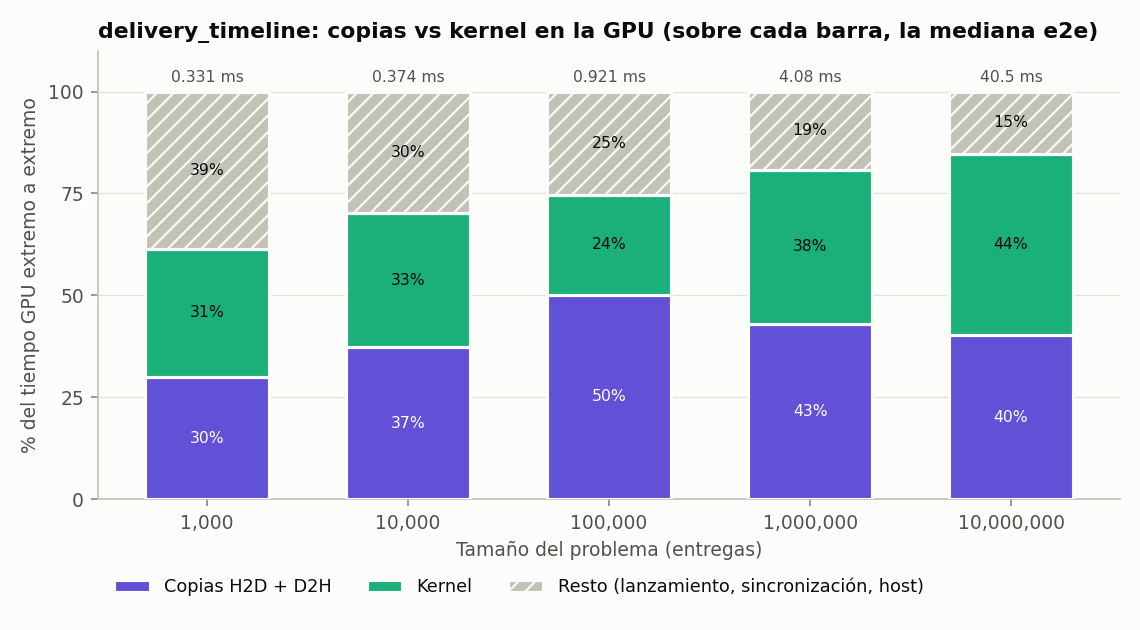

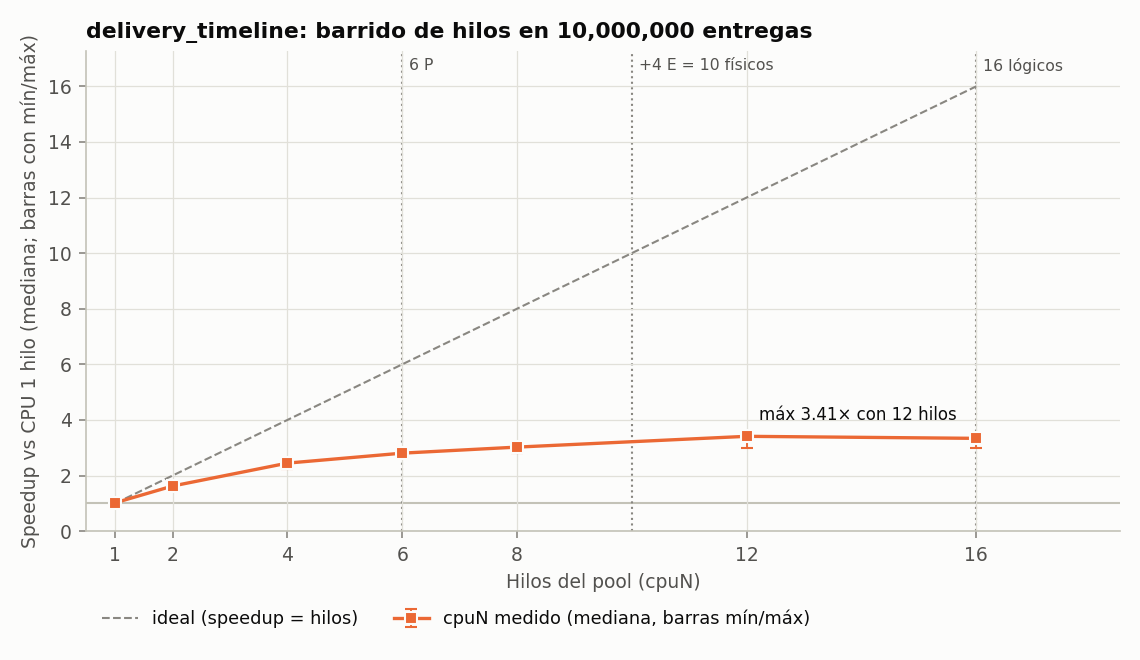

### demand_heatmap: Mapa de calor de la demanda: convolución 2D con filtro gaussiano 7 × 7 en memoria constante

Size = n = lado de la grilla (n × n celdas).

| Size | CPU 1 thread (ms) | CPU N threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 16 | 0.00500 | 0.00530 (N=1) | 0.0133 | 0.235 | 0.376× / 0.0212× | sí (100/100) |
| 32 | 0.0196 | 0.0193 (N=1) | 0.0289 | 0.218 | 0.669× / 0.0885× | sí (100/100) |
| 64 | 0.0773 | 0.0784 (N=1) | 0.0247 | 0.208 | 3.13× / 0.372× | sí (100/100) |
| 100 | 0.203 | 0.149 (N=2) | 0.0252 | 0.237 | 5.91× / 0.629× | sí (100/100) |
| 128 | 0.365 | 0.228 (N=8) | 0.0266 | 0.297 | 8.59× / 0.770× | sí (100/100) |
| 256 | 1.64 | 0.487 (N=12) | 0.0659 | 0.390 | 7.38× / 1.25× | sí (100/100) |
| 512 | 6.30 | 1.27 (N=12) | 0.117 | 0.629 | 10.9× / 2.02× | sí (100/100) |
| 1,024 | 24.4 | 4.43 (N=12) | 0.244 | 1.49 | 18.1× / 2.97× | sí (100/100) |
| 2,048 | 97.1 | 17.4 (N=12) | 0.737 | 6.23 | 23.6× / 2.79× | sí (100/100) |

N = el mejor numero de hilos del barrido en cada tamano (entre parentesis). Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: ≈ 186 celdas por lado (entre 128 y 256) → **usar GPU sobre el umbral**
- Crossover solo kernel: ≈ 38.3 celdas por lado (entre 32 y 64)

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 16 | cpu1 | 1 | 10 | 0.00500 | 0.00462 | 0.00552 | 0.000317 | 18% |
| 16 | cpuN | 1 | 10 | 0.00530 | 0.00496 | 0.00624 | 0.000420 | 24% |
| 16 | gpu_kernel | 1 | 10 | 0.0133 | 0.0115 | 0.0856 | 0.0242 | 556% (alta) |
| 16 | gpu_e2e | 1 | 10 | 0.235 | 0.164 | 0.340 | 0.0631 | 75% (alta) |
| 32 | cpu1 | 1 | 10 | 0.0196 | 0.0183 | 0.0403 | 0.00552 | 112% (alta) |
| 32 | cpuN | 1 | 10 | 0.0193 | 0.0186 | 0.0316 | 0.000631 | 68% (alta) |
| 32 | gpu_kernel | 1 | 10 | 0.0289 | 0.0129 | 0.0742 | 0.0416 | 213% (alta) |
| 32 | gpu_e2e | 1 | 10 | 0.218 | 0.160 | 0.319 | 0.0561 | 73% (alta) |
| 64 | cpu1 | 1 | 10 | 0.0773 | 0.0767 | 0.0932 | 0.00146 | 21% |
| 64 | cpuN | 1 | 10 | 0.0784 | 0.0749 | 0.0901 | 0.00518 | 19% |
| 64 | gpu_kernel | 1 | 10 | 0.0247 | 0.0125 | 0.0728 | 0.0312 | 244% (alta) |
| 64 | gpu_e2e | 1 | 10 | 0.208 | 0.149 | 0.252 | 0.0591 | 50% |
| 100 | cpu1 | 1 | 10 | 0.203 | 0.194 | 0.229 | 0.00591 | 18% |
| 100 | cpuN | 2 | 10 | 0.149 | 0.128 | 0.354 | 0.121 | 151% (alta) |
| 100 | gpu_kernel | 1 | 10 | 0.0252 | 0.0162 | 0.0639 | 0.0125 | 189% (alta) |
| 100 | gpu_e2e | 1 | 10 | 0.237 | 0.178 | 0.348 | 0.0783 | 72% (alta) |
| 128 | cpu1 | 1 | 10 | 0.365 | 0.340 | 0.388 | 0.0259 | 13% |
| 128 | cpuN | 8 | 10 | 0.228 | 0.192 | 0.289 | 0.0418 | 43% |
| 128 | gpu_kernel | 1 | 10 | 0.0266 | 0.0171 | 0.0991 | 0.0592 | 309% (alta) |
| 128 | gpu_e2e | 1 | 10 | 0.297 | 0.219 | 0.387 | 0.115 | 57% (alta) |
| 256 | cpu1 | 1 | 10 | 1.64 | 1.53 | 1.85 | 0.0638 | 20% |
| 256 | cpuN | 12 | 10 | 0.487 | 0.389 | 0.739 | 0.0805 | 72% (alta) |
| 256 | gpu_kernel | 1 | 10 | 0.0659 | 0.0296 | 0.103 | 0.0554 | 112% (alta) |
| 256 | gpu_e2e | 1 | 10 | 0.390 | 0.318 | 0.526 | 0.0550 | 53% (alta) |
| 512 | cpu1 | 1 | 10 | 6.30 | 6.12 | 6.60 | 0.141 | 8% |
| 512 | cpuN | 12 | 10 | 1.27 | 1.21 | 1.33 | 0.0584 | 9% |
| 512 | gpu_kernel | 1 | 10 | 0.117 | 0.102 | 0.185 | 0.0135 | 71% (alta) |
| 512 | gpu_e2e | 1 | 10 | 0.629 | 0.574 | 0.838 | 0.0855 | 42% |
| 1,024 | cpu1 | 1 | 10 | 24.4 | 23.6 | 28.5 | 1.11 | 20% |
| 1,024 | cpuN | 12 | 10 | 4.43 | 4.21 | 4.69 | 0.121 | 11% |
| 1,024 | gpu_kernel | 1 | 10 | 0.244 | 0.221 | 0.269 | 0.0122 | 20% |
| 1,024 | gpu_e2e | 1 | 10 | 1.49 | 1.45 | 1.79 | 0.0937 | 23% |
| 2,048 | cpu1 | 1 | 10 | 97.1 | 90.9 | 184 | 7.08 | 96% (alta) |
| 2,048 | cpuN | 12 | 10 | 17.4 | 16.7 | 24.2 | 2.89 | 43% |
| 2,048 | gpu_kernel | 1 | 10 | 0.737 | 0.708 | 0.759 | 0.0144 | 7% |
| 2,048 | gpu_e2e | 1 | 10 | 6.23 | 5.30 | 7.57 | 1.16 | 36% |

**Barrido de hilos (2,048)**

| Hilos | Mediana (ms) | Speedup vs CPU 1 thread | Rango (con mín/máx) | Eficiencia |
|---|---|---|---|---|
| 1 | 91.2 | 1.06× | 0.952–1.10 | 106% |
| 2 | 49.1 | 1.98× | 1.07–2.09 | 99% |
| 4 | 26.9 | 3.61× | 2.34–3.89 | 90% |
| 6 | 24.5 | 3.96× | 2.72–4.64 | 66% |
| 8 | 22.6 | 4.29× | 3.75–5.02 | 54% |
| 12 | 17.4 | 5.58× | 4.02–5.83 | 47% |
| 16 | 17.9 | 5.43× | 4.34–6.00 | 34% |

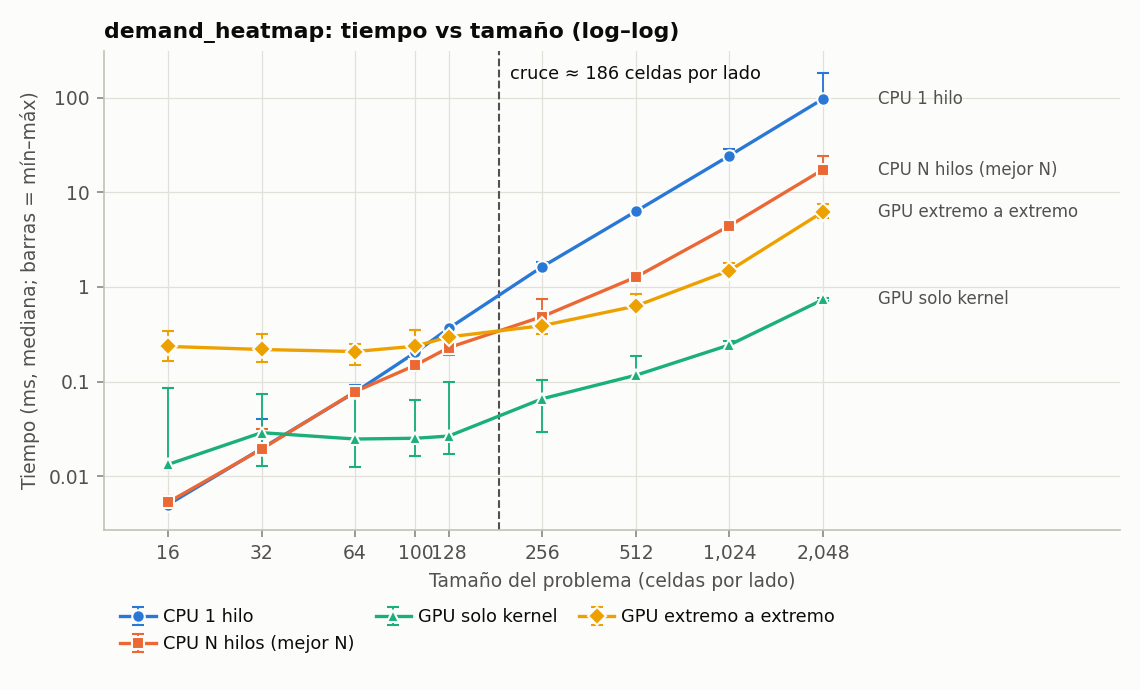

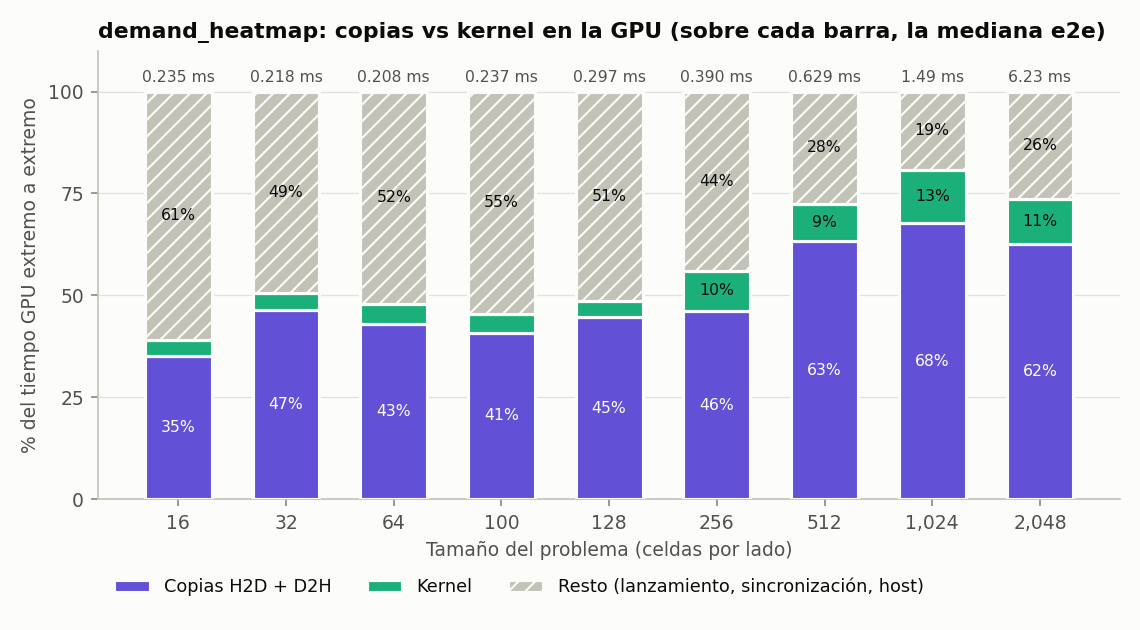

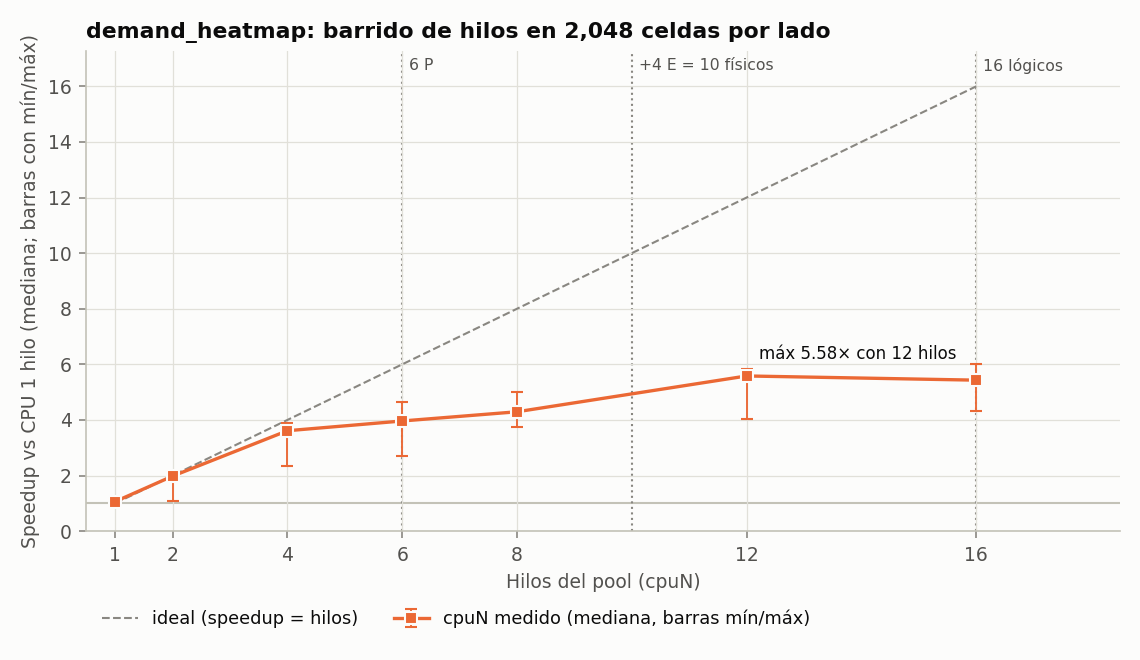

### demand_heatmap_tiles: Variante de comparación: el mismo filtro con tile de 16 × 16 + halo en memoria compartida

Size = n = lado de la grilla.

| Size | CPU 1 thread (ms) | CPU N threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 16 | 0.00488 | 0.00560 (N=1) | 0.0452 | 0.291 | 0.108× / 0.0168× | sí (100/100) |
| 32 | 0.0186 | 0.0194 (N=1) | 0.0276 | 0.170 | 0.674× / 0.110× | sí (100/100) |
| 64 | 0.0807 | 0.0765 (N=2) | 0.0173 | 0.184 | 4.42× / 0.417× | sí (100/100) |
| 100 | 0.192 | 0.119 (N=4) | 0.0334 | 0.214 | 3.55× / 0.554× | sí (100/100) |
| 128 | 0.325 | 0.194 (N=4) | 0.0190 | 0.229 | 10.2× / 0.846× | sí (100/100) |
| 256 | 1.31 | 0.397 (N=16) | 0.0377 | 0.356 | 10.6× / 1.12× | sí (100/100) |
| 512 | 8.78 | 1.79 (N=16) | 0.124 | 0.876 | 10.2× / 1.45× | sí (100/100) |
| 1,024 | 23.7 | 4.46 (N=12) | 0.186 | 1.62 | 23.8× / 2.74× | sí (100/100) |
| 2,048 | 94.9 | 18.6 (N=16) | 0.502 | 5.43 | 34.7× / 3.20× | sí (100/100) |

N = el mejor numero de hilos del barrido en cada tamano (entre parentesis). Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: ≈ 195 celdas por lado (entre 128 y 256) → **usar GPU sobre el umbral**
- Crossover solo kernel: ≈ 37.0 celdas por lado (entre 32 y 64)

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 16 | cpu1 | 1 | 10 | 0.00488 | 0.00431 | 0.00575 | 0.00112 | 30% |
| 16 | cpuN | 1 | 10 | 0.00560 | 0.00458 | 0.00663 | 0.000949 | 37% |
| 16 | gpu_kernel | 1 | 10 | 0.0452 | 0.0141 | 0.125 | 0.0477 | 245% (alta) |
| 16 | gpu_e2e | 1 | 10 | 0.291 | 0.224 | 0.316 | 0.0262 | 31% |
| 32 | cpu1 | 1 | 10 | 0.0186 | 0.0182 | 0.0189 | 0.000265 | 4% |
| 32 | cpuN | 1 | 10 | 0.0194 | 0.0184 | 0.0211 | 0.00102 | 14% |
| 32 | gpu_kernel | 1 | 10 | 0.0276 | 0.00998 | 0.0732 | 0.0350 | 229% (alta) |
| 32 | gpu_e2e | 1 | 10 | 0.170 | 0.136 | 0.272 | 0.0704 | 80% (alta) |
| 64 | cpu1 | 1 | 10 | 0.0807 | 0.0731 | 0.116 | 0.0112 | 53% (alta) |
| 64 | cpuN | 2 | 10 | 0.0765 | 0.0657 | 0.117 | 0.0181 | 67% (alta) |
| 64 | gpu_kernel | 1 | 10 | 0.0173 | 0.0126 | 0.0484 | 0.0247 | 206% (alta) |
| 64 | gpu_e2e | 1 | 10 | 0.184 | 0.137 | 0.295 | 0.0671 | 86% (alta) |
| 100 | cpu1 | 1 | 10 | 0.192 | 0.185 | 0.220 | 0.00797 | 18% |
| 100 | cpuN | 4 | 10 | 0.119 | 0.102 | 0.246 | 0.0565 | 121% (alta) |
| 100 | gpu_kernel | 1 | 10 | 0.0334 | 0.0147 | 0.0616 | 0.0398 | 140% (alta) |
| 100 | gpu_e2e | 1 | 10 | 0.214 | 0.160 | 0.283 | 0.0637 | 58% (alta) |
| 128 | cpu1 | 1 | 10 | 0.325 | 0.311 | 0.334 | 0.0114 | 7% |
| 128 | cpuN | 4 | 10 | 0.194 | 0.142 | 0.318 | 0.0991 | 90% (alta) |
| 128 | gpu_kernel | 1 | 10 | 0.0190 | 0.0152 | 0.100 | 0.0133 | 447% (alta) |
| 128 | gpu_e2e | 1 | 10 | 0.229 | 0.180 | 0.308 | 0.0620 | 56% (alta) |
| 256 | cpu1 | 1 | 10 | 1.31 | 1.22 | 1.76 | 0.0985 | 42% |
| 256 | cpuN | 16 | 10 | 0.397 | 0.329 | 0.713 | 0.0877 | 97% (alta) |
| 256 | gpu_kernel | 1 | 10 | 0.0377 | 0.0211 | 0.103 | 0.0368 | 218% (alta) |
| 256 | gpu_e2e | 1 | 10 | 0.356 | 0.241 | 1.09 | 0.110 | 239% (alta) |
| 512 | cpu1 | 1 | 10 | 8.78 | 7.03 | 15.2 | 2.65 | 93% (alta) |
| 512 | cpuN | 16 | 10 | 1.79 | 1.44 | 2.93 | 0.713 | 83% (alta) |
| 512 | gpu_kernel | 1 | 10 | 0.124 | 0.0979 | 0.310 | 0.0221 | 171% (alta) |
| 512 | gpu_e2e | 1 | 10 | 0.876 | 0.708 | 1.12 | 0.127 | 46% |
| 1,024 | cpu1 | 1 | 10 | 23.7 | 22.3 | 30.3 | 1.77 | 33% |
| 1,024 | cpuN | 12 | 10 | 4.46 | 4.24 | 7.25 | 0.387 | 67% (alta) |
| 1,024 | gpu_kernel | 1 | 10 | 0.186 | 0.178 | 0.288 | 0.00685 | 59% (alta) |
| 1,024 | gpu_e2e | 1 | 10 | 1.62 | 1.42 | 2.31 | 0.479 | 55% (alta) |
| 2,048 | cpu1 | 1 | 10 | 94.9 | 91.5 | 99.0 | 2.66 | 8% |
| 2,048 | cpuN | 16 | 10 | 18.6 | 16.0 | 22.6 | 2.36 | 35% |
| 2,048 | gpu_kernel | 1 | 10 | 0.502 | 0.492 | 0.520 | 0.0110 | 6% |
| 2,048 | gpu_e2e | 1 | 10 | 5.43 | 5.12 | 6.45 | 0.825 | 24% |

**Barrido de hilos (2,048)**

| Hilos | Mediana (ms) | Speedup vs CPU 1 thread | Rango (con mín/máx) | Eficiencia |
|---|---|---|---|---|
| 1 | 92.9 | 1.02× | 0.943–1.04 | 102% |
| 2 | 49.3 | 1.92× | 1.53–2.05 | 96% |
| 4 | 29.9 | 3.17× | 2.17–3.57 | 79% |
| 6 | 27.2 | 3.48× | 2.91–4.41 | 58% |
| 8 | 24.3 | 3.90× | 3.54–4.42 | 49% |
| 12 | 19.1 | 4.98× | 3.72–5.31 | 41% |
| 16 | 18.6 | 5.09× | 4.20–5.93 | 32% |

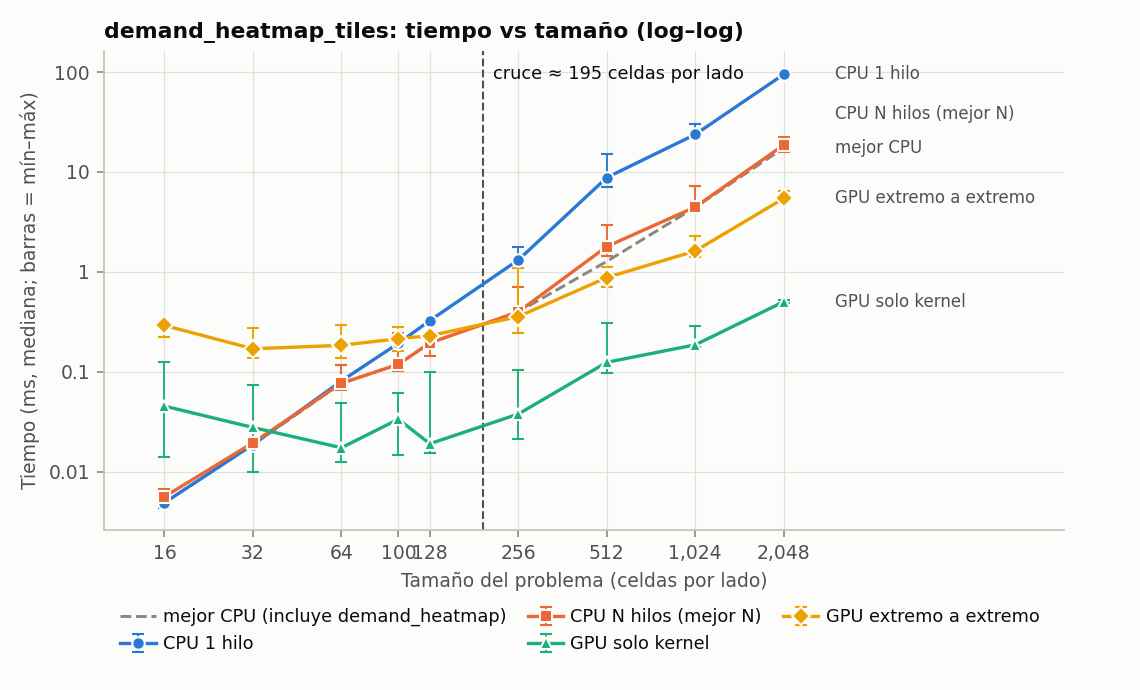

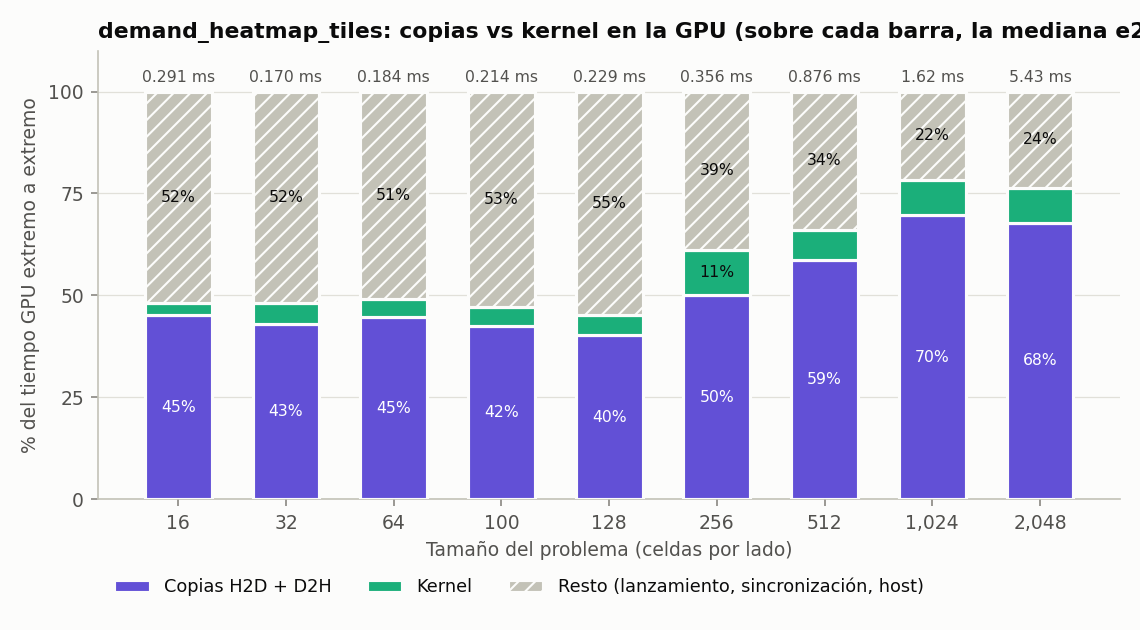

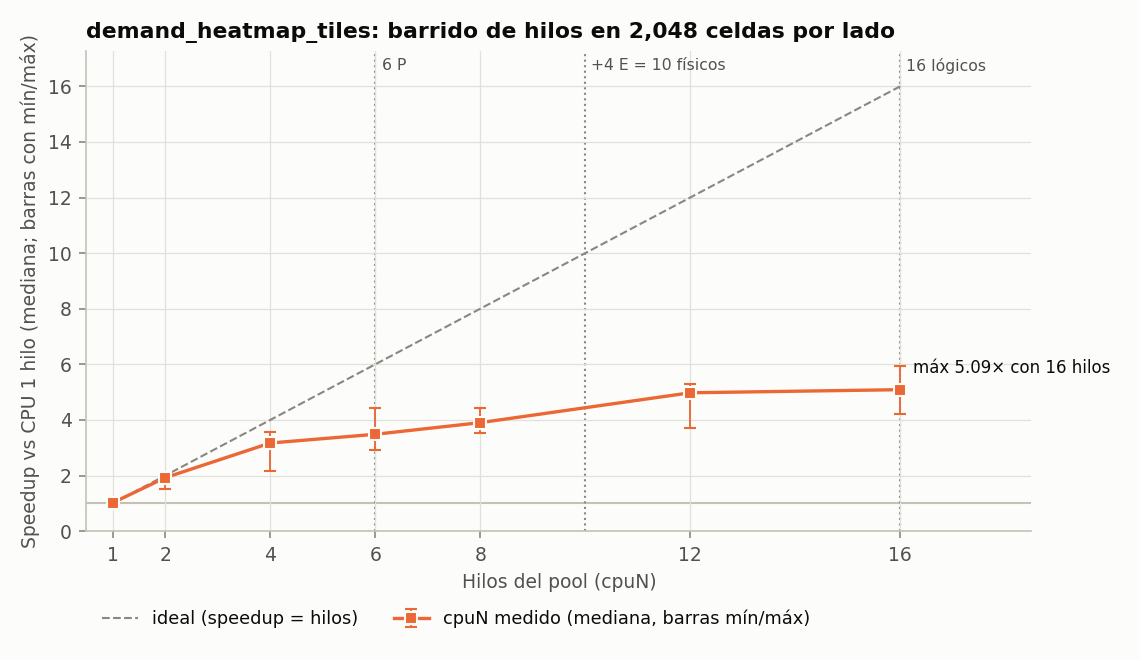

### eta_batch_soa: ETA en lote, matriz pedidos × couriers, couriers en estructura de arreglos (SoA, lecturas coalescidas)

Size = n = couriers (columnas); m pedidos (filas): 50→10, 150→30, 500→100, 2000→300, 5000→600, otro → n/8.

| Size | CPU 1 thread (ms) | CPU N threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 50 | 0.00643 | 0.00571 (N=1) | 0.0145 | 5.77 | 0.393× / 0.000990× | sí (100/100) |
| 150 | 0.0395 | 0.0291 (N=1) | 0.0151 | 5.97 | 1.93× / 0.00487× | sí (100/100) |
| 500 | 0.448 | 0.162 (N=4) | 0.0665 | 6.42 | 2.44× / 0.0253× | sí (100/100) |
| 777 | 0.646 | 0.168 (N=4) | 0.0696 | 6.09 | 2.42× / 0.0277× | sí (100/100) |
| 2,000 | 6.55 | 0.923 (N=12) | 0.133 | 6.58 | 6.94× / 0.140× | sí (100/100) |
| 5,000 | 30.6 | 5.20 (N=16) | 0.803 | 8.34 | 6.47× / 0.623× | sí (100/100) |

N = el mejor numero de hilos del barrido en cada tamano (entre parentesis). Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: no hay cruce (la GPU no gana en el rango medido) → **mantener CPU**
- Crossover solo kernel: ≈ 95.4 couriers (entre 50 y 150)

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 50 | cpu1 | 1 | 10 | 0.00643 | 0.00564 | 0.0190 | 0.00109 | 208% (alta) |
| 50 | cpuN | 1 | 10 | 0.00571 | 0.00229 | 0.0131 | 0.00183 | 190% (alta) |
| 50 | gpu_kernel | 1 | 10 | 0.0145 | 0.0120 | 0.0827 | 0.0304 | 486% (alta) |
| 50 | gpu_e2e | 1 | 10 | 5.77 | 5.63 | 7.93 | 0.144 | 40% |
| 150 | cpu1 | 1 | 10 | 0.0395 | 0.0357 | 0.0494 | 0.00574 | 35% |
| 150 | cpuN | 1 | 10 | 0.0291 | 0.0211 | 0.0457 | 0.0126 | 85% (alta) |
| 150 | gpu_kernel | 1 | 10 | 0.0151 | 0.0114 | 0.0835 | 0.00858 | 477% (alta) |
| 150 | gpu_e2e | 1 | 10 | 5.97 | 5.53 | 6.38 | 0.351 | 14% |
| 500 | cpu1 | 1 | 10 | 0.448 | 0.364 | 0.843 | 0.144 | 107% (alta) |
| 500 | cpuN | 4 | 10 | 0.162 | 0.114 | 0.235 | 0.0479 | 75% (alta) |
| 500 | gpu_kernel | 1 | 10 | 0.0665 | 0.0172 | 0.101 | 0.0555 | 126% (alta) |
| 500 | gpu_e2e | 1 | 10 | 6.42 | 5.93 | 8.04 | 0.641 | 33% |
| 777 | cpu1 | 1 | 10 | 0.646 | 0.561 | 0.752 | 0.0928 | 30% |
| 777 | cpuN | 4 | 10 | 0.168 | 0.126 | 0.424 | 0.0469 | 177% (alta) |
| 777 | gpu_kernel | 1 | 10 | 0.0696 | 0.0227 | 0.115 | 0.0821 | 133% (alta) |
| 777 | gpu_e2e | 1 | 10 | 6.09 | 5.60 | 8.09 | 1.13 | 41% |
| 2,000 | cpu1 | 1 | 10 | 6.55 | 6.28 | 7.68 | 0.185 | 21% |
| 2,000 | cpuN | 12 | 10 | 0.923 | 0.814 | 1.09 | 0.100 | 30% |
| 2,000 | gpu_kernel | 1 | 10 | 0.133 | 0.115 | 0.139 | 0.00498 | 19% |
| 2,000 | gpu_e2e | 1 | 10 | 6.58 | 6.29 | 7.96 | 1.33 | 25% |
| 5,000 | cpu1 | 1 | 10 | 30.6 | 29.4 | 37.6 | 2.71 | 27% |
| 5,000 | cpuN | 16 | 10 | 5.20 | 4.50 | 7.63 | 0.798 | 60% (alta) |
| 5,000 | gpu_kernel | 1 | 10 | 0.803 | 0.783 | 0.813 | 0.00557 | 4% |
| 5,000 | gpu_e2e | 1 | 10 | 8.34 | 8.03 | 9.60 | 0.513 | 19% |

**Barrido de hilos (5,000)**

| Hilos | Mediana (ms) | Speedup vs CPU 1 thread | Rango (con mín/máx) | Eficiencia |
|---|---|---|---|---|
| 1 | 30.4 | 1.01× | 0.904–1.09 | 101% |
| 2 | 15.1 | 2.02× | 1.91–2.12 | 101% |
| 4 | 8.35 | 3.67× | 3.48–3.96 | 92% |
| 6 | 6.79 | 4.51× | 3.16–5.39 | 75% |
| 8 | 7.21 | 4.25× | 3.54–5.56 | 53% |
| 12 | 5.63 | 5.43× | 4.86–5.98 | 45% |
| 16 | 5.20 | 5.89× | 4.01–6.80 | 37% |

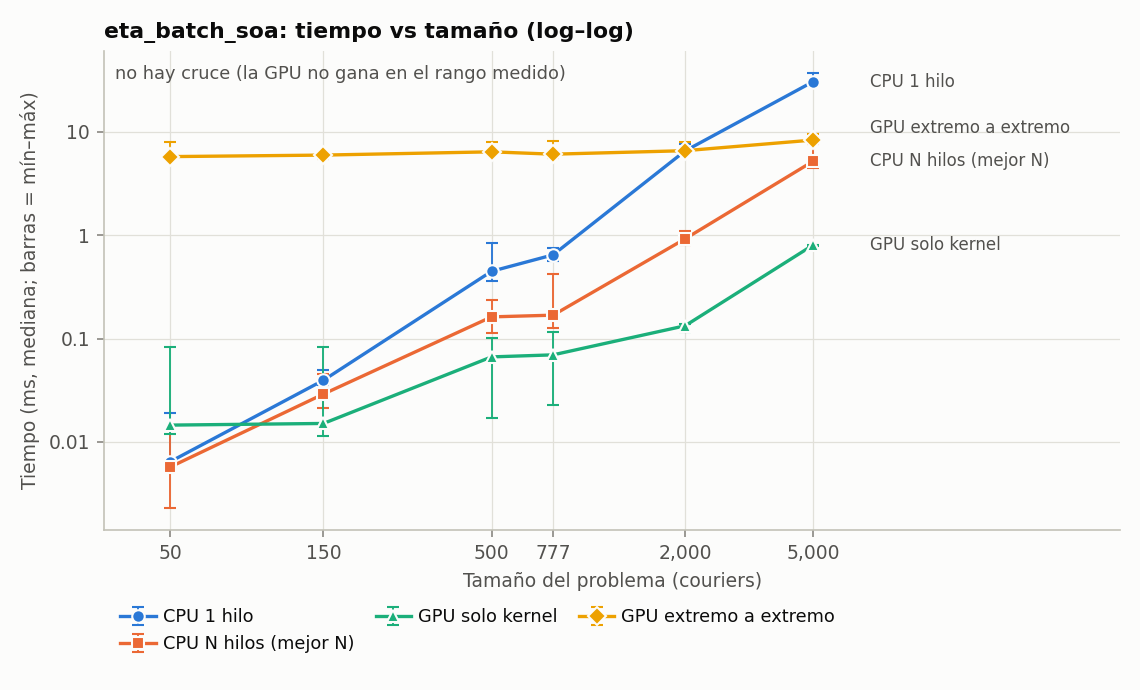

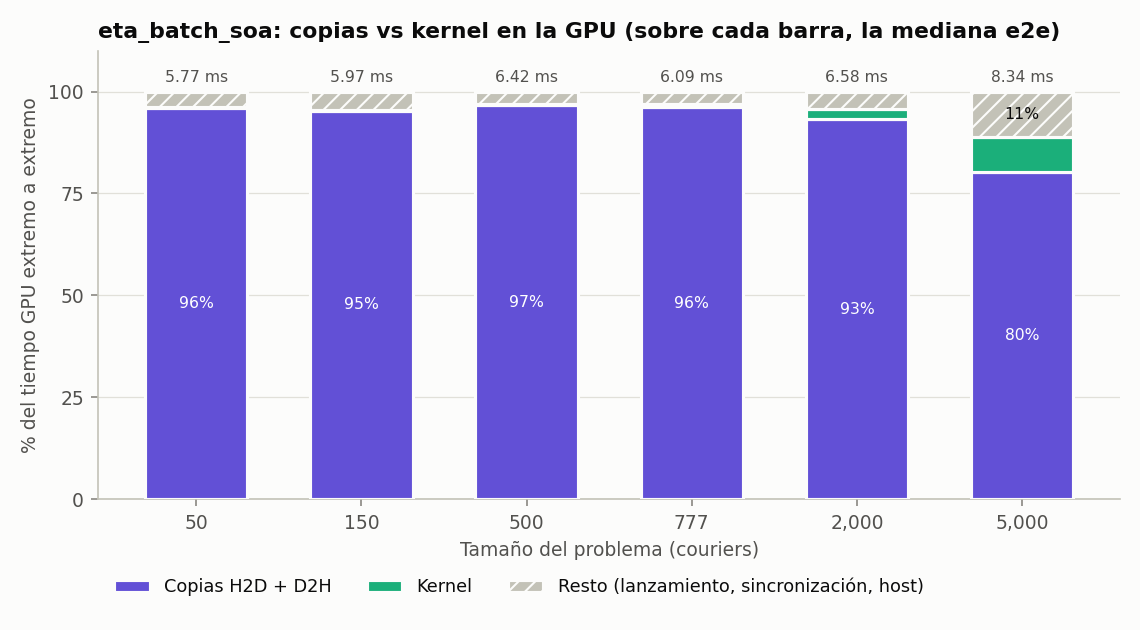

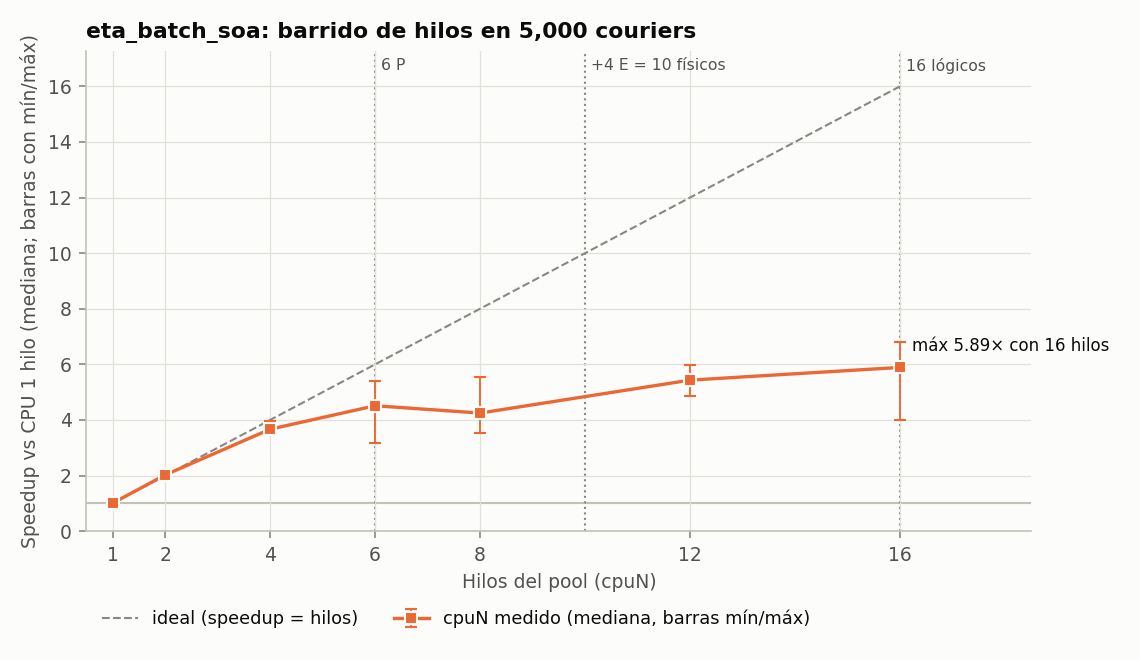

### eta_batch_aos: Variante de comparación: los mismos pares con couriers en arreglo de estructuras (AoS, registros de 32 B)

Size = igual que eta_batch_soa.

| Size | CPU 1 thread (ms) | CPU N threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 50 | 0.00809 | n/d | 0.0127 | 5.75 | 0.449× / 0.000993× | sí (30/30) |
| 150 | 0.0510 | n/d | 0.0172 | 5.90 | 1.69× / 0.00492× | sí (30/30) |
| 500 | 0.468 | n/d | 0.0380 | 5.80 | 4.27× / 0.0280× | sí (30/30) |
| 777 | 0.701 | n/d | 0.0192 | 5.79 | 8.76× / 0.0291× | sí (30/30) |
| 2,000 | 6.18 | n/d | 0.0838 | 6.16 | 11.0× / 0.150× | sí (30/30) |
| 5,000 | 34.5 | n/d | 0.807 | 9.24 | 6.44× / 0.563× | sí (30/30) |

N = el mejor numero de hilos del barrido en cada tamano (entre parentesis). Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: no hay cruce (la GPU no gana en el rango medido) → **mantener CPU**
- Crossover solo kernel: ≈ 97.1 couriers (entre 50 y 150)

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 50 | cpu1 | 1 | 10 | 0.00809 | 0.00509 | 0.00941 | 0.00225 | 53% (alta) |
| 50 | gpu_kernel | 1 | 10 | 0.0127 | 0.0111 | 0.0516 | 0.00537 | 318% (alta) |
| 50 | gpu_e2e | 1 | 10 | 5.75 | 5.58 | 6.92 | 0.528 | 23% |
| 150 | cpu1 | 1 | 10 | 0.0510 | 0.0425 | 0.0568 | 0.00711 | 28% |
| 150 | gpu_kernel | 1 | 10 | 0.0172 | 0.0111 | 0.0891 | 0.0326 | 453% (alta) |
| 150 | gpu_e2e | 1 | 10 | 5.90 | 5.64 | 6.22 | 0.233 | 10% |
| 500 | cpu1 | 1 | 10 | 0.468 | 0.285 | 0.551 | 0.107 | 57% (alta) |
| 500 | gpu_kernel | 1 | 10 | 0.0380 | 0.0156 | 0.0556 | 0.0236 | 105% (alta) |
| 500 | gpu_e2e | 1 | 10 | 5.80 | 5.54 | 7.62 | 0.148 | 36% |
| 777 | cpu1 | 1 | 10 | 0.701 | 0.470 | 0.781 | 0.207 | 44% |
| 777 | gpu_kernel | 1 | 10 | 0.0192 | 0.0173 | 0.0591 | 0.0171 | 217% (alta) |
| 777 | gpu_e2e | 1 | 10 | 5.79 | 5.52 | 6.64 | 0.293 | 19% |
| 2,000 | cpu1 | 1 | 10 | 6.18 | 5.87 | 6.58 | 0.407 | 12% |
| 2,000 | gpu_kernel | 1 | 10 | 0.0838 | 0.0702 | 0.130 | 0.0191 | 72% (alta) |
| 2,000 | gpu_e2e | 1 | 10 | 6.16 | 5.92 | 8.41 | 0.445 | 40% |
| 5,000 | cpu1 | 1 | 10 | 34.5 | 31.0 | 39.8 | 2.76 | 25% |
| 5,000 | gpu_kernel | 1 | 10 | 0.807 | 0.745 | 0.824 | 0.0124 | 10% |
| 5,000 | gpu_e2e | 1 | 10 | 9.24 | 8.24 | 9.94 | 0.986 | 18% |

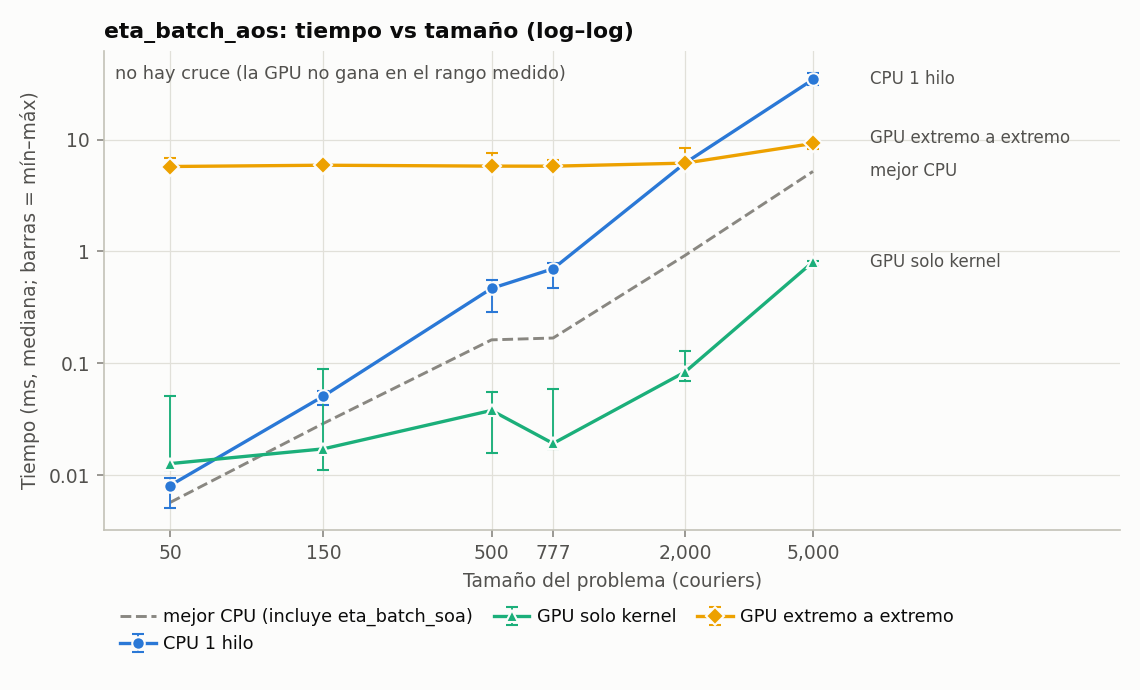

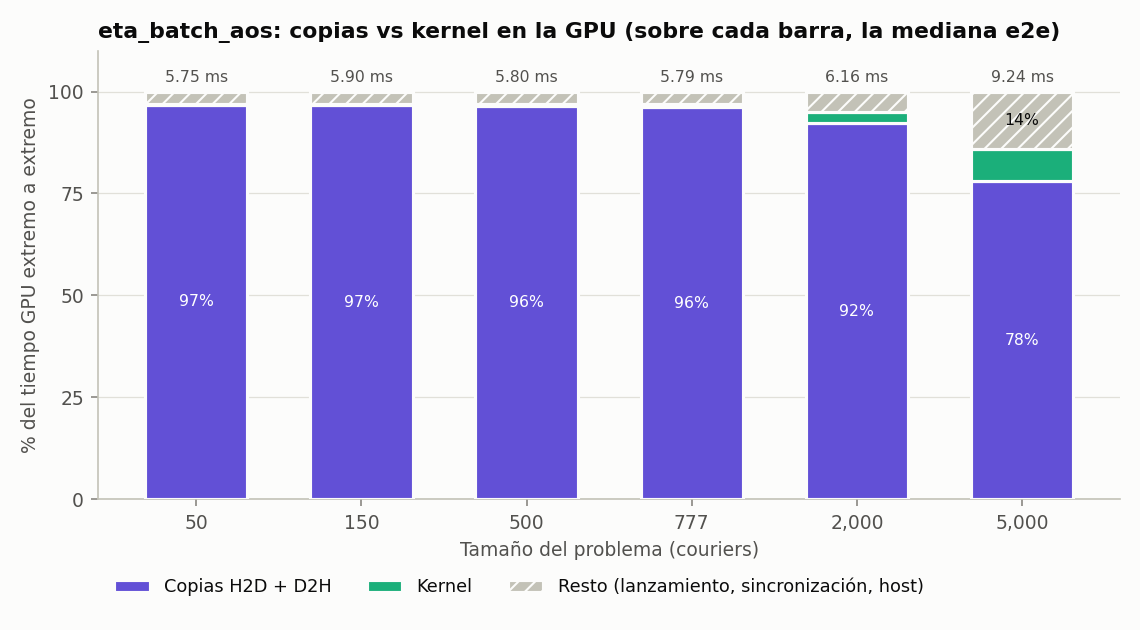

### orders_in_progress: Pedidos en curso a lo largo del tiempo y su pico: scan inclusivo jerárquico (Kogge-Stone) + máximo

Size = n = eventos (+1 pedido creado, −1 entregado o rechazado).

| Size | CPU 1 thread (ms) | CPU N threads (ms) | GPU kernel (ms) | GPU end to end (ms) | Speedup vs best CPU (kernel / end to end) | Correct? |
|---|---|---|---|---|---|---|
| 1,000 | 0.00148 | 0.00245 (N=1) | 0.0138 | 0.220 | 0.107× / 0.00674× | sí (100/100) |
| 10,000 | 0.0207 | 0.0206 (N=1) | 0.0153 | 0.274 | 1.35× / 0.0751× | sí (100/100) |
| 100,000 | 0.0810 | 0.0801 (N=1) | 0.0229 | 0.366 | 3.49× / 0.219× | sí (100/100) |
| 1,000,000 | 0.677 | 0.497 (N=2) | 0.0818 | 1.37 | 6.08× / 0.364× | sí (100/100) |
| 10,000,000 | 19.3 | 16.7 (N=12) | 1.21 | 22.0 | 13.8× / 0.761× | sí (100/100) |

N = el mejor numero de hilos del barrido en cada tamano (entre parentesis). Mejor CPU = min(CPU 1 thread, CPU N threads).

- Crossover extremo a extremo: no hay cruce (la GPU no gana en el rango medido) → **mantener CPU**
- Crossover solo kernel: ≈ 7,633 eventos (entre 1,000 y 10,000)

**Dispersión**

| Size | Versión | Hilos | n | Mediana (ms) | Mín (ms) | Máx (ms) | IQR (ms) | (máx−mín)/mediana |
|---|---|---|---|---|---|---|---|---|
| 1,000 | cpu1 | 1 | 10 | 0.00148 | 0.00126 | 0.00214 | 0.000281 | 60% (alta) |
| 1,000 | cpuN | 1 | 10 | 0.00245 | 0.00192 | 0.00337 | 0.000494 | 59% (alta) |
| 1,000 | gpu_kernel | 1 | 10 | 0.0138 | 0.0113 | 0.0696 | 0.0313 | 422% (alta) |
| 1,000 | gpu_e2e | 1 | 10 | 0.220 | 0.182 | 0.329 | 0.0307 | 67% (alta) |
| 10,000 | cpu1 | 1 | 10 | 0.0207 | 0.0196 | 0.0283 | 0.000863 | 42% |
| 10,000 | cpuN | 1 | 10 | 0.0206 | 0.0168 | 0.0362 | 0.00416 | 94% (alta) |
| 10,000 | gpu_kernel | 1 | 10 | 0.0153 | 0.0113 | 0.0809 | 0.00582 | 456% (alta) |
| 10,000 | gpu_e2e | 1 | 10 | 0.274 | 0.218 | 0.411 | 0.0382 | 70% (alta) |
| 100,000 | cpu1 | 1 | 10 | 0.0810 | 0.0760 | 0.208 | 0.00971 | 163% (alta) |
| 100,000 | cpuN | 1 | 10 | 0.0801 | 0.0764 | 0.112 | 0.0113 | 44% |
| 100,000 | gpu_kernel | 1 | 10 | 0.0229 | 0.0174 | 0.0643 | 0.0202 | 205% (alta) |
| 100,000 | gpu_e2e | 1 | 10 | 0.366 | 0.307 | 0.411 | 0.0433 | 28% |
| 1,000,000 | cpu1 | 1 | 10 | 0.677 | 0.527 | 0.786 | 0.0655 | 38% |
| 1,000,000 | cpuN | 2 | 10 | 0.497 | 0.440 | 0.574 | 0.0692 | 27% |
| 1,000,000 | gpu_kernel | 1 | 10 | 0.0818 | 0.0778 | 0.200 | 0.0560 | 149% (alta) |
| 1,000,000 | gpu_e2e | 1 | 10 | 1.37 | 1.29 | 1.62 | 0.166 | 24% |
| 10,000,000 | cpu1 | 1 | 10 | 19.3 | 17.5 | 32.7 | 3.53 | 79% (alta) |
| 10,000,000 | cpuN | 12 | 10 | 16.7 | 16.2 | 35.8 | 1.01 | 117% (alta) |
| 10,000,000 | gpu_kernel | 1 | 10 | 1.21 | 1.21 | 1.21 | 0.00266 | 0% |
| 10,000,000 | gpu_e2e | 1 | 10 | 22.0 | 20.4 | 35.4 | 2.51 | 68% (alta) |

**Barrido de hilos (10,000,000)**

| Hilos | Mediana (ms) | Speedup vs CPU 1 thread | Rango (con mín/máx) | Eficiencia |
|---|---|---|---|---|
| 1 | 22.3 | 0.866× | 0.567–0.951 | 87% |
| 2 | 18.3 | 1.05× | 0.641–1.11 | 53% |
| 4 | 17.1 | 1.13× | 0.896–1.20 | 28% |
| 6 | 16.9 | 1.14× | 0.704–1.18 | 19% |
| 8 | 17.3 | 1.12× | 0.620–1.16 | 14% |
| 12 | 16.7 | 1.15× | 0.540–1.19 | 10% |
| 16 | 16.9 | 1.14× | 0.558–1.21 | 7% |

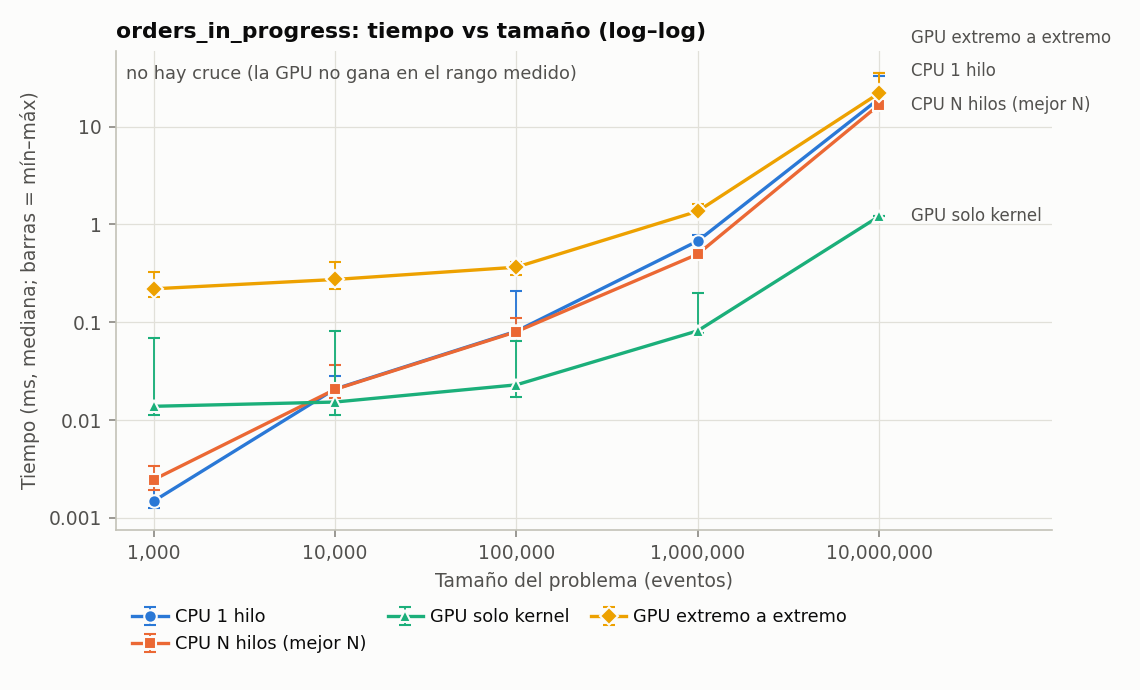

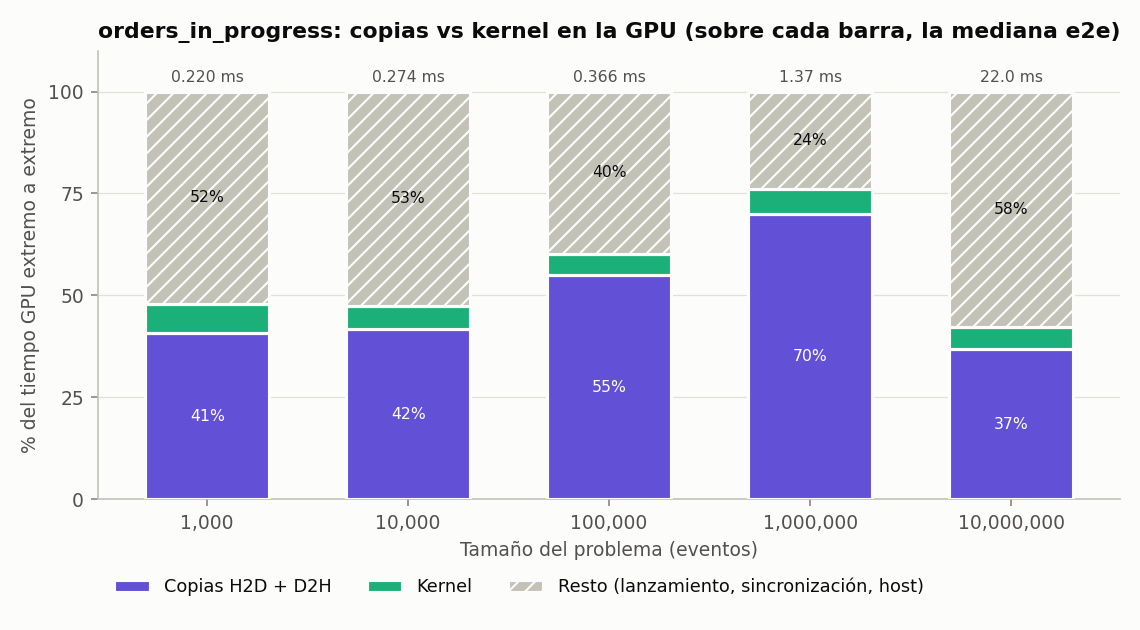

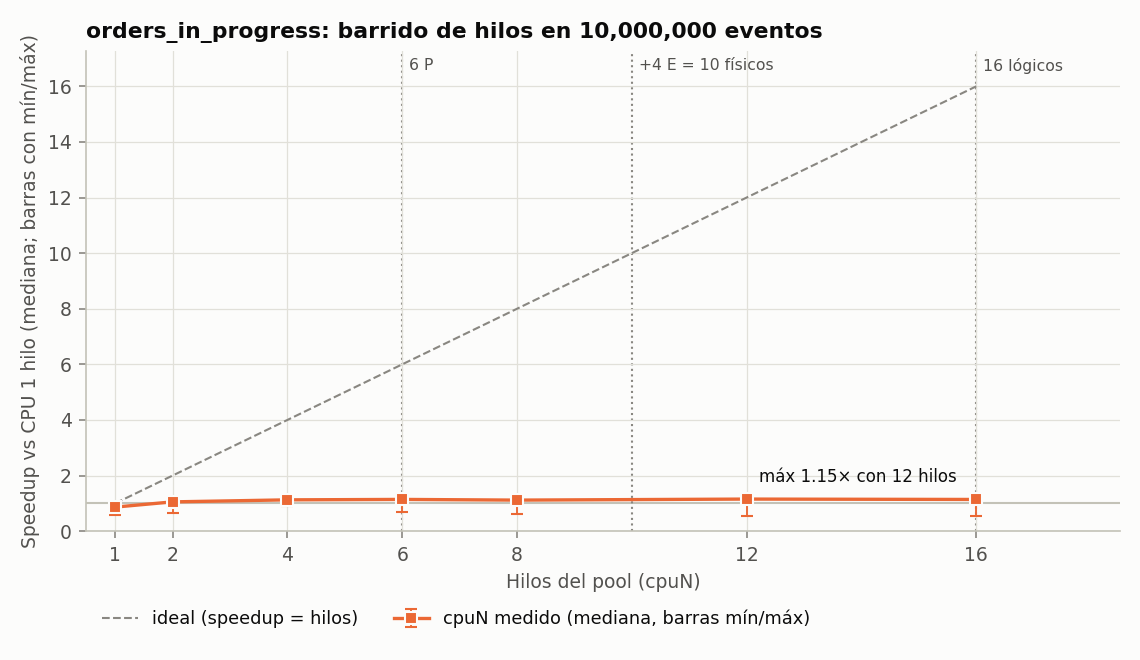

In [7]:
for app in ds.apps:
    meta = rl.app_meta(KERNELS, app)
    unit = meta.get("size_unit")
    display(Markdown(f"### {app}" + (f": {meta['title']}" if meta.get('title') else "")
                     + (f"\n\nSize = {meta['size_meaning']}." if meta.get('size_meaning') else "")))
    tbl, note = rl.app_table(cmp, app, unit)
    display(Markdown(rl.markdown_table(tbl) + "\n\n" + note))
    cross = rl.app_crossover(cmp, app)
    cross_k = rl.app_crossover(cmp, app, "gpu_kernel_ms")
    display(Markdown(f"- Crossover extremo a extremo: {cross.text(unit)} → **{rl.verdict(cross)}**\n"
                     f"- Crossover solo kernel: {cross_k.text(unit)}"))
    display(Markdown("**Dispersión**\n\n" + rl.markdown_table(rl.dispersion_table(cmp, app, unit))))
    size, sw = rl.thread_sweep(summ, app)
    if sw is not None and not sw.empty:
        display(Markdown(f"**Barrido de hilos ({rl.fmt_size(size, unit)})**\n\n" + rl.markdown_table(rl.sweep_table(sw))))
    for key in ("tiempo", "reparto", "hilos"):
        if figures[app].get(key):
            display(Image(filename=str(figures[app][key])))

## Roofline

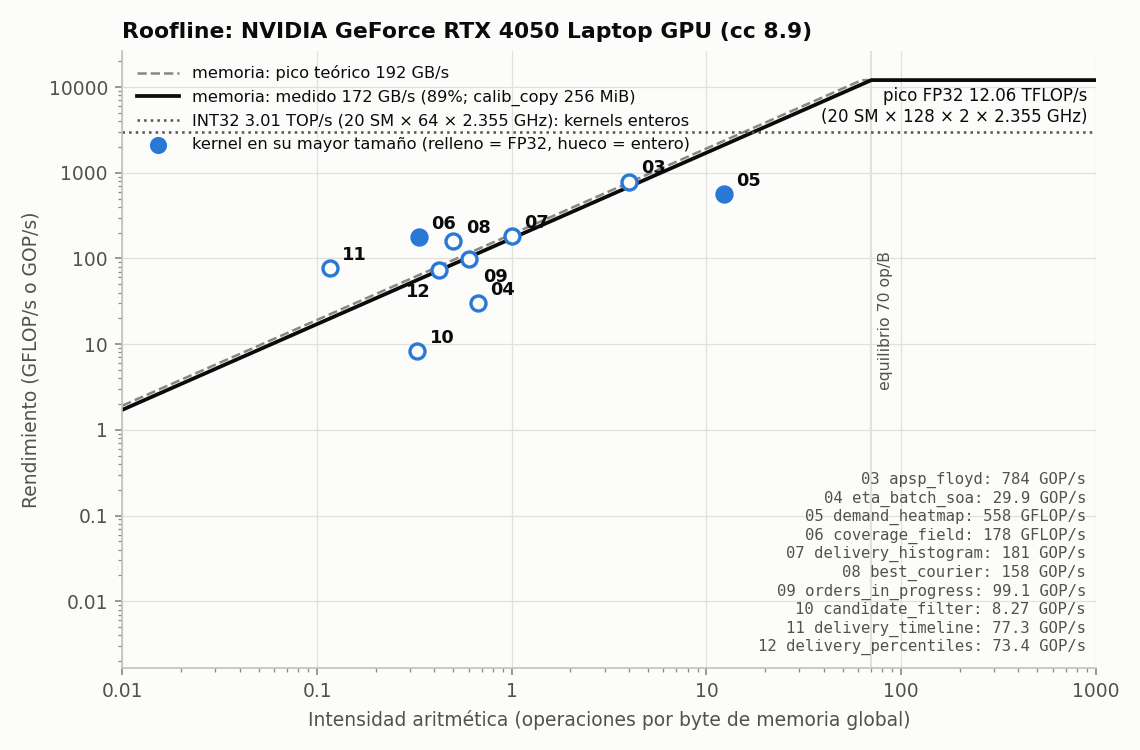

,application,size,op_type,ops,bytes,ai,kernel_ms,gops,gbs
0,apsp_floyd,25,int32,6.553600e+04,1.638400e+04,4.0,0.031744,2.064516,0.516129
1,apsp_floyd,100,int32,4.194304e+06,1.048576e+06,4.0,0.125440,33.436735,8.359184
2,apsp_floyd,400,int32,1.439826e+08,3.599565e+07,4.0,0.529648,271.845815,67.961454
3,apsp_floyd,1000,int32,2.147484e+09,5.368709e+08,4.0,3.644720,589.204012,147.301003
4,apsp_floyd,2000,int32,1.638708e+10,4.096770e+09,4.0,22.444929,730.101688,182.525422
...,...,...,...,...,...,...,...,...,...
89,orders_in_progress,1000,int32,1.200000e+04,2.000000e+04,0.6,0.013824,0.868056,1.446759
90,orders_in_progress,10000,int32,1.200000e+05,2.000000e+05,0.6,0.015280,7.853403,13.089005
91,orders_in_progress,100000,int32,1.200000e+06,2.000000e+06,0.6,0.022912,52.374302,87.290503
92,orders_in_progress,1000000,int32,1.200000e+07,2.000000e+07,0.6,0.081760,146.771037,244.618395


- **apsp_floyd**: ops = `2*(ceil(n/T)*T)**3`, bytes = `16*(ceil(n/T)*T)**3/T`. La tabla se rellena a N = ⌈n/32⌉·32. Por cada (pivote k, i, j) hay una suma y un mínimo enteros: 2N³ operaciones. Por tile pivote (N/T rondas) la fase 3, que domina, lanza (N/T − 1)² bloques que leen su celda, el tile de su fila y el de su columna (en shared) y escriben su celda: 4 × 4 B por celda = 16N² B por ronda; las fases 1 y 2 suman O(N·T) y se desprecian. Total 16N³/T B: intensidad T/8 = 4 op/B (sin tiles serían 16N³ B, 1/8 op/B).
- **apsp_dijkstra**: ops = `0`, bytes = `0`. Solo CPU: no va al roofline.
- **best_courier**: ops = `4*n*m`, bytes = `8*n*m + 8*m`. Por celda: empaquetar (ETA, id) en una clave de 64 bits (desplazamiento + o, 2 operaciones) y quedarse con la menor (comparación de 64 bits, ≈ 2): 4 operaciones enteras; el árbol del bloque agrega 255 por pedido (despreciable). Lee ETA e id de cada celda (4 + 4 B; los ids se releen por pedido, desde L2) y escribe una clave de 8 B por pedido.
- **best_courier_divergent**: ops = `4*n*m`, bytes = `8*n*m + 8*m`. Mismas operaciones y bytes; cambia qué hilos quedan activos en el árbol.
- **calib_copy**: ops = `0`, bytes = `2*n`. Cada byte se lee una vez de la VRAM y se escribe una vez: 2n bytes y ninguna operación. Da el techo MEDIDO de memoria (mayor tamaño, que no cabe en la L2).
- **calib_launch**: ops = `0`, bytes = `0`. Mide overhead, no cómputo: no va al roofline.
- **candidate_filter**: ops = `3*n + p*n`, bytes = `9*n + 4*p*n`. Por courier: ¿disponible? (1), índice en la tabla (1 IMAD), ¿tiempo ≤ radio? (1) y, para los p·n que pasan, un atomicAdd en shared. Lee disponibilidad (1 B), nodo (4 B) y un tiempo de la tabla (4 B, acceso disperso) y escribe 4 B por candidato. p ≈ 0,7 disponibles × 0,25 (radio = percentil 25) = 0,175.
- **candidate_filter_naive**: ops = `3*n + p*n`, bytes = `9*n + 4*p*n`. Mismas operaciones y bytes; los p·n atómicos van al MISMO contador global.
- **coverage_field**: ops = `4*S*n**2`, bytes = `12*S*n**2`. Por celda interior y barrido: 0,25 × (izq + der + arriba + abajo) = 3 sumas + 1 producto = 4 FLOP (fuentes y borde no calculan; se desprecia). Con reuso ideal de los vecinos en caché, cada barrido lee el campo anterior (4 B) y la grilla de couriers (4 B) y escribe el nuevo (4 B): 12 B por celda. Intensidad 1/3 FLOP/B: limitado por memoria; en grillas chicas, por los 200 lanzamientos.
- **delivery_histogram**: ops = `4*n`, bytes = `4*n`. Por entrega: calcular la barra (división por 60 000 y tope de desborde, ≈ 3 operaciones) + atomicAdd en shared (1): 4n operaciones enteras. Se lee cada tiempo una vez (4 B); las 61 sumas globales por bloque son despreciables. Intensidad 1 op/B.
- **histogram_naive**: ops = `4*n`, bytes = `4*n`. Mismas operaciones y lecturas; los n atómicos van a 61 direcciones de la L2 (contención, no tráfico de DRAM).
- **delivery_percentiles**: ops = `17*P*n`, bytes = `40*P*n`. Una pasada por bit significativo del máximo: con la distribución del bench (mediana 28 min, σ = 0,45) el máximo ronda 2^24-2^25 ms, P ≈ 25 pasadas. Por pasada y clave: marcar el bit (desplazar, enmascarar, comparar: 3 ops; lee 4 B y escribe 4 B), scan de las marcas (≈ 9 ops, 16 B como en la app 09) y reubicar (≈ 5 ops; lee clave, marca y suma: 12 B, escribe 4 B): 17 ops y 40 B por clave y pasada.
- **delivery_timeline**: ops = `R*(n + 0.5*n*log2(n))`, bytes = `R*(16*n + 4*n*log2(n))`. ⌈log2 2000⌉ = 11 rondas de fusión por pares. Por ronda cada registro de 8 B se lee y se escribe una vez (16n B) con una comparación por salida (n); cada hilo (4 salidas) hace 2 búsquedas co-rank de ≤ log2 n pasos que leen 8 B y comparan: n/4 · 2 · log2 n ≈ 0,5·n·log2 n comparaciones y 4·n·log2 n B. El conteo por hora (24 búsquedas binarias) es despreciable. Cota superior: las listas de las primeras rondas son cortas.
- **demand_heatmap**: ops = `2*K**2*n**2`, bytes = `8*n**2`. Cada celda hace K² = 49 productos y sumas (una FMA = 2 FLOP): 98n² FLOP (las celdas del borde hacen menos; se desprecia). Con reuso ideal en L1/L2 cada celda de entrada se lee una vez de DRAM (4 B) y la salida se escribe una vez (4 B): 8n² B; el filtro está en memoria constante. Intensidad 12,25 FLOP/B.
- **demand_heatmap_tiles**: ops = `2*K**2*n**2`, bytes = `4*n**2*((B+K-1)/B)**2 + 4*n**2`. Mismas operaciones. Cada bloque lee su tile con halo ((16+6)² celdas por 16² de salida, 1,89×) y escribe una vez.
- **eta_batch_soa**: ops = `8*n*m`, bytes = `12*n*m`. etaForPair (EtaFormula.h) por par: 2 índices de la tabla (2 IMAD), llegada = libre + viaje, recogida = max(llegada, listo), ETA = recogida + viaje, y 3 comparaciones contra 'inalcanzable': ≈ 8 operaciones enteras. Bytes con el modelo del propio bench (describe): por par se leen nodo y hora libre del courier (8 B) y se escribe la ETA (4 B) = 12 B; las dos lecturas de la tabla de tiempos (la del restaurante→cliente es la misma para todo el bloque) se suponen en caché, así que el tráfico real a DRAM puede ser mayor.
- **eta_batch_aos**: ops = `8*n*m`, bytes = `36*n*m`. Mismas operaciones que SoA; cada hilo usa 8 de los 32 B del registro, así que un warp trae 32 × 32 B en vez de 32 × 8 B: 32 + 4 = 36 B por par (modelo del bench).
- **orders_in_progress**: ops = `12*n`, bytes = `20*n`. Kogge-Stone en bloques de 512: en el paso de distancia d suman 512 − d hilos, Σ = 9·512 − 511 ≈ 8 sumas por elemento (trabajo O(n log n) del bloque); sumar el total de los bloques previos, 1; pico (empaquetar clave + máximo), ≈ 3: 12n operaciones. Bytes: el scan lee y escribe (8n), la corrección lee y escribe (8n) y el pico lee (4n): 20n; el scan de los totales de bloque es despreciable.

In [8]:
if figures.get("_roofline"):
    display(Image(filename=str(figures["_roofline"])))
pts = rl.roofline_points(summ, KERNELS)
display(pts if not pts.empty else Markdown("Sin kernels con operaciones aritméticas en este CSV (solo calibración)."))
display(Markdown("\n".join(f"- **{a}**: ops = `{rl.app_meta(KERNELS, a).get('ops')}`, bytes = `{rl.app_meta(KERNELS, a).get('bytes')}`. "
                            f"{rl.app_meta(KERNELS, a).get('derivation', '')}" for a in ds.apps if rl.app_meta(KERNELS, a))))

## Efecto en la simulación completa (sección 5)

| Métrica (media de las corridas; mín–máx) | --backend cpu | --backend auto (GPU) | GPU vs CPU |
|---|---|---|---|
| Latencia de despacho: media (ms) | 171 (166–177) | 425 (378–483) | +148% |
| Latencia p50 (ms) | 62.8 (61.5–65.0) | 137 (131–141) | +118% |
| Latencia p90 (ms) | 459 (443–474) | 1,156 (1,057–1,277) | +152% |
| Latencia p99 (ms) | 733 (712–758) | 1,963 (1,667–2,490) | +168% |
| Latencia máx. (ms) | 829 (786–889) | 4,990 (1,840–8,388) | +502% |
| Pedidos servidos por hora simulada | 642 (638–646) | 621 (616–626) | -3% |
| Pedidos creados | 2,149 (2,148–2,150) | 2,144 (2,144–2,144) | -0% |
| Pedidos asignados | 920 (919–922) | 910 (908–913) | -1% |
| Pedidos entregados | 321 (319–323) | 311 (308–313) | -3% |
| Pedidos rechazados | 1,228 (1,228–1,229) | 1,234 (1,231–1,236) | +0% |
| Cuadros por segundo (media) | 23.0 (22.8–23.1) | 22.9 (22.8–23.1) | -0% |
| Tiempo de dibujo p50 (ms) | 10.2 (9.97–10.4) | 10.2 (10.2–10.3) | +0% |
| Tiempo de dibujo p95 (ms) | 13.2 (12.1–14.6) | 13.4 (12.4–14.0) | +2% |
| Corridas que validan (tools/validate_log.py) | 3/3 | 3/3 |  |

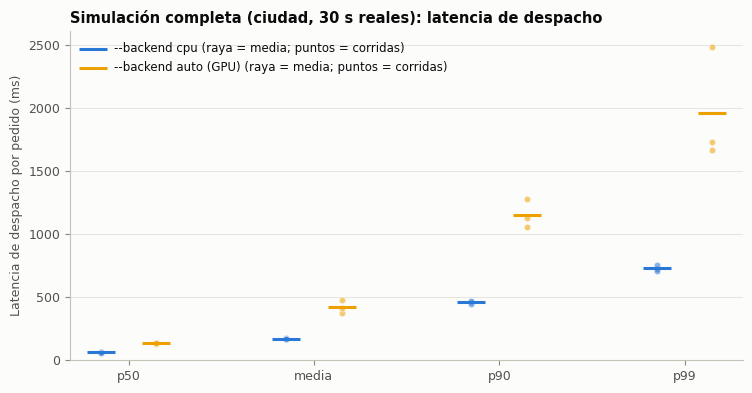

In [9]:
import matplotlib.pyplot as plt
sim_path = HERE / "data" / "final" / "sim_compare" / "sim_compare.csv"
if sim_path.exists():
    sim = rl.load_sim_compare(sim_path)
    display(Markdown(rl.markdown_table(rl.sim_table(sim))))
    fig = rl.plot_sim_latency(sim)
    display(fig)
    plt.close(fig)

## Robustez: misma sesión con 30 repeticiones

In [10]:
r30 = sorted((HERE / "data" / "final_r30").glob("*/bench.csv"))
if r30 and not os.environ.get("INFORME_CSV"):
    flips, stats = rl.robustness(ds, rl.load(r30), KERNELS)
    display(Markdown(f"Puntos comparables: **{stats['points']}**; cambios de ganador (mejor CPU vs GPU e2e): **{stats['flips']}**; "
                     f"diferencia de medianas en tiempos ≥ 1 ms: mediana {stats['diff_median']:.1%} "
                     f"(cuartiles {stats['diff_p25']:.1%}–{stats['diff_p75']:.1%})."))
    if not flips.empty:
        display(flips)

Puntos comparables: **99**; cambios de ganador (mejor CPU vs GPU e2e): **0**; diferencia de medianas en tiempos ≥ 1 ms: mediana 3.1% (cuartiles 1.0%–8.2%).